# Batched NumPy simulation of coupled Gumowski-Mira maps

This notebook uses the corrected Version 2 nonlinearity

$$
F(x,\mu)=\mu x+\frac{2(1-\mu)x^2}{1+x^2}.
$$

The implementation is designed to be stable in Jupyter on Windows:

- pure NumPy, with no Numba or multiprocessing;
- all values of $\mu$ are simulated simultaneously for one $\epsilon$ row;
- one $\epsilon$ row is held in memory at a time;
- each completed row is checkpointed to disk;
- interrupted scans resume automatically;
- the largest Lyapunov exponent, synchronization error, cluster number, and phase class are evaluated from the same initial state and reference trajectory;
- `VALIDATION`, `FAST`, and `FINAL` presets are available.

Run the notebook first with `RUN_MODE = "VALIDATION"`. Then use `FAST` to inspect the Version 2 phase organization. Use `FINAL` only after the first two modes succeed.

In [1]:
# ============================================================
# 1. IMPORTS, OUTPUTS, AND RUN MODE
# ============================================================

import json
from dataclasses import asdict, dataclass
from collections.abc import Mapping
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import BoundaryNorm, Colormap, ListedColormap, TwoSlopeNorm
from matplotlib.patches import Patch

MAP_VERSION = "GM_V2_x_squared"
GLOBAL_SEED = 20260905

# Start with VALIDATION, then FAST, and finally FINAL.
RUN_MODE = "FINAL"

# If False, completed checkpoint rows are loaded and skipped.
# If True, existing rows for the selected run signature are recomputed.
FORCE_RECOMPUTE = False

# Set to ("A",) or ("B",) to run one case only.
CASES_TO_RUN = ("A", "B")

OUTPUT_ROOT = Path("GMmaps_version2_batched_numpy")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

CASES = {
    "A": {"a": 0.01, "b": 0.05},
    "B": {"a": 0.33, "b": 0.10},
}

plt.rcParams.update(
    {
        # ====================================================
        # FONT FAMILY
        # ====================================================

        "font.family": "serif",
        "font.serif": [
            "Times New Roman",
            "Times",
            "DejaVu Serif",
        ],
        "mathtext.fontset": "stix",

        # ====================================================
        # MAIN TYPOGRAPHY
        # ====================================================

        "font.size": 12,
        "axes.labelsize": 14,
        "axes.titlesize": 15,
        "axes.titleweight": "semibold",

        # ====================================================
        # TICK LABELS
        # ====================================================

        "xtick.labelsize": 11,
        "ytick.labelsize": 11,

        # ====================================================
        # LEGEND
        # ====================================================

        "legend.fontsize": 10.5,
        "legend.title_fontsize": 10.5,

        # ====================================================
        # AXIS APPEARANCE
        # ====================================================

        "axes.linewidth": 1.0,

        "xtick.direction": "in",
        "ytick.direction": "in",

        "xtick.top": True,
        "ytick.right": True,

        "xtick.major.size": 5.5,
        "ytick.major.size": 5.5,

        "xtick.minor.size": 3.0,
        "ytick.minor.size": 3.0,

        "xtick.major.width": 0.9,
        "ytick.major.width": 0.9,

        "xtick.minor.width": 0.7,
        "ytick.minor.width": 0.7,

        # ====================================================
        # TICK PADDING
        # ====================================================

        "xtick.major.pad": 4.5,
        "ytick.major.pad": 4.5,

        # ====================================================
        # FIGURE AND OUTPUT QUALITY
        # ====================================================

        # This affects notebook display only.
        "figure.dpi": 180,

        # This controls saved raster figures unless overridden
        # in figure.savefig(...).
        "savefig.dpi": 600,

        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.04,

        # Preserve editable TrueType fonts in vector files.
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)

print("NumPy version:", np.__version__)
print("Output root:", OUTPUT_ROOT.resolve())

NumPy version: 2.4.6
Output root: C:\Users\em18702\OneDrive - AUT University\GMAP\GMmaps_version2_batched_numpy


In [2]:
# ============================================================
# 2. NUMERICAL PRESETS
# ============================================================

@dataclass(frozen=True)
class Config:
    grid_n: int
    network_size: int
    transient: int
    observation: int
    lyapunov_iterations: int
    cluster_samples: int
    mu_min: float = -0.6
    mu_max: float = 0.6
    eps_min: float = 0.0
    eps_max: float = 0.30
    delta0: float = 1.0e-8
    lambda_tolerance: float = 1.0e-3
    synchronization_tolerance: float = 1.0e-8
    cluster_tolerance: float = 5.0e-2
    fragmentation_threshold: int = 3
    escape_bound: float = 1.0e8
    seed: int = GLOBAL_SEED


PRESETS = {
    # Tiny end-to-end test.
    "VALIDATION": Config(
        grid_n=10,
        network_size=20,
        transient=100,
        observation=150,
        lyapunov_iterations=200,
        cluster_samples=4,
    ),

    # Preliminary Version 2 maps with manuscript network size.
    "FAST": Config(
        grid_n=50,
        network_size=50,
        transient=500,
        observation=700,
        lyapunov_iterations=1000,
        cluster_samples=8,
    ),

    # Stronger production calculation.
    "FINAL": Config(
        grid_n=500,
        network_size=50,
        transient=1500,
        observation=2000,
        lyapunov_iterations=3000,
        cluster_samples=20,
    ),
}

if RUN_MODE not in PRESETS:
    raise ValueError(f"Unknown RUN_MODE: {RUN_MODE}")

config = PRESETS[RUN_MODE]
MU_VALUES = np.linspace(config.mu_min, config.mu_max, config.grid_n)
EPSILON_VALUES = np.linspace(config.eps_min, config.eps_max, config.grid_n)
MU_COLUMN = MU_VALUES[:, None]

RUN_DIRECTORY = OUTPUT_ROOT / RUN_MODE.lower()
CHECKPOINT_DIRECTORY = RUN_DIRECTORY / "checkpoints"
FIGURE_DIRECTORY = RUN_DIRECTORY / "figures"
TABLE_DIRECTORY = RUN_DIRECTORY / "tables"

for directory in (RUN_DIRECTORY, CHECKPOINT_DIRECTORY, FIGURE_DIRECTORY, TABLE_DIRECTORY):
    directory.mkdir(parents=True, exist_ok=True)

print(json.dumps(asdict(config), indent=2))
print("Run directory:", RUN_DIRECTORY.resolve())
print("State-array shape per epsilon row:", (config.grid_n, config.network_size))

{
  "grid_n": 500,
  "network_size": 50,
  "transient": 1500,
  "observation": 2000,
  "lyapunov_iterations": 3000,
  "cluster_samples": 20,
  "mu_min": -0.6,
  "mu_max": 0.6,
  "eps_min": 0.0,
  "eps_max": 0.3,
  "delta0": 1e-08,
  "lambda_tolerance": 0.001,
  "synchronization_tolerance": 1e-08,
  "cluster_tolerance": 0.05,
  "fragmentation_threshold": 3,
  "escape_bound": 100000000.0,
  "seed": 20260905
}
Run directory: C:\Users\em18702\OneDrive - AUT University\GMAP\GMmaps_version2_batched_numpy\final
State-array shape per epsilon row: (500, 50)


## Model and diagnostics

The state arrays use shape `(number_of_mu_values, network_size)`. Thus, one call updates every $\mu$ value at a fixed $\epsilon$. The synchronization error and clusters use the $x$ coordinate, matching the original manuscript convention.

In [3]:
# ============================================================
# 3. CORRECT VERSION 2 MAP AND BATCHED RING UPDATE
# ============================================================

def F_v2(x, mu):
    """Correct Version 2 bounded nonlinearity."""
    return mu*x + 2.0*(1.0-mu)*x*x/(1.0+x*x)


def coupled_step_batch(X, Y, mu_column, a, b, epsilon):
    """
    Advance all mu values for one epsilon row.

    Parameters
    ----------
    X, Y : ndarray, shape (number_of_mu_values, network_size)
    mu_column : ndarray, shape (number_of_mu_values, 1)
    """
    local_update = a*Y*(1.0-b*Y*Y) + Y + F_v2(X, mu_column)
    left_neighbors = np.roll(X, shift=1, axis=1)
    right_neighbors = np.roll(X, shift=-1, axis=1)
    X_next = (
        (1.0-epsilon)*local_update
        + 0.5*epsilon*(left_neighbors+right_neighbors)
    )
    Y_next = -X + F_v2(X_next, mu_column)
    return X_next, Y_next


def valid_rows(X, Y, escape_bound):
    """Return one validity flag for each mu row."""
    finite = np.all(np.isfinite(X), axis=1) & np.all(np.isfinite(Y), axis=1)
    with np.errstate(invalid="ignore"):
        bounded = (
            np.max(np.abs(X), axis=1) <= escape_bound
        ) & (
            np.max(np.abs(Y), axis=1) <= escape_bound
        )
    return finite & bounded


def synchronization_error_batch(X):
    """X-based synchronization error for every mu row."""
    row_means = np.mean(X, axis=1, keepdims=True)
    return np.mean((X-row_means)**2, axis=1)


def cluster_number_batch(X, tolerance):
    """
    X-based one-dimensional single-linkage cluster count.

    Sorting each row and counting gaps larger than the tolerance is
    equivalent to one-dimensional single-linkage clustering.
    """
    sorted_x = np.sort(X, axis=1)
    gaps = np.diff(sorted_x, axis=1)
    return 1 + np.sum(gaps > tolerance, axis=1)


def classify_phase_batch(lambda_values, sync_values, cluster_values, valid, cfg):
    """
    Phase codes:
      0 undefined
      1 synchronized periodic
      2 synchronized neutral
      3 synchronized chaotic
      4 periodic cluster
      5 neutral cluster
      6 chaotic cluster
      7 incoherent
    """
    phase = np.zeros(lambda_values.shape, dtype=np.int16)
    good = (
        valid
        & np.isfinite(lambda_values)
        & np.isfinite(sync_values)
        & np.isfinite(cluster_values)
    )
    synchronized = good & (sync_values <= cfg.synchronization_tolerance) & (cluster_values == 1)
    low_cluster = good & (~synchronized) & (cluster_values <= cfg.fragmentation_threshold)
    fragmented = good & (~synchronized) & (~low_cluster)

    periodic = lambda_values < -cfg.lambda_tolerance
    neutral = np.abs(lambda_values) <= cfg.lambda_tolerance
    chaotic = lambda_values > cfg.lambda_tolerance

    phase[synchronized & periodic] = 1
    phase[synchronized & neutral] = 2
    phase[synchronized & chaotic] = 3
    phase[low_cluster & periodic] = 4
    phase[low_cluster & neutral] = 5
    phase[low_cluster & chaotic] = 6
    phase[fragmented] = 7
    return phase

print("Batched Version 2 model and diagnostic functions loaded.")

Batched Version 2 model and diagnostic functions loaded.


## One epsilon-row evaluator

The reference and perturbed networks begin from the same batch of initial conditions. Both are propagated through the same transient. The tangent displacement is normalized separately for every $\mu$ row after every iteration.

In [4]:
# ============================================================
# 4. EVALUATE ONE EPSILON ROW
# ============================================================

def evaluate_epsilon_row(
    case_name,
    epsilon,
    epsilon_index,
    mu_values,
    cfg,
):
    """Evaluate every mu value for one fixed epsilon."""
    parameters = CASES[case_name]
    number_of_mu = len(mu_values)
    network_size = cfg.network_size
    mu_column = mu_values[:, None]

    case_offset = 0 if case_name == "A" else 10_000_000
    rng = np.random.default_rng(cfg.seed + case_offset + epsilon_index*100_000)

    # Independent network initial state for every mu row.
    X = rng.uniform(-1.0, 1.0, size=(number_of_mu, network_size))
    Y = rng.uniform(-1.0, 1.0, size=(number_of_mu, network_size))

    # Independent perturbation direction for every mu row.
    dX = rng.normal(size=(number_of_mu, network_size))
    dY = rng.normal(size=(number_of_mu, network_size))
    direction_norm = np.sqrt(np.sum(dX*dX+dY*dY, axis=1))
    direction_norm = np.maximum(direction_norm, 1.0e-300)
    dX *= (cfg.delta0/direction_norm)[:, None]
    dY *= (cfg.delta0/direction_norm)[:, None]

    Xp = X+dX
    Yp = Y+dY
    active = np.ones(number_of_mu, dtype=bool)

    # Transient applied to the same reference and perturbed trajectories.
    for _ in range(cfg.transient):
        with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
            X, Y = coupled_step_batch(X, Y, mu_column, parameters["a"], parameters["b"], epsilon)
            Xp, Yp = coupled_step_batch(Xp, Yp, mu_column, parameters["a"], parameters["b"], epsilon)

        active &= valid_rows(X, Y, cfg.escape_bound)
        active &= valid_rows(Xp, Yp, cfg.escape_bound)

        dX = Xp-X
        dY = Yp-Y
        distance = np.sqrt(np.sum(dX*dX+dY*dY, axis=1))
        active &= np.isfinite(distance) & (distance > 1.0e-300)

        safe_distance = np.where(active, distance, 1.0)
        scale = cfg.delta0/safe_distance
        Xp = X+dX*scale[:, None]
        Yp = Y+dY*scale[:, None]

        # Keep invalid rows numerically quiet.
        X[~active] = 0.0
        Y[~active] = 0.0
        Xp[~active] = 0.0
        Yp[~active] = 0.0

        if not np.any(active):
            break

    total_steps = max(cfg.observation, cfg.lyapunov_iterations)
    lyapunov_sum = np.zeros(number_of_mu)
    lyapunov_count = np.zeros(number_of_mu, dtype=int)
    sync_sum = np.zeros(number_of_mu)
    sync_count = np.zeros(number_of_mu, dtype=int)
    cluster_sum = np.zeros(number_of_mu)
    cluster_count = np.zeros(number_of_mu, dtype=int)

    cluster_indices = set(
        np.linspace(
            0,
            cfg.observation-1,
            min(cfg.cluster_samples, cfg.observation),
            dtype=int,
        ).tolist()
    )

    for step in range(total_steps):
        with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
            X, Y = coupled_step_batch(X, Y, mu_column, parameters["a"], parameters["b"], epsilon)
            Xp, Yp = coupled_step_batch(Xp, Yp, mu_column, parameters["a"], parameters["b"], epsilon)

        active &= valid_rows(X, Y, cfg.escape_bound)
        active &= valid_rows(Xp, Yp, cfg.escape_bound)

        dX = Xp-X
        dY = Yp-Y
        distance = np.sqrt(np.sum(dX*dX+dY*dY, axis=1))
        active &= np.isfinite(distance) & (distance > 1.0e-300)
        safe_distance = np.where(active, distance, 1.0)

        if step < cfg.lyapunov_iterations:
            lyapunov_sum[active] += np.log(safe_distance[active]/cfg.delta0)
            lyapunov_count[active] += 1

        scale = cfg.delta0/safe_distance
        Xp = X+dX*scale[:, None]
        Yp = Y+dY*scale[:, None]

        if step < cfg.observation:
            current_sync = synchronization_error_batch(X)
            sync_sum[active] += current_sync[active]
            sync_count[active] += 1

            if step in cluster_indices:
                current_clusters = cluster_number_batch(X, cfg.cluster_tolerance)
                cluster_sum[active] += current_clusters[active]
                cluster_count[active] += 1

        X[~active] = 0.0
        Y[~active] = 0.0
        Xp[~active] = 0.0
        Yp[~active] = 0.0

        if not np.any(active):
            break

    lambda_row = np.full(number_of_mu, np.nan)
    sync_row = np.full(number_of_mu, np.nan)
    cluster_row = np.full(number_of_mu, np.nan)

    lambda_ok = active & (lyapunov_count > 0)
    sync_ok = active & (sync_count > 0)
    cluster_ok = active & (cluster_count > 0)

    lambda_row[lambda_ok] = lyapunov_sum[lambda_ok]/lyapunov_count[lambda_ok]
    sync_row[sync_ok] = sync_sum[sync_ok]/sync_count[sync_ok]
    cluster_row[cluster_ok] = np.rint(cluster_sum[cluster_ok]/cluster_count[cluster_ok])

    final_valid = active & lambda_ok & sync_ok & cluster_ok
    phase_row = classify_phase_batch(lambda_row, sync_row, cluster_row, final_valid, cfg)

    return {
        "lambda_max": lambda_row,
        "sync_error": sync_row,
        "cluster_number": cluster_row,
        "phase": phase_row,
        "valid": final_valid,
    }

print("One-row evaluator loaded.")

One-row evaluator loaded.


## Tiny smoke tests

Run this cell before starting any grid. It checks shapes, bounded execution, and diagnostic output.

In [5]:
# ============================================================
# 5. SMOKE TESTS
# ============================================================

def run_smoke_tests():
    X = np.array([[0.1, -0.2, 0.3, -0.4], [0.2, 0.1, -0.1, -0.2]])
    Y = np.array([[-0.1, 0.2, -0.3, 0.4], [0.3, -0.2, 0.2, -0.1]])
    mu_column = np.array([[0.0], [0.1]])
    Xn, Yn = coupled_step_batch(X, Y, mu_column, 0.01, 0.05, 0.02)
    assert Xn.shape == X.shape and Yn.shape == Y.shape
    assert synchronization_error_batch(X).shape == (2,)
    assert cluster_number_batch(X, 0.05).shape == (2,)

    tiny_config = Config(
        grid_n=3,
        network_size=8,
        transient=5,
        observation=6,
        lyapunov_iterations=7,
        cluster_samples=2,
    )
    result = evaluate_epsilon_row(
        case_name="A",
        epsilon=0.01,
        epsilon_index=0,
        mu_values=np.linspace(-0.1, 0.1, 3),
        cfg=tiny_config,
    )
    assert set(result) == {"lambda_max", "sync_error", "cluster_number", "phase", "valid"}
    assert all(np.asarray(value).shape == (3,) for value in result.values())
    print("Smoke tests passed.")
    print(pd.DataFrame(result))

run_smoke_tests()

Smoke tests passed.
   lambda_max  sync_error  cluster_number  phase  valid
0    0.414702    4.892142             8.0      7   True
1    0.321827    5.192779             8.0      7   True
2    0.440019    1.778219             8.0      7   True


## Checkpointed two-parameter scan

Every completed $\epsilon$ row is saved independently. Rerunning the notebook with `FORCE_RECOMPUTE = False` resumes from the first missing row.

In [6]:
# ============================================================
# 6. CHECKPOINT MANAGEMENT AND COMPLETE SCAN
# ============================================================

def run_signature(case_name, cfg):
    return (
        f"{MAP_VERSION}_Case{case_name}_GRID{cfg.grid_n}"
        f"_N{cfg.network_size}_TR{cfg.transient}"
        f"_OBS{cfg.observation}_LY{cfg.lyapunov_iterations}"
        f"_SEED{cfg.seed}"
    )


def row_checkpoint_path(case_name, epsilon_index, cfg):
    directory = CHECKPOINT_DIRECTORY/run_signature(case_name, cfg)
    directory.mkdir(parents=True, exist_ok=True)
    return directory/f"epsilon_row_{epsilon_index:04d}.npz"


def save_row_checkpoint(path, epsilon, result):
    np.savez_compressed(
        path,
        epsilon=np.array(epsilon),
        lambda_max=result["lambda_max"],
        sync_error=result["sync_error"],
        cluster_number=result["cluster_number"],
        phase=result["phase"],
        valid=result["valid"],
    )


def load_row_checkpoint(path):
    loaded = np.load(path)
    return {
        "lambda_max": loaded["lambda_max"],
        "sync_error": loaded["sync_error"],
        "cluster_number": loaded["cluster_number"],
        "phase": loaded["phase"],
        "valid": loaded["valid"].astype(bool),
    }


def scan_case_checkpointed(case_name, cfg, force=False):
    shape = (cfg.grid_n, cfg.grid_n)
    LE = np.full(shape, np.nan)
    SYNC = np.full(shape, np.nan)
    CLUSTERS = np.full(shape, np.nan)
    PHASE = np.zeros(shape, dtype=np.int16)
    VALID = np.zeros(shape, dtype=bool)

    row_times = []
    scan_start = perf_counter()

    for epsilon_index, epsilon in enumerate(EPSILON_VALUES):
        checkpoint = row_checkpoint_path(case_name, epsilon_index, cfg)
        row_start = perf_counter()

        if checkpoint.exists() and not force:
            result = load_row_checkpoint(checkpoint)
            status = "loaded"
        else:
            result = evaluate_epsilon_row(
                case_name=case_name,
                epsilon=float(epsilon),
                epsilon_index=epsilon_index,
                mu_values=MU_VALUES,
                cfg=cfg,
            )
            save_row_checkpoint(checkpoint, epsilon, result)
            status = "computed"

        LE[epsilon_index] = result["lambda_max"]
        SYNC[epsilon_index] = result["sync_error"]
        CLUSTERS[epsilon_index] = result["cluster_number"]
        PHASE[epsilon_index] = result["phase"]
        VALID[epsilon_index] = result["valid"]

        elapsed_row = perf_counter()-row_start
        row_times.append(elapsed_row)
        mean_row_time = np.mean(row_times[-10:])
        remaining = (cfg.grid_n-epsilon_index-1)*mean_row_time
        print(
            f"Case {case_name} row {epsilon_index+1:>3}/{cfg.grid_n}: "
            f"{status}, {elapsed_row:6.2f} s, ETA {remaining/60:6.1f} min"
        )

    print(f"Case {case_name} total elapsed: {(perf_counter()-scan_start)/60:.2f} min")
    return {
        "mu": MU_VALUES.copy(),
        "epsilon": EPSILON_VALUES.copy(),
        "LE": LE,
        "SYNC": SYNC,
        "CLUSTERS": CLUSTERS,
        "PHASE": PHASE,
        "VALID": VALID,
    }

print("Checkpointed scan functions loaded.")

Checkpointed scan functions loaded.


## Run the selected cases

In [7]:
# ============================================================
# 7. RUN OR RESUME THE SCANS
# ============================================================

network_results = {}

for case_name in CASES_TO_RUN:
    print(f"\nStarting Case {case_name} in {RUN_MODE} mode")
    network_results[case_name] = scan_case_checkpointed(
        case_name=case_name,
        cfg=config,
        force=FORCE_RECOMPUTE,
    )

metadata = {
    "map_version": MAP_VERSION,
    "map_equation": "mu*x + 2*(1-mu)*x**2/(1+x**2)",
    "run_mode": RUN_MODE,
    "cases_run": list(CASES_TO_RUN),
    "cases": CASES,
    "config": asdict(config),
    "diagnostic_consistency": (
        "lambda_max, synchronization error, cluster number, and phase "
        "classification use the same initial state and reference trajectory"
    ),
}

(RUN_DIRECTORY/"simulation_metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

print("All selected scans completed or loaded.")


Starting Case A in FINAL mode
Case A row   1/500: loaded,   0.04 s, ETA    0.3 min
Case A row   2/500: loaded,   0.03 s, ETA    0.3 min
Case A row   3/500: loaded,   0.03 s, ETA    0.3 min
Case A row   4/500: loaded,   0.03 s, ETA    0.3 min
Case A row   5/500: loaded,   0.03 s, ETA    0.3 min
Case A row   6/500: loaded,   0.03 s, ETA    0.2 min
Case A row   7/500: loaded,   0.03 s, ETA    0.2 min
Case A row   8/500: loaded,   0.02 s, ETA    0.2 min
Case A row   9/500: loaded,   0.03 s, ETA    0.2 min
Case A row  10/500: loaded,   0.03 s, ETA    0.2 min
Case A row  11/500: loaded,   0.03 s, ETA    0.2 min
Case A row  12/500: loaded,   0.03 s, ETA    0.2 min
Case A row  13/500: loaded,   0.03 s, ETA    0.2 min
Case A row  14/500: loaded,   0.03 s, ETA    0.2 min
Case A row  15/500: loaded,   0.03 s, ETA    0.2 min
Case A row  16/500: loaded,   0.03 s, ETA    0.2 min
Case A row  17/500: loaded,   0.03 s, ETA    0.2 min
Case A row  18/500: loaded,   0.02 s, ETA    0.2 min
Case A row  19/

## Save assembled arrays and complete CSV tables

In [8]:
# ============================================================
# 8. EXPORT NUMERICAL RESULTS
# ============================================================

PHASE_LABELS = {
    0: "Undefined",
    1: "Synchronized periodic",
    2: "Synchronized neutral",
    3: "Synchronized chaotic",
    4: "Periodic cluster",
    5: "Neutral cluster",
    6: "Chaotic cluster",
    7: "Incoherent",
}

for case_name, result in network_results.items():
    assembled_path = RUN_DIRECTORY/f"assembled_{run_signature(case_name, config)}.npz"
    np.savez_compressed(
        assembled_path,
        mu=result["mu"],
        epsilon=result["epsilon"],
        LE=result["LE"],
        SYNC=result["SYNC"],
        CLUSTERS=result["CLUSTERS"],
        PHASE=result["PHASE"],
        VALID=result["VALID"],
    )

    mu_grid, epsilon_grid = np.meshgrid(result["mu"], result["epsilon"])
    frame = pd.DataFrame({
        "case": case_name,
        "mu": mu_grid.ravel(),
        "epsilon": epsilon_grid.ravel(),
        "lambda_max": result["LE"].ravel(),
        "sync_error": result["SYNC"].ravel(),
        "cluster_number": result["CLUSTERS"].ravel(),
        "phase_code": result["PHASE"].ravel(),
        "valid": result["VALID"].ravel(),
    })
    frame["phase_label"] = frame["phase_code"].map(PHASE_LABELS)
    frame.to_csv(TABLE_DIRECTORY/f"Case{case_name}_Version2_network_scan.csv", index=False)

    summary = (
        frame.groupby(["phase_code", "phase_label"], dropna=False)
        .size().rename("count").reset_index()
    )
    summary["fraction"] = summary["count"]/len(frame)
    summary.to_csv(TABLE_DIRECTORY/f"Case{case_name}_phase_fraction_summary.csv", index=False)
    display(summary)

print("Numerical arrays and CSV tables saved.")

,phase_code,phase_label,count,fraction
0,1,Synchronized periodic,132632,0.530528
1,4,Periodic cluster,6348,0.025392
2,5,Neutral cluster,151,0.000604
3,6,Chaotic cluster,1205,0.004820
4,7,Incoherent,109664,0.438656


,phase_code,phase_label,count,fraction
0,1,Synchronized periodic,14430,0.057720
1,2,Synchronized neutral,5,0.000020
2,4,Periodic cluster,3076,0.012304
3,5,Neutral cluster,805,0.003220
4,6,Chaotic cluster,780,0.003120
5,7,Incoherent,230904,0.923616


Numerical arrays and CSV tables saved.


## Publication-ready maps

In [20]:
# ============================================================
# ORIGINAL-PAPER COLOR PALETTE AND SHARED AXIS STYLE
# ============================================================

# Continuous diagnostic maps:
# - signed Lyapunov exponents: diverging and centred at zero;
# - nonnegative synchronization error: perceptually uniform sequential;
# - integer cluster count: sequential palette sampled discretely.

LYAPUNOV_CMAP = "turbo"
SYNCHRONIZATION_CMAP = "turbo"
CLUSTER_CMAP = "viridis"

#LYAPUNOV_CMAP = "RdBu_r"
#SYNCHRONIZATION_CMAP = "viridis"
#CLUSTER_CMAP = "viridis"

# Expanded version of the original collective-state palette.
# The principal original colors are retained:
#   blue: synchronized periodic
#   red: periodic cluster
#   pink: chaotic cluster
#   cyan: incoherent
PHASE_COLORS = [
    "#FFFFFF",  # 0: Undefined
    "#1F77B4",  # 1: Synchronized periodic
    "#6BAED6",  # 2: Synchronized neutral
    "#9467BD",  # 3: Synchronized chaotic
    "#D62728",  # 4: Periodic cluster
    "#7F7F7F",  # 5: Neutral cluster
    "#E377C2",  # 6: Chaotic cluster
    "#17BECF",  # 7: Incoherent
]

PHASE_CMAP = ListedColormap(PHASE_COLORS, name="manuscript_collective_states")
PHASE_NORM = BoundaryNorm(np.arange(-0.5, 8.5, 1.0), PHASE_CMAP.N)

# Shared typography for the publication maps.
TITLE_FONT_SIZE = 15
SUPTITLE_FONT_SIZE = 16
AXIS_LABEL_FONT_SIZE = 14
TICK_FONT_SIZE = 11
PANEL_LABEL_FONT_SIZE = 14
COLORBAR_LABEL_FONT_SIZE = 13
COLORBAR_TICK_FONT_SIZE = 10.5
PHASE_COLORBAR_FONT_SIZE = 10
LEGEND_FONT_SIZE = 10.5

FIGURE_SIZE = (12.0, 9.2)
NEUTRAL_COLOR = (0.72, 0.72, 0.72, 1.0)
INVALID_COLOR = "#F2F2F2"


def style_parameter_axis(axis):
    """Apply common publication formatting to a parameter-space panel."""
    axis.set_xlabel(r"$\mu$", fontsize=AXIS_LABEL_FONT_SIZE, labelpad=7)
    axis.set_ylabel(r"$\epsilon$", fontsize=AXIS_LABEL_FONT_SIZE, labelpad=7)
    axis.tick_params(
        which="major", direction="in", top=True, right=True,
        labelsize=TICK_FONT_SIZE, length=6, width=1.0,
    )
    axis.tick_params(
        which="minor", direction="in", top=True, right=True,
        length=3, width=0.8,
    )
    axis.minorticks_on()


print("Manuscript palettes and shared publication axis styling loaded.")


Manuscript palettes and shared publication axis styling loaded.


## Combined publication-ready four-panel figures

Generate one composite parameter-space figure for each completed case. The panels show the largest Lyapunov exponent, synchronization error, cluster number, and collective-state classification. The Lyapunov panel uses a display-only piecewise mapping that reserves a visible 12% neutral band; the underlying numerical values and regime classification are not changed. The parameter-grid cell edges are used with `pcolormesh` to represent the sampled parameter cells accurately. Each case is exported as PDF, 600-dpi PNG, and EPS, with diagnostic counts and a final output-file check.

Case A: 1500 neutral points (0.600% of valid points); displayed LE range [-0.169088, 0.392535].
Saved Case A:
C:\Users\em18702\OneDrive - AUT University\GMAP\GMmaps_version2_batched_numpy\final\figures\CaseA_Version2_network_summary_visible_neutral.pdf
C:\Users\em18702\OneDrive - AUT University\GMAP\GMmaps_version2_batched_numpy\final\figures\CaseA_Version2_network_summary_visible_neutral.png
C:\Users\em18702\OneDrive - AUT University\GMAP\GMmaps_version2_batched_numpy\final\figures\CaseA_Version2_network_summary_visible_neutral.eps


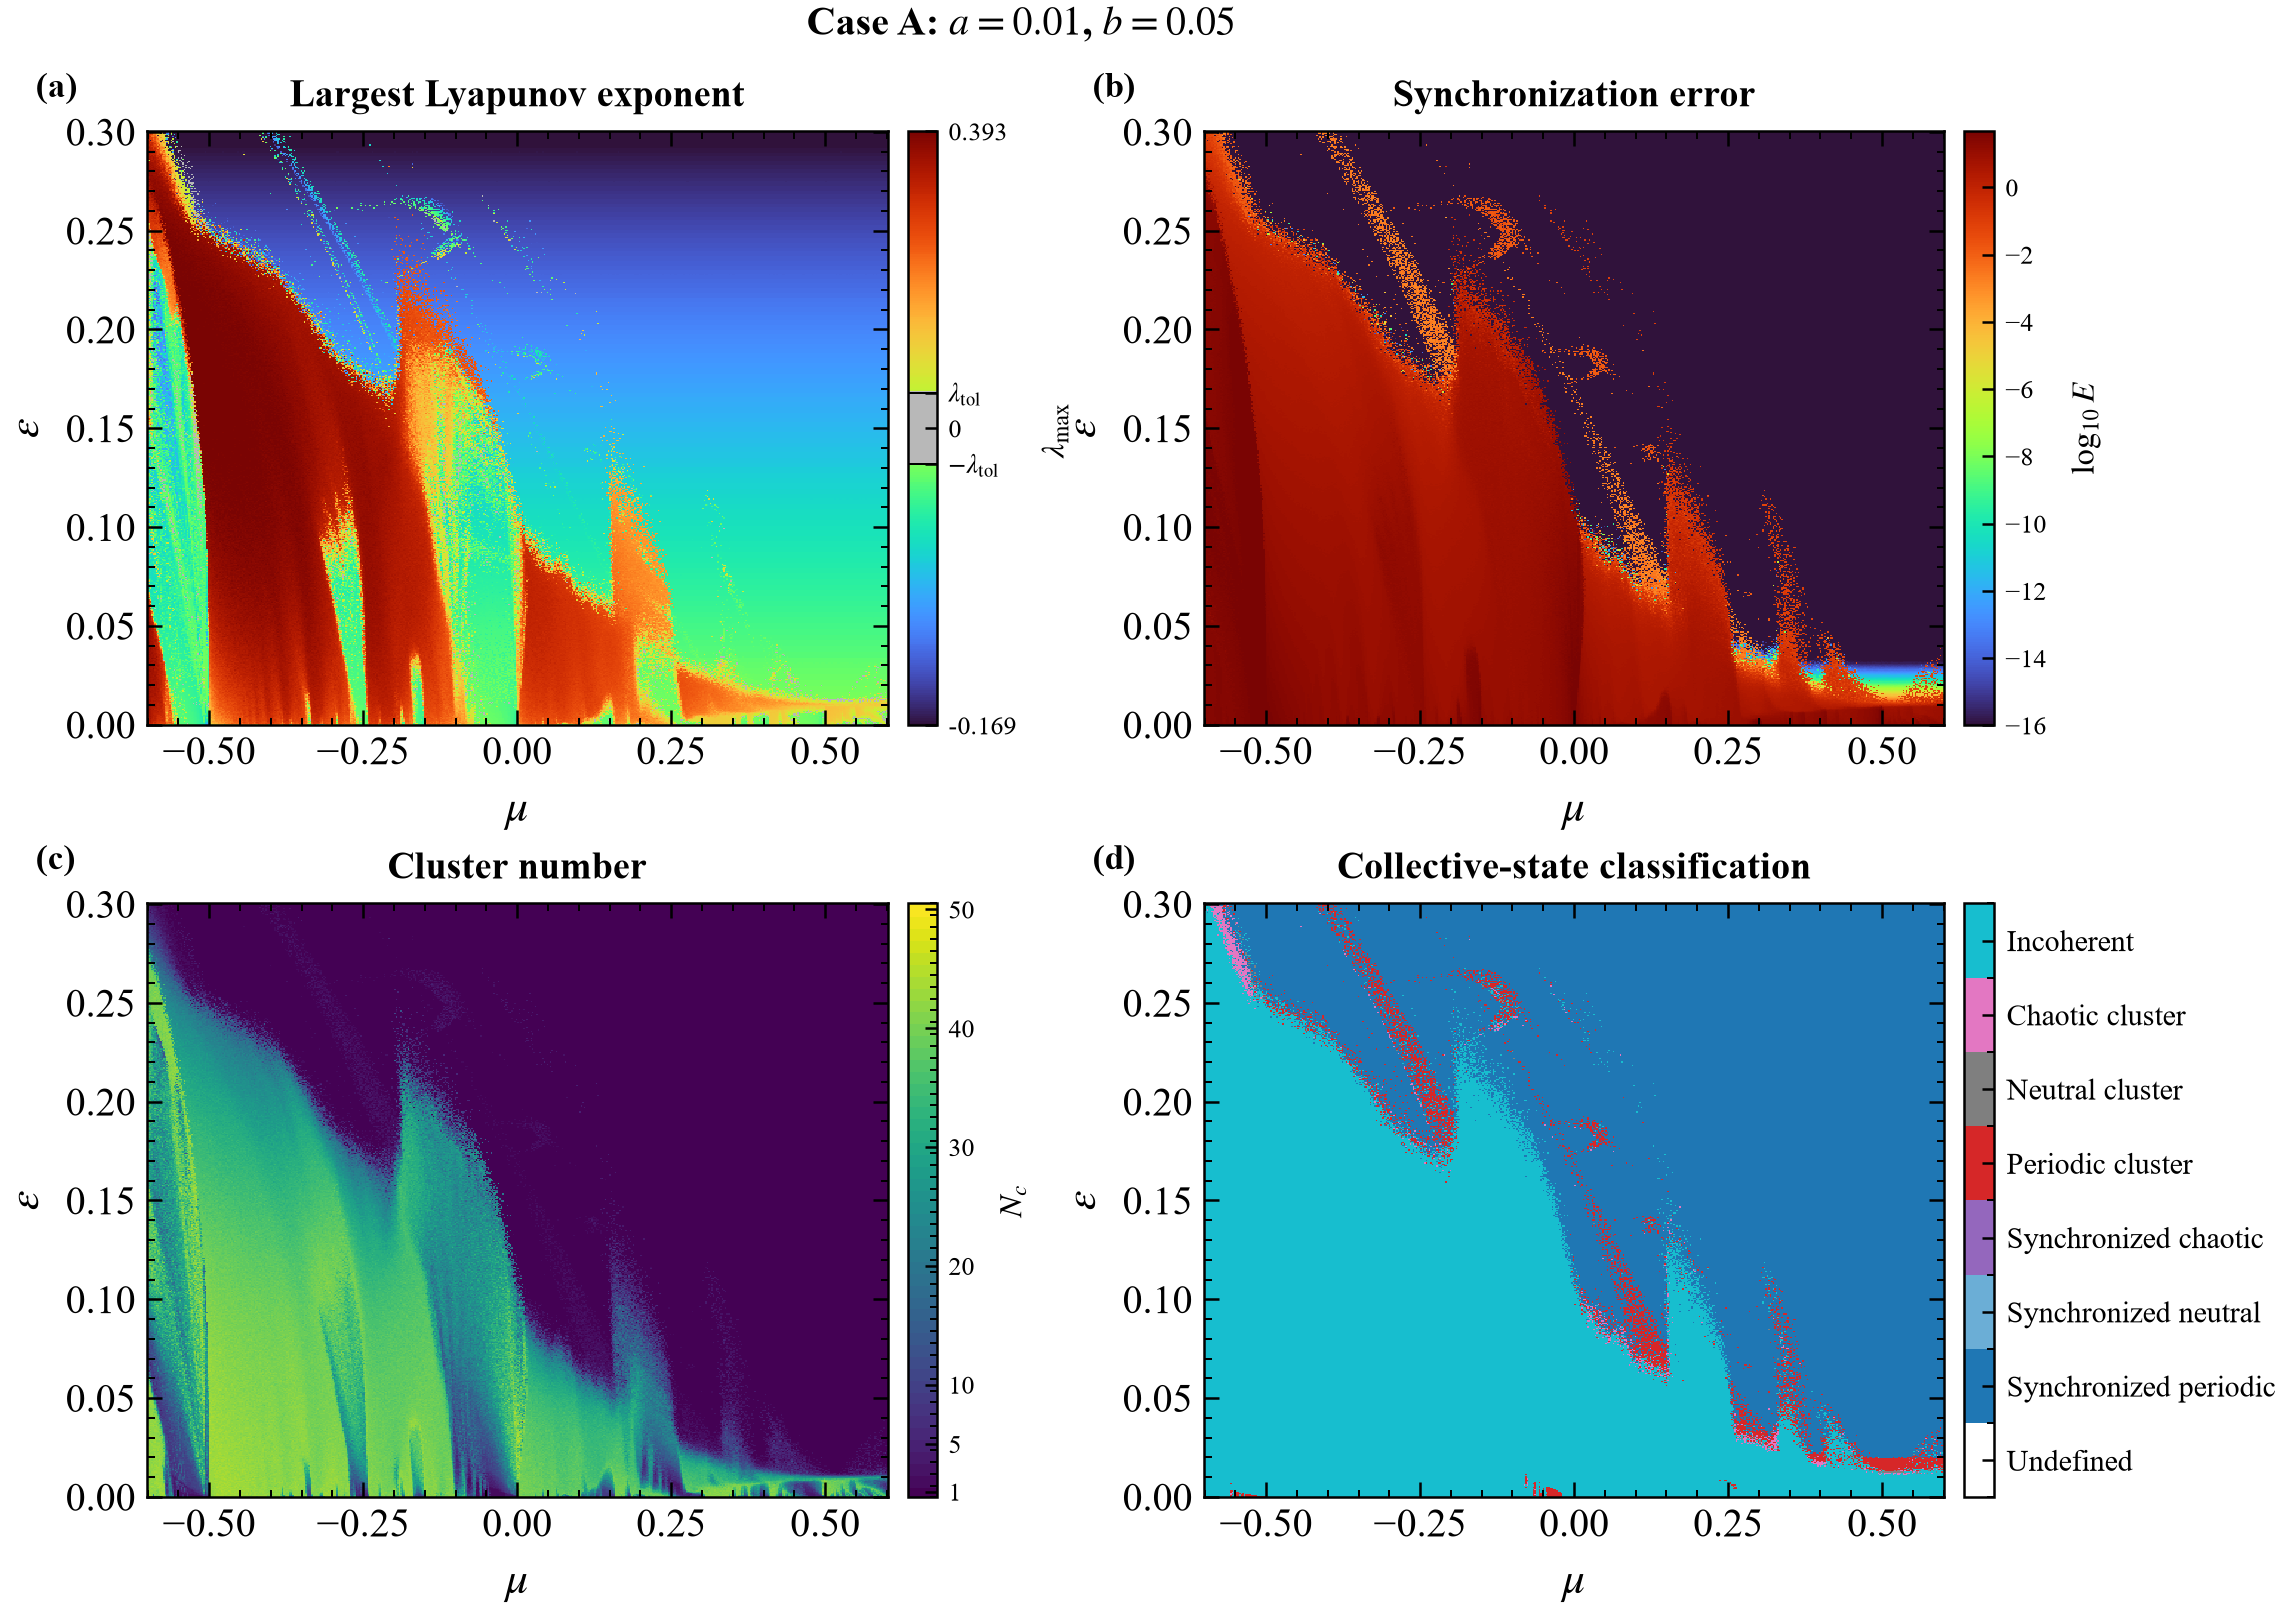

Case B: 15912 neutral points (6.365% of valid points); displayed LE range [-0.291006, 0.411154].
Saved Case B:
C:\Users\em18702\OneDrive - AUT University\GMAP\GMmaps_version2_batched_numpy\final\figures\CaseB_Version2_network_summary_visible_neutral.pdf
C:\Users\em18702\OneDrive - AUT University\GMAP\GMmaps_version2_batched_numpy\final\figures\CaseB_Version2_network_summary_visible_neutral.png
C:\Users\em18702\OneDrive - AUT University\GMAP\GMmaps_version2_batched_numpy\final\figures\CaseB_Version2_network_summary_visible_neutral.eps


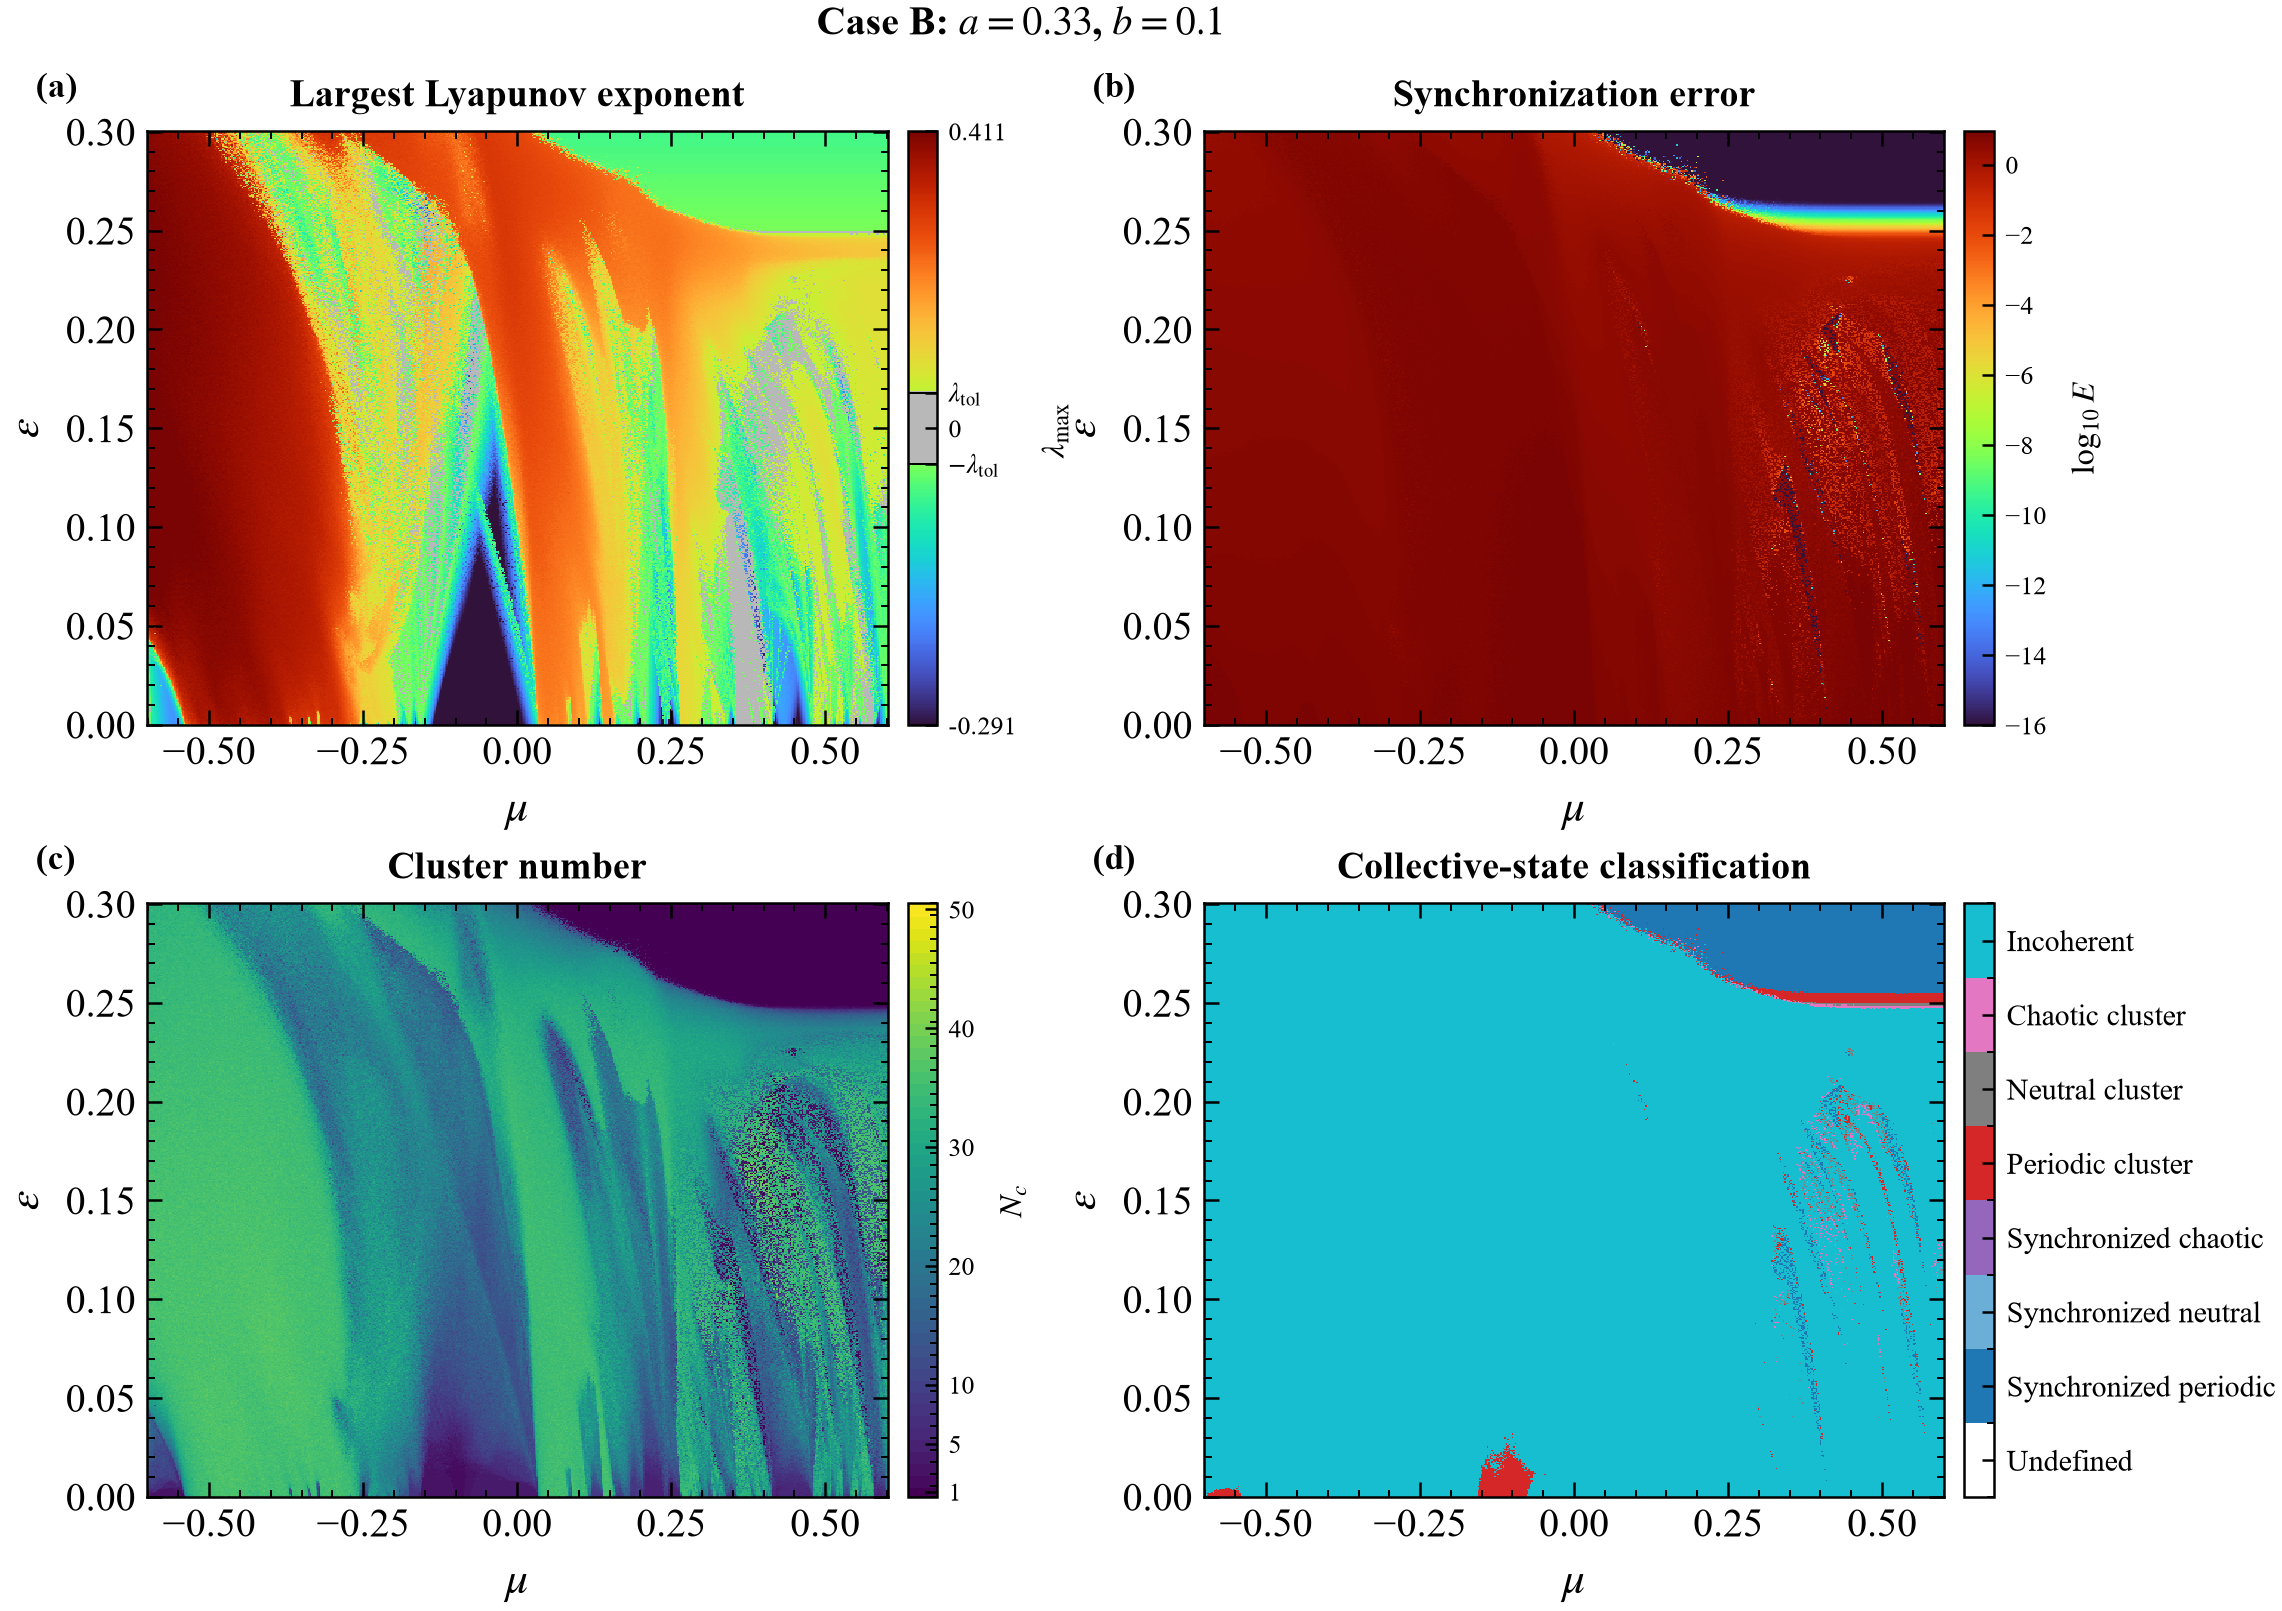


Final output-file check:
[OK]      GMmaps_version2_batched_numpy\final\figures\CaseA_Version2_network_summary_visible_neutral.pdf
[OK]      GMmaps_version2_batched_numpy\final\figures\CaseA_Version2_network_summary_visible_neutral.png
[OK]      GMmaps_version2_batched_numpy\final\figures\CaseA_Version2_network_summary_visible_neutral.eps
[OK]      GMmaps_version2_batched_numpy\final\figures\CaseB_Version2_network_summary_visible_neutral.pdf
[OK]      GMmaps_version2_batched_numpy\final\figures\CaseB_Version2_network_summary_visible_neutral.png
[OK]      GMmaps_version2_batched_numpy\final\figures\CaseB_Version2_network_summary_visible_neutral.eps

All corrected four-panel figures were generated.
Output directory:
C:\Users\em18702\OneDrive - AUT University\GMAP\GMmaps_version2_batched_numpy\final\figures


In [21]:
# ============================================================
# CORRECTED FOUR-PANEL PARAMETER-SPACE FIGURES
# VISIBLE NEUTRAL BAND, MANUSCRIPT COLORS, CLEAN COLORBARS
# ============================================================

from pathlib import Path
from collections.abc import Mapping

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import BoundaryNorm, Colormap, ListedColormap

# ============================================================
# 1. VISUAL SETTINGS
# ============================================================

FIGURE_SIZE = (12.0, 9.2)
SUPTITLE_FONT_SIZE = 16
PANEL_TITLE_FONT_SIZE = 15
AXIS_LABEL_FONT_SIZE = 18
AXIS_TICK_FONT_SIZE = 16
PANEL_LABEL_FONT_SIZE = 14
COLORBAR_LABEL_FONT_SIZE = 13
COLORBAR_TICK_FONT_SIZE = 10.5
PHASE_COLORBAR_FONT_SIZE = 12



NEUTRAL_COLOR = (0.72, 0.72, 0.72, 1.00)
INVALID_COLOR = "#F2F2F2"

# Reserve 12% of the displayed Lyapunov scale for the neutral regime.
# This changes only the visual mapping, not the data or classification.
NEUTRAL_DISPLAY_LOWER = 0.44
NEUTRAL_DISPLAY_UPPER = 0.56
LYAPUNOV_COLOR_LEVELS = 256

plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "font.size": 12,
        "axes.labelsize": AXIS_LABEL_FONT_SIZE,
        "axes.titlesize": PANEL_TITLE_FONT_SIZE,
        "axes.linewidth": 1.0,
        "xtick.labelsize": AXIS_TICK_FONT_SIZE,
        "ytick.labelsize": AXIS_TICK_FONT_SIZE,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.top": True,
        "ytick.right": True,
        "xtick.major.size": 6,
        "ytick.major.size": 6,
        "xtick.minor.size": 3,
        "ytick.minor.size": 3,
        "xtick.major.width": 1.0,
        "ytick.major.width": 1.0,
        "xtick.minor.width": 0.8,
        "ytick.minor.width": 0.8,
        "figure.dpi": 180,
        "savefig.dpi": 600,
        "savefig.bbox": "tight",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)

# ============================================================
# 2. CHECK REQUIRED OBJECTS
# ============================================================

required_objects = [
    "network_results",
    "config",
    "CASES",
    "FIGURE_DIRECTORY",
    "LYAPUNOV_CMAP",
    "SYNCHRONIZATION_CMAP",
    "CLUSTER_CMAP",
    "PHASE_CMAP",
    "PHASE_NORM",
    "PHASE_LABELS",
]

missing_objects = [
    name for name in required_objects if name not in globals()
]
if missing_objects:
    raise RuntimeError(
        "Run the parameter-scan and colormap cells first. Missing: "
        + ", ".join(missing_objects)
    )

FIGURE_DIRECTORY = Path(FIGURE_DIRECTORY)
FIGURE_DIRECTORY.mkdir(parents=True, exist_ok=True)

# ============================================================
# 3. GENERAL HELPERS
# ============================================================

def get_config_value(cfg, name):
    """Read a setting from either an object or mapping."""
    if hasattr(cfg, name):
        return getattr(cfg, name)
    if isinstance(cfg, Mapping) and name in cfg:
        return cfg[name]
    raise AttributeError(f"The configuration does not contain {name!r}.")


def resolve_colormap(colormap):
    """Resolve a Matplotlib colormap name or colormap object."""
    if isinstance(colormap, str):
        try:
            return plt.get_cmap(colormap)
        except ValueError as error:
            raise ValueError(
                f"Unknown Matplotlib colormap: {colormap!r}"
            ) from error
    if isinstance(colormap, Colormap) or callable(colormap):
        return colormap
    raise TypeError(
        "Expected a Matplotlib colormap name or object. "
        f"Received: {colormap!r}"
    )


LAMBDA_TOLERANCE = float(
    get_config_value(config, "lambda_tolerance")
)
NETWORK_SIZE = int(get_config_value(config, "network_size"))

if not np.isfinite(LAMBDA_TOLERANCE) or LAMBDA_TOLERANCE <= 0.0:
    raise ValueError("lambda_tolerance must be finite and positive.")
if NETWORK_SIZE < 1:
    raise ValueError("network_size must be a positive integer.")

MANUSCRIPT_LYAPUNOV_CMAP = resolve_colormap(LYAPUNOV_CMAP)
MANUSCRIPT_SYNCHRONIZATION_CMAP = resolve_colormap(
    SYNCHRONIZATION_CMAP
)
MANUSCRIPT_CLUSTER_CMAP = resolve_colormap(CLUSTER_CMAP)
MANUSCRIPT_PHASE_CMAP = resolve_colormap(PHASE_CMAP)


def style_parameter_axis(axis):
    """Apply the common publication style to a parameter-space axis."""
    axis.set_xlabel(r"$\mu$", labelpad=7)
    axis.set_ylabel(r"$\epsilon$", labelpad=7)
    axis.tick_params(
        which="major",
        direction="in",
        top=True,
        right=True,
        length=6,
        width=1.0,
        labelsize=AXIS_TICK_FONT_SIZE,
    )
    axis.tick_params(
        which="minor",
        direction="in",
        top=True,
        right=True,
        length=3,
        width=0.8,
    )
    axis.minorticks_on()


def style_colorbar(
    colorbar,
    label,
    label_size=COLORBAR_LABEL_FONT_SIZE,
    tick_size=COLORBAR_TICK_FONT_SIZE,
):
    """Apply consistent publication formatting to a colorbar."""
    colorbar.set_label(
        label,
        fontsize=label_size,
        labelpad=10,
    )
    colorbar.ax.tick_params(
        which="major",
        direction="in",
        length=5,
        width=1.0,
        labelsize=tick_size,
    )
    colorbar.outline.set_linewidth(1.0)


def coordinate_edges(values):
    """Return cell-edge coordinates for a monotone grid of centers."""
    values = np.asarray(values, dtype=float)
    if values.ndim != 1 or values.size < 2:
        raise ValueError("Coordinate arrays must be 1D with at least two values.")
    differences = np.diff(values)
    if not np.all(differences > 0.0):
        raise ValueError("Coordinate arrays must be strictly increasing.")
    edges = np.empty(values.size + 1, dtype=float)
    edges[1:-1] = 0.5 * (values[:-1] + values[1:])
    edges[0] = values[0] - 0.5 * differences[0]
    edges[-1] = values[-1] + 0.5 * differences[-1]
    return edges


def validate_case_result(case_name, result):
    """Validate one case and return consistently typed arrays."""
    required_keys = {
        "mu", "epsilon", "LE", "SYNC", "CLUSTERS", "PHASE", "VALID"
    }
    missing_keys = required_keys - set(result)
    if missing_keys:
        raise KeyError(
            f"Case {case_name} is missing: {sorted(missing_keys)}"
        )

    mu_values = np.asarray(result["mu"], dtype=float)
    epsilon_values = np.asarray(result["epsilon"], dtype=float)

    if mu_values.ndim != 1 or epsilon_values.ndim != 1:
        raise ValueError("mu and epsilon arrays must be one-dimensional.")
    if mu_values.size < 2 or epsilon_values.size < 2:
        raise ValueError(
            "mu and epsilon arrays must each contain at least two values."
        )
    if not np.all(np.isfinite(mu_values)):
        raise ValueError("mu must contain only finite values.")
    if not np.all(np.isfinite(epsilon_values)):
        raise ValueError("epsilon must contain only finite values.")
    if not np.all(np.diff(mu_values) > 0.0):
        raise ValueError(f"Case {case_name}: mu must be strictly increasing.")
    if not np.all(np.diff(epsilon_values) > 0.0):
        raise ValueError(
            f"Case {case_name}: epsilon must be strictly increasing."
        )

    expected_shape = (epsilon_values.size, mu_values.size)
    arrays = {}
    for key in ["LE", "SYNC", "CLUSTERS", "PHASE", "VALID"]:
        array = np.asarray(result[key])
        if array.shape != expected_shape:
            raise ValueError(
                f"Case {case_name}: result[{key!r}] has shape "
                f"{array.shape}; expected {expected_shape}."
            )
        arrays[key] = array

    arrays["VALID"] = arrays["VALID"].astype(bool)
    return mu_values, epsilon_values, arrays

# ============================================================
# 4. VISIBLE-NEUTRAL LYAPUNOV DISPLAY
# ============================================================

def build_lyapunov_display(
    values,
    tolerance,
    neutral_lower=NEUTRAL_DISPLAY_LOWER,
    neutral_upper=NEUTRAL_DISPLAY_UPPER,
    color_levels=LYAPUNOV_COLOR_LEVELS,
):
    """
    Apply a display-only piecewise transformation.

    Values below -tolerance map to [0, neutral_lower].
    Neutral values map to [neutral_lower, neutral_upper].
    Values above +tolerance map to [neutral_upper, 1].
    """
    if not 0.0 < neutral_lower < neutral_upper < 1.0:
        raise ValueError(
            "Neutral display bounds must satisfy "
            "0 < lower < upper < 1."
        )
    if not np.isfinite(tolerance) or tolerance <= 0.0:
        raise ValueError("tolerance must be finite and positive.")
    if int(color_levels) < 3:
        raise ValueError("color_levels must be at least three.")

    values = np.asarray(values, dtype=float)
    finite = values[np.isfinite(values)]

    if finite.size:
        lower_limit = min(
            float(np.percentile(finite, 2.0)),
            -1.01 * tolerance,
        )
        upper_limit = max(
            float(np.percentile(finite, 98.0)),
            1.01 * tolerance,
        )
    else:
        lower_limit = -10.0 * tolerance
        upper_limit = 10.0 * tolerance

    if not np.isfinite(lower_limit) or lower_limit >= -tolerance:
        lower_limit = -10.0 * tolerance
    if not np.isfinite(upper_limit) or upper_limit <= tolerance:
        upper_limit = 10.0 * tolerance

    transformed = np.full(values.shape, np.nan, dtype=float)
    finite_mask = np.isfinite(values)
    negative_mask = finite_mask & (values < -tolerance)
    neutral_mask = finite_mask & (np.abs(values) <= tolerance)
    positive_mask = finite_mask & (values > tolerance)

    transformed[negative_mask] = neutral_lower * (
        values[negative_mask] - lower_limit
    ) / (-tolerance - lower_limit)
    transformed[negative_mask] = np.clip(
        transformed[negative_mask], 0.0, neutral_lower
    )

    transformed[neutral_mask] = neutral_lower + (
        values[neutral_mask] + tolerance
    ) * (neutral_upper - neutral_lower) / (2.0 * tolerance)

    transformed[positive_mask] = neutral_upper + (
        1.0 - neutral_upper
    ) * (values[positive_mask] - tolerance) / (
        upper_limit - tolerance
    )
    transformed[positive_mask] = np.clip(
        transformed[positive_mask], neutral_upper, 1.0
    )

    negative_levels = max(
        1, int(round(neutral_lower * color_levels))
    )
    neutral_levels = max(
        1,
        int(round((neutral_upper - neutral_lower) * color_levels)),
    )
    positive_levels = max(
        1,
        int(color_levels) - negative_levels - neutral_levels,
    )

    negative_colors = MANUSCRIPT_LYAPUNOV_CMAP(
        np.linspace(0.00, 0.45, negative_levels)
    )
    neutral_colors = np.tile(
        np.asarray(NEUTRAL_COLOR, dtype=float),
        (neutral_levels, 1),
    )
    positive_colors = MANUSCRIPT_LYAPUNOV_CMAP(
        np.linspace(0.55, 1.00, positive_levels)
    )

    colors = np.vstack(
        [negative_colors, neutral_colors, positive_colors]
    )
    cmap = ListedColormap(
        colors,
        name="visible_neutral_lyapunov",
    )
    cmap.set_bad(INVALID_COLOR)

    ticks = [
        0.0,
        neutral_lower,
        0.5 * (neutral_lower + neutral_upper),
        neutral_upper,
        1.0,
    ]
    labels = [
        f"{lower_limit:.3g}",
        r"$-\lambda_{\mathrm{tol}}$",
        "0",
        r"$\lambda_{\mathrm{tol}}$",
        f"{upper_limit:.3g}",
    ]

    neutral_count = int(np.count_nonzero(neutral_mask))
    return (
        np.ma.masked_invalid(transformed),
        cmap,
        ticks,
        labels,
        lower_limit,
        upper_limit,
        neutral_count,
    )

# ============================================================
# 5. DISCRETE CLUSTER COLOR SCALE
# ============================================================

def build_cluster_scale(network_size):
    """Create a discrete color for each integer cluster count."""
    sample_positions = (
        np.arange(network_size, dtype=float) + 0.5
    ) / network_size
    colors = np.asarray(
        MANUSCRIPT_CLUSTER_CMAP(sample_positions),
        dtype=float,
    ).copy()
    colors[0] = MANUSCRIPT_CLUSTER_CMAP(0.0)

    cmap = ListedColormap(
        colors,
        name="manuscript_discrete_clusters",
    )
    cmap.set_bad(INVALID_COLOR)

    boundaries = np.arange(0.5, network_size + 1.5, 1.0)
    if boundaries.size - 1 != cmap.N:
        raise RuntimeError("Cluster boundary/color mismatch.")

    norm = BoundaryNorm(boundaries, cmap.N, clip=False)

    if network_size <= 20:
        ticks = list(range(1, network_size + 1))
    else:
        ticks = sorted(
            {
                int(value)
                for value in [1, 5, 10, 20, 30, 40, network_size]
                if 1 <= value <= network_size
            }
        )

    return cmap, norm, boundaries, ticks

# ============================================================
# 6. FOUR-PANEL FIGURE
# ============================================================

def plot_case_summary(case_name, result, cfg):
    """Create and save the four-panel parameter-space summary."""
    mu_values, epsilon_values, arrays = validate_case_result(
        case_name,
        result,
    )
    tolerance = float(get_config_value(cfg, "lambda_tolerance"))
    network_size = int(get_config_value(cfg, "network_size"))

    if network_size != NETWORK_SIZE:
        raise ValueError(
            f"Case {case_name}: network_size changed from "
            f"{NETWORK_SIZE} to {network_size}."
        )

    mu_edges = coordinate_edges(mu_values)
    epsilon_edges = coordinate_edges(epsilon_values)
    valid = arrays["VALID"]

    figure, axes = plt.subplots(
        2,
        2,
        figsize=FIGURE_SIZE,
        constrained_layout=False,
    )

    # Panel (a): largest Lyapunov exponent.
    le_values = np.where(
        valid,
        np.asarray(arrays["LE"], dtype=float),
        np.nan,
    )
    (
        le_display,
        le_cmap,
        le_ticks,
        le_labels,
        le_lower,
        le_upper,
        neutral_count,
    ) = build_lyapunov_display(le_values, tolerance)

    image = axes[0, 0].pcolormesh(
        mu_edges,
        epsilon_edges,
        le_display,
        cmap=le_cmap,
        vmin=0.0,
        vmax=1.0,
        shading="flat",
        rasterized=True,
    )
    axes[0, 0].set_title("Largest Lyapunov exponent", pad=10)
    colorbar = figure.colorbar(
        image,
        ax=axes[0, 0],
        pad=0.025,
        fraction=0.050,
        ticks=le_ticks,
    )
    style_colorbar(colorbar, r"$\lambda_{\max}$")
    colorbar.ax.set_yticklabels(le_labels)
    for boundary in [
        NEUTRAL_DISPLAY_LOWER,
        NEUTRAL_DISPLAY_UPPER,
    ]:
        colorbar.ax.axhline(
            boundary,
            color="black",
            linewidth=0.8,
        )

    valid_count = int(np.count_nonzero(valid))
    neutral_percentage = (
        100.0 * neutral_count / valid_count
        if valid_count
        else np.nan
    )
    print(
        f"Case {case_name}: {neutral_count} neutral points "
        f"({neutral_percentage:.3f}% of valid points); "
        f"displayed LE range [{le_lower:.6g}, {le_upper:.6g}]."
    )

    # Panel (b): synchronization error.
    sync_values = np.where(
        valid,
        np.asarray(arrays["SYNC"], dtype=float),
        np.nan,
    )
    sync_values = np.where(sync_values >= 0.0, sync_values, np.nan)
    log_sync = np.log10(sync_values + 1.0e-16)
    finite_sync = log_sync[np.isfinite(log_sync)]

    if finite_sync.size:
        sync_min = float(np.percentile(finite_sync, 2.0))
        sync_max = float(np.percentile(finite_sync, 98.0))
        if sync_max <= sync_min:
            sync_min = float(np.min(finite_sync))
            sync_max = float(np.max(finite_sync))
        if sync_max <= sync_min:
            sync_min -= 1.0e-6
            sync_max += 1.0e-6
    else:
        sync_min, sync_max = -16.0, 0.0

    image = axes[0, 1].pcolormesh(
        mu_edges,
        epsilon_edges,
        np.ma.masked_invalid(log_sync),
        cmap=MANUSCRIPT_SYNCHRONIZATION_CMAP,
        vmin=sync_min,
        vmax=sync_max,
        shading="flat",
        rasterized=True,
    )
    axes[0, 1].set_title("Synchronization error", pad=10)

    tick_start = np.ceil(sync_min / 2.0) * 2.0
    tick_end = np.floor(sync_max / 2.0) * 2.0
    sync_ticks = (
        np.arange(tick_start, tick_end + 0.1, 2.0)
        if tick_end >= tick_start
        else None
    )
    colorbar = figure.colorbar(
        image,
        ax=axes[0, 1],
        pad=0.025,
        fraction=0.050,
        ticks=sync_ticks,
    )
    style_colorbar(colorbar, r"$\log_{10}E$")

    # Panel (c): integer cluster number.
    cluster_values = np.where(
        valid,
        np.rint(np.asarray(arrays["CLUSTERS"], dtype=float)),
        np.nan,
    )
    finite_clusters = cluster_values[np.isfinite(cluster_values)]
    if finite_clusters.size:
        observed_min = int(np.min(finite_clusters))
        observed_max = int(np.max(finite_clusters))
        if observed_min < 1 or observed_max > network_size:
            raise ValueError(
                f"Case {case_name}: cluster range "
                f"[{observed_min}, {observed_max}] lies outside "
                f"[1, {network_size}]."
            )

    (
        cluster_cmap,
        cluster_norm,
        cluster_bounds,
        cluster_ticks,
    ) = build_cluster_scale(network_size)

    image = axes[1, 0].pcolormesh(
        mu_edges,
        epsilon_edges,
        np.ma.masked_invalid(cluster_values),
        cmap=cluster_cmap,
        norm=cluster_norm,
        shading="flat",
        rasterized=True,
    )
    axes[1, 0].set_title("Cluster number", pad=10)
    colorbar = figure.colorbar(
        image,
        ax=axes[1, 0],
        pad=0.025,
        fraction=0.050,
        ticks=cluster_ticks,
        boundaries=cluster_bounds,
        spacing="uniform",
    )
    style_colorbar(colorbar, r"$N_c$")
    colorbar.ax.set_yticklabels(
        [str(int(value)) for value in cluster_ticks]
    )
    if colorbar.solids is not None:
        colorbar.solids.set_edgecolor("face")

    # Panel (d): collective-state classification.
    phase_raw = np.asarray(arrays["PHASE"], dtype=float)
    phase_values = np.where(valid, phase_raw, np.nan)

    if isinstance(PHASE_LABELS, Mapping):
        phase_codes = sorted(int(code) for code in PHASE_LABELS.keys())
        phase_labels = [str(PHASE_LABELS[code]) for code in phase_codes]
    else:
        phase_codes = list(range(len(PHASE_LABELS)))
        phase_labels = [str(value) for value in PHASE_LABELS]

    finite_phase = phase_values[np.isfinite(phase_values)]
    unknown_phase_codes = sorted(
        set(np.rint(finite_phase).astype(int)) - set(phase_codes)
    )
    if unknown_phase_codes:
        raise ValueError(
            f"Case {case_name}: PHASE contains codes with no label: "
            + ", ".join(map(str, unknown_phase_codes))
        )

    phase_cmap = MANUSCRIPT_PHASE_CMAP.copy()
    phase_cmap.set_bad(INVALID_COLOR)

    image = axes[1, 1].pcolormesh(
        mu_edges,
        epsilon_edges,
        np.ma.masked_invalid(phase_values),
        cmap=phase_cmap,
        norm=PHASE_NORM,
        shading="flat",
        rasterized=True,
    )
    axes[1, 1].set_title(
        "Collective-state classification",
        pad=10,
    )
    colorbar = figure.colorbar(
        image,
        ax=axes[1, 1],
        pad=0.025,
        fraction=0.050,
        ticks=phase_codes,
    )
    colorbar.ax.set_yticklabels(phase_labels)
    colorbar.ax.tick_params(
        which="major",
        direction="in",
        length=5,
        width=1.0,
        labelsize=PHASE_COLORBAR_FONT_SIZE,
        pad=5,
    )
    colorbar.outline.set_linewidth(1.0)

    # Common formatting.
    for panel_label, axis in zip(
        ("(a)", "(b)", "(c)", "(d)"),
        axes.flat,
    ):
        style_parameter_axis(axis)
        axis.set_xlim(mu_edges[0], mu_edges[-1])
        axis.set_ylim(epsilon_edges[0], epsilon_edges[-1])
        axis.text(
            -0.15,
            1.045,
            panel_label,
            transform=axis.transAxes,
            fontsize=PANEL_LABEL_FONT_SIZE,
            fontweight="bold",
            ha="left",
            va="bottom",
        )

    parameters = CASES[case_name]
    figure.suptitle(
        rf"Case {case_name}: $a={parameters['a']}$, "
        rf"$b={parameters['b']}$",
        fontsize=SUPTITLE_FONT_SIZE,
        fontweight="bold",
        y=0.985,
    )
    figure.subplots_adjust(
        left=0.095,
        right=0.955,
        bottom=0.085,
        top=0.91,
        wspace=0.32,
        hspace=0.30,
    )

    output_stem = (
        f"Case{case_name}_Version2_network_summary_visible_neutral"
    )
    output_pdf = FIGURE_DIRECTORY / f"{output_stem}.pdf"
    output_png = FIGURE_DIRECTORY / f"{output_stem}.png"
    output_eps = FIGURE_DIRECTORY / f"{output_stem}.eps"

    figure.savefig(
        output_pdf,
        bbox_inches="tight",
        pad_inches=0.04,
    )
    figure.savefig(
        output_png,
        dpi=600,
        bbox_inches="tight",
        pad_inches=0.04,
    )
    figure.savefig(
        output_eps,
        bbox_inches="tight",
        pad_inches=0.04,
    )

    print(f"Saved Case {case_name}:")
    print(output_pdf.resolve())
    print(output_png.resolve())
    print(output_eps.resolve())

    plt.show()

    diagnostics = {
        "case": case_name,
        "valid_points": valid_count,
        "neutral_points": neutral_count,
        "neutral_percentage": neutral_percentage,
        "lyapunov_display_min": le_lower,
        "lyapunov_display_max": le_upper,
        "synchronization_log_min": sync_min,
        "synchronization_log_max": sync_max,
        "output_pdf": output_pdf,
        "output_png": output_png,
        "output_eps": output_eps,
    }

    return figure, axes, diagnostics

# ============================================================
# 7. GENERATE ALL CASE FIGURES
# ============================================================

case_names = [name for name in ("A", "B") if name in network_results]
extra_case_names = sorted(set(network_results) - set(case_names))
case_names.extend(extra_case_names)

if not case_names:
    raise RuntimeError("network_results contains no cases.")

publication_figures = {}
publication_diagnostics = {}

for case_name in case_names:
    figure, axes, diagnostics = plot_case_summary(
        case_name,
        network_results[case_name],
        config,
    )
    publication_figures[case_name] = (figure, axes)
    publication_diagnostics[case_name] = diagnostics

# ============================================================
# 8. FINAL OUTPUT CHECK
# ============================================================

expected_outputs = []
for case_name in case_names:
    output_stem = (
        f"Case{case_name}_Version2_network_summary_visible_neutral"
    )
    expected_outputs.extend(
        [
            FIGURE_DIRECTORY / f"{output_stem}.pdf",
            FIGURE_DIRECTORY / f"{output_stem}.png",
            FIGURE_DIRECTORY / f"{output_stem}.eps",
        ]
    )

print("\nFinal output-file check:")
all_outputs_exist = True
for output_path in expected_outputs:
    exists = output_path.is_file()
    all_outputs_exist &= exists
    print(("[OK]      " if exists else "[MISSING] ") + str(output_path))

if not all_outputs_exist:
    raise RuntimeError("At least one expected output file is missing.")

print("\nAll corrected four-panel figures were generated.")
print("Output directory:")
print(FIGURE_DIRECTORY.resolve())

# Close figures after saving and displaying them.
for figure, _ in publication_figures.values():
    plt.close(figure)


## Separate publication panels

This cell exports each diagnostic as a separate figure, which may better match the manuscript layout.

Saved GMmaps_version2_batched_numpy\final\figures\CaseA_LyapunovSpace_Version2_visible_neutral.pdf / .png / .eps


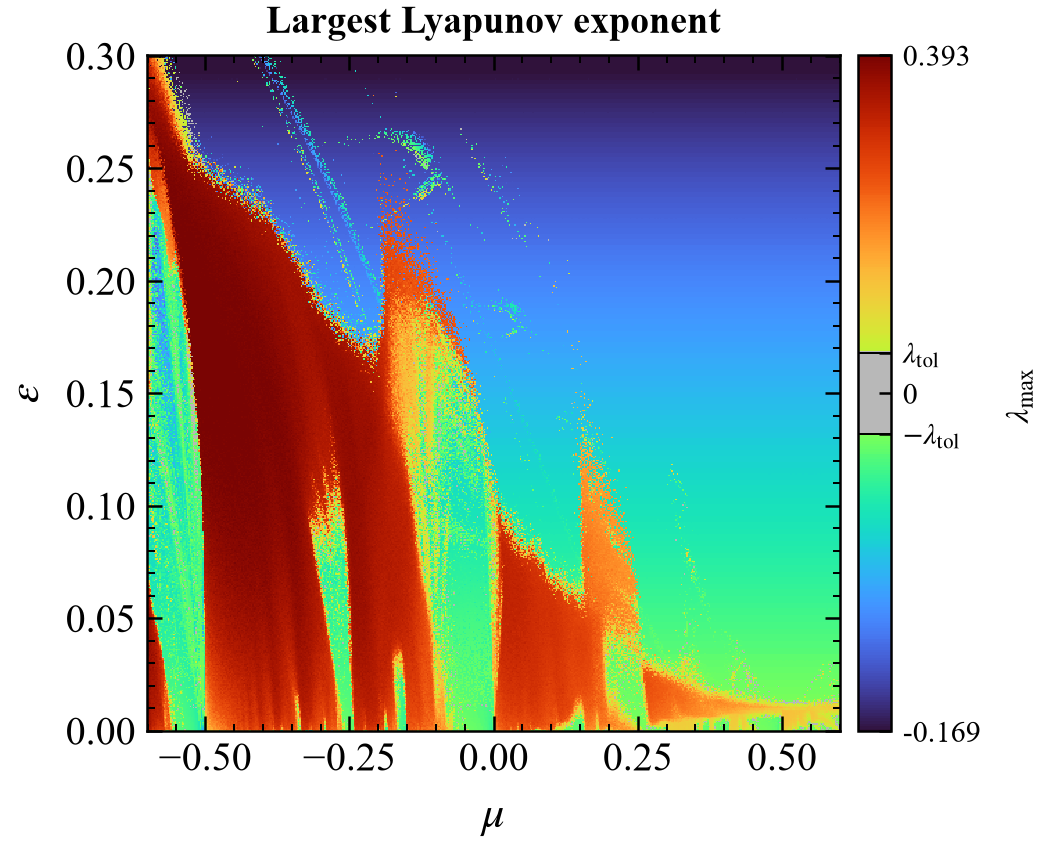

Saved GMmaps_version2_batched_numpy\final\figures\CaseA_SynchronizationSpace_Version2.pdf / .png / .eps


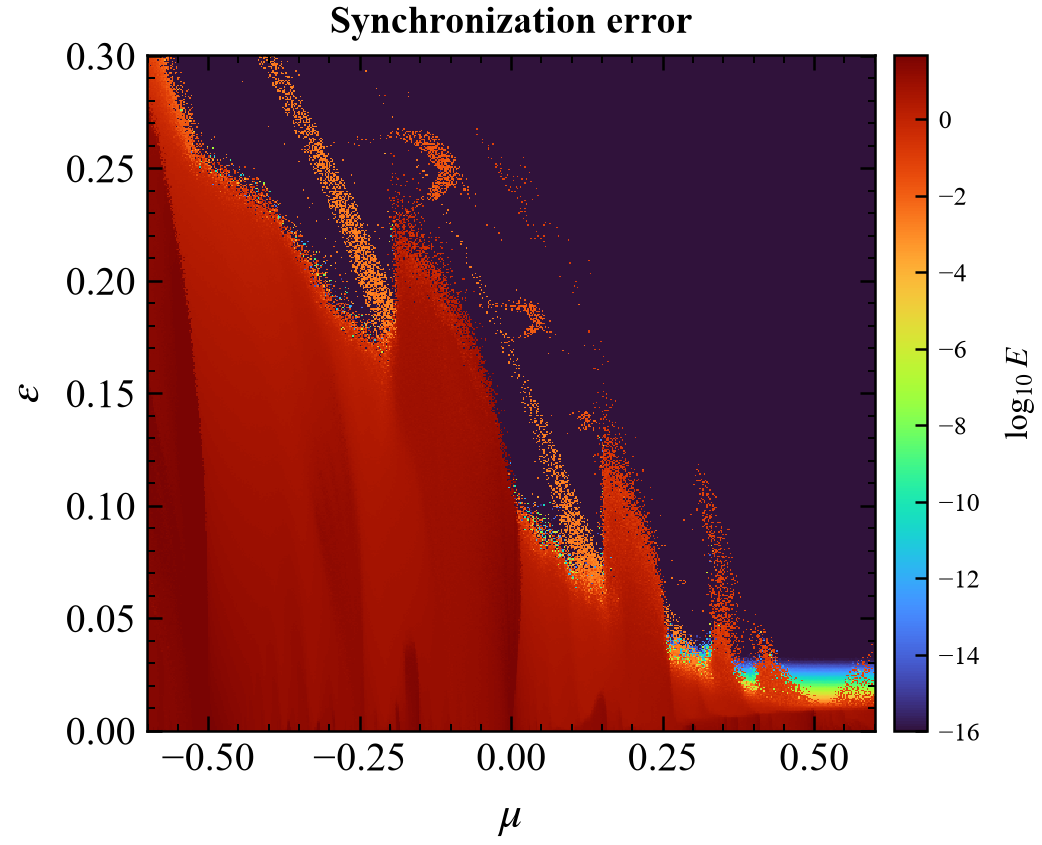

Saved GMmaps_version2_batched_numpy\final\figures\CaseA_ClusterSpace_Version2.pdf / .png / .eps


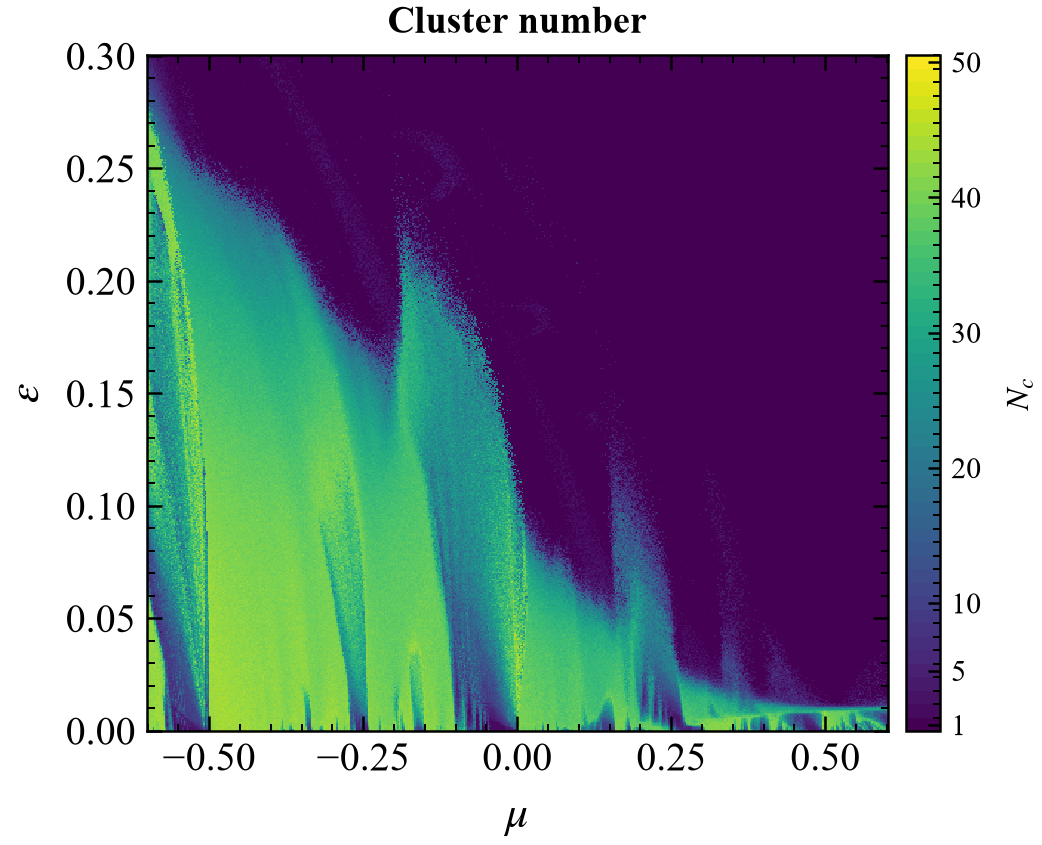

Saved GMmaps_version2_batched_numpy\final\figures\CaseA_CollectivePhaseDiagram_Version2.pdf / .png / .eps


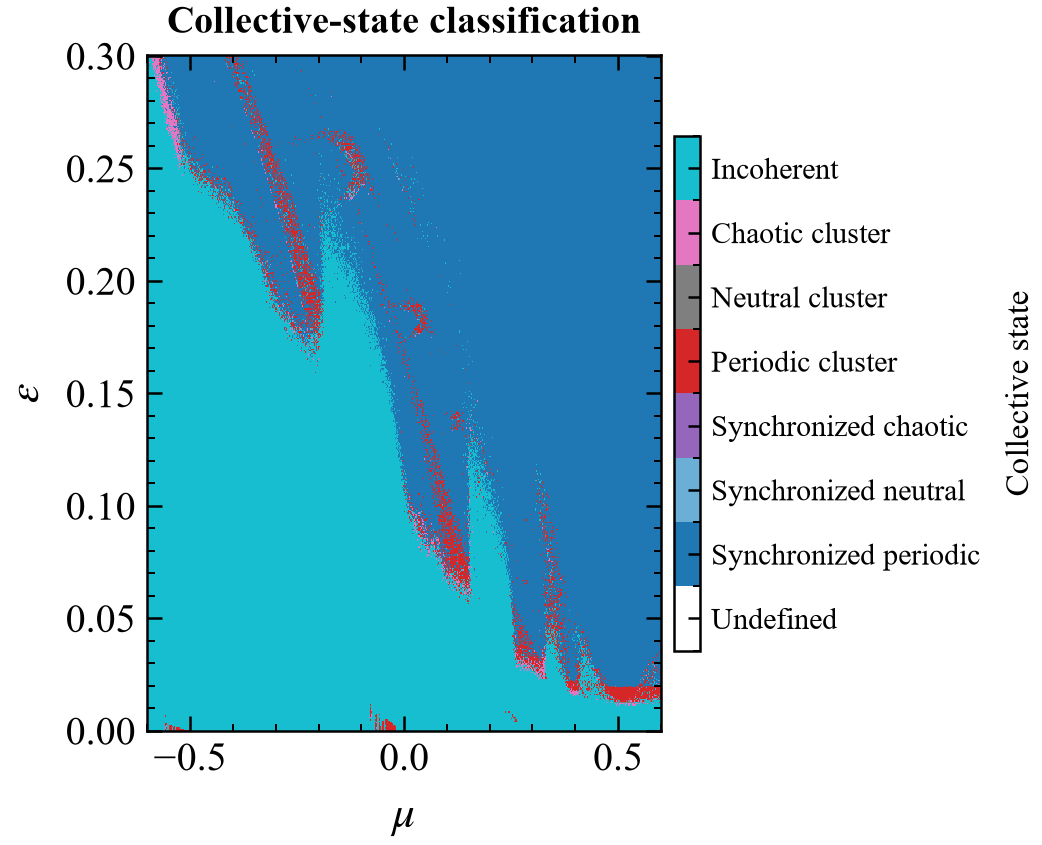

Saved GMmaps_version2_batched_numpy\final\figures\CaseB_LyapunovSpace_Version2_visible_neutral.pdf / .png / .eps


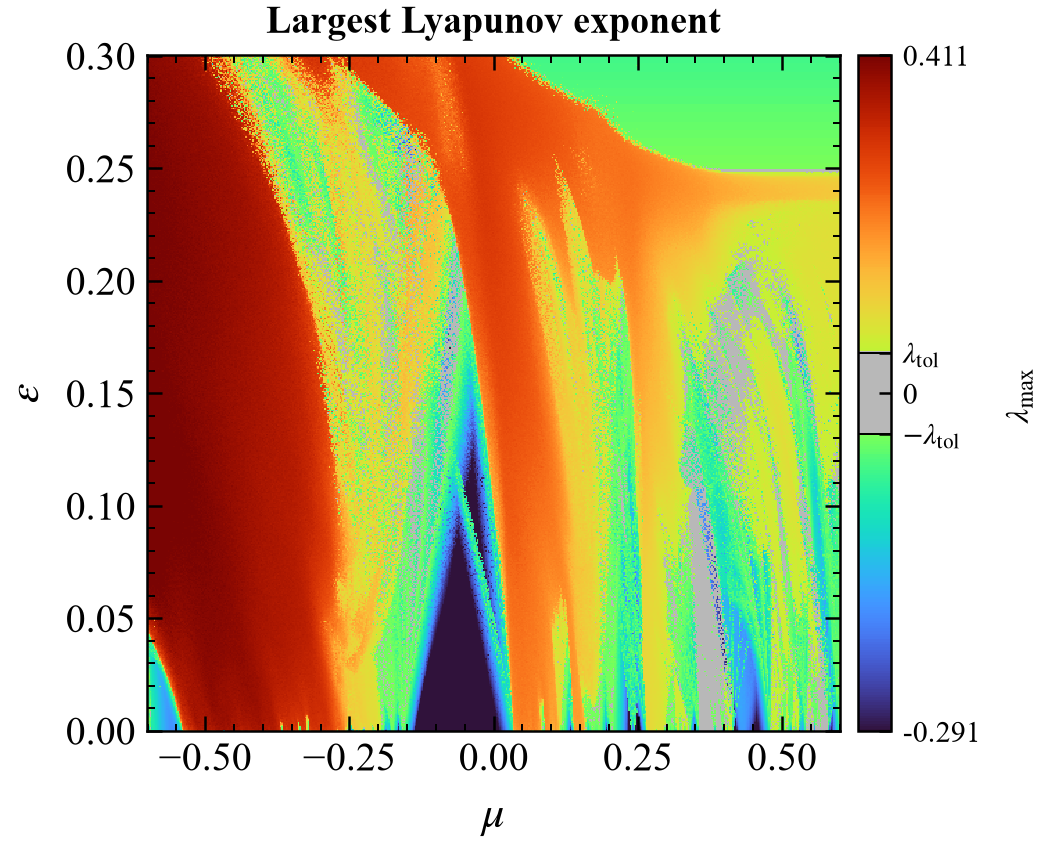

Saved GMmaps_version2_batched_numpy\final\figures\CaseB_SynchronizationSpace_Version2.pdf / .png / .eps


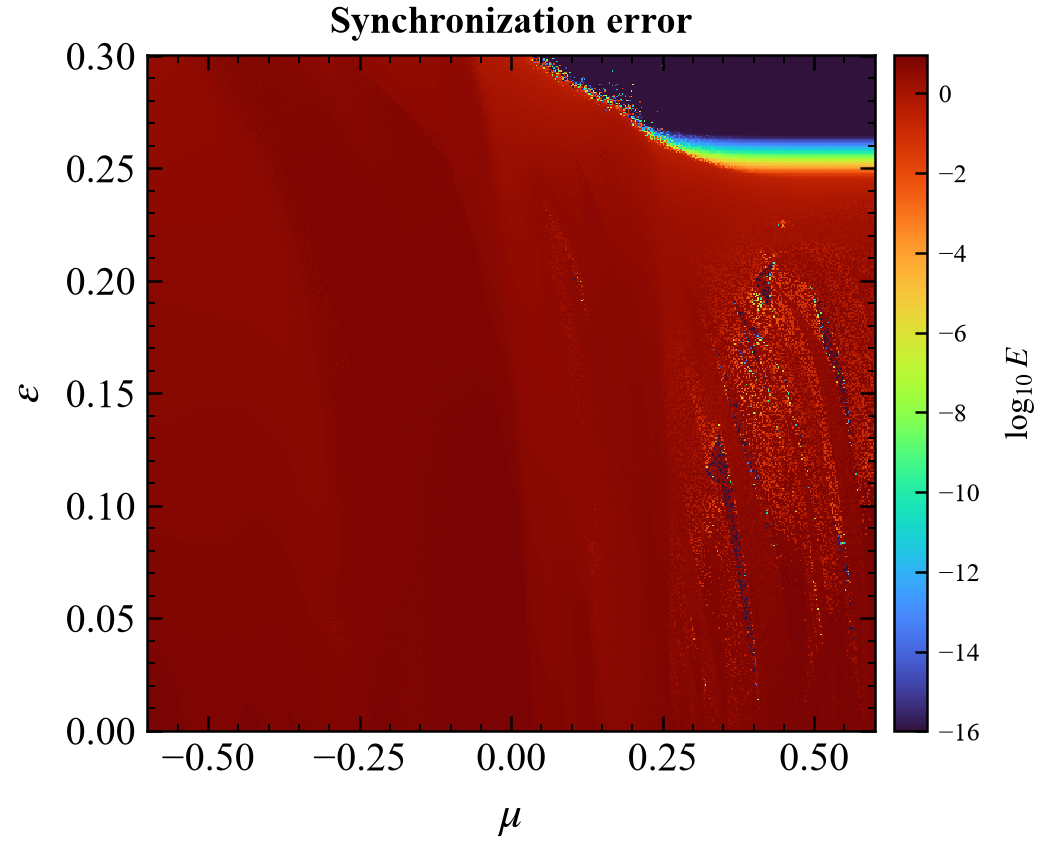

Saved GMmaps_version2_batched_numpy\final\figures\CaseB_ClusterSpace_Version2.pdf / .png / .eps


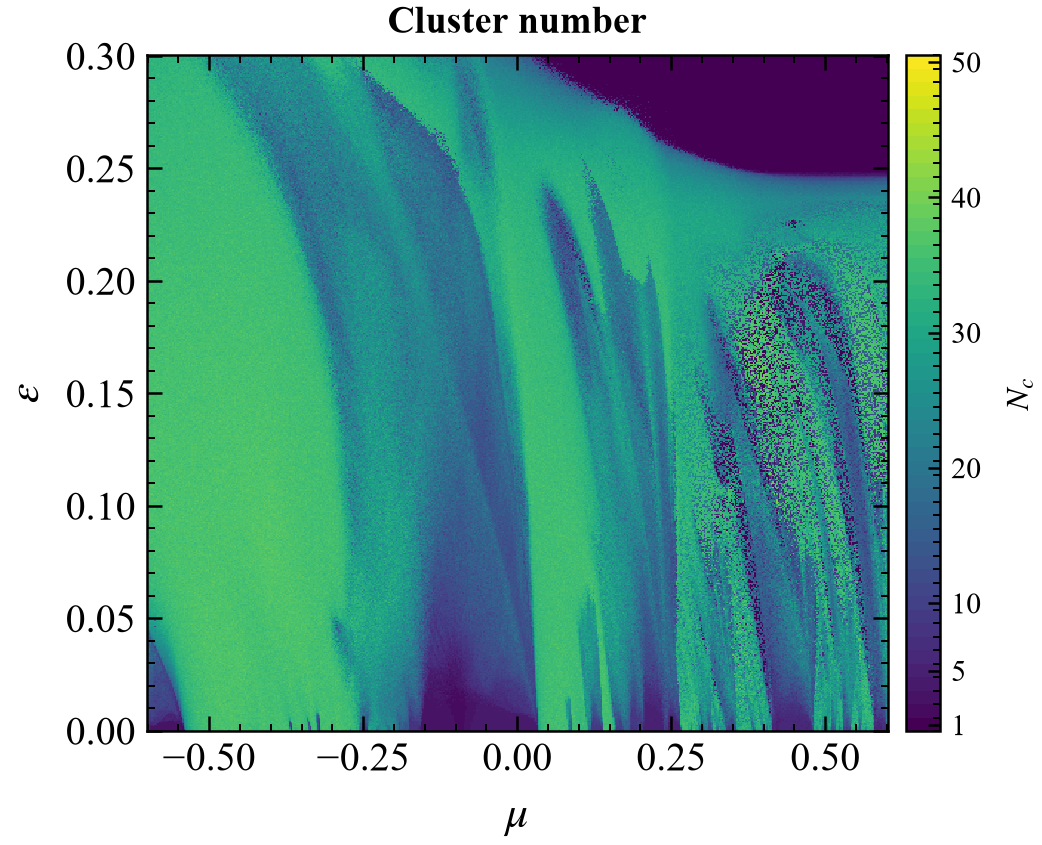

Saved GMmaps_version2_batched_numpy\final\figures\CaseB_CollectivePhaseDiagram_Version2.pdf / .png / .eps


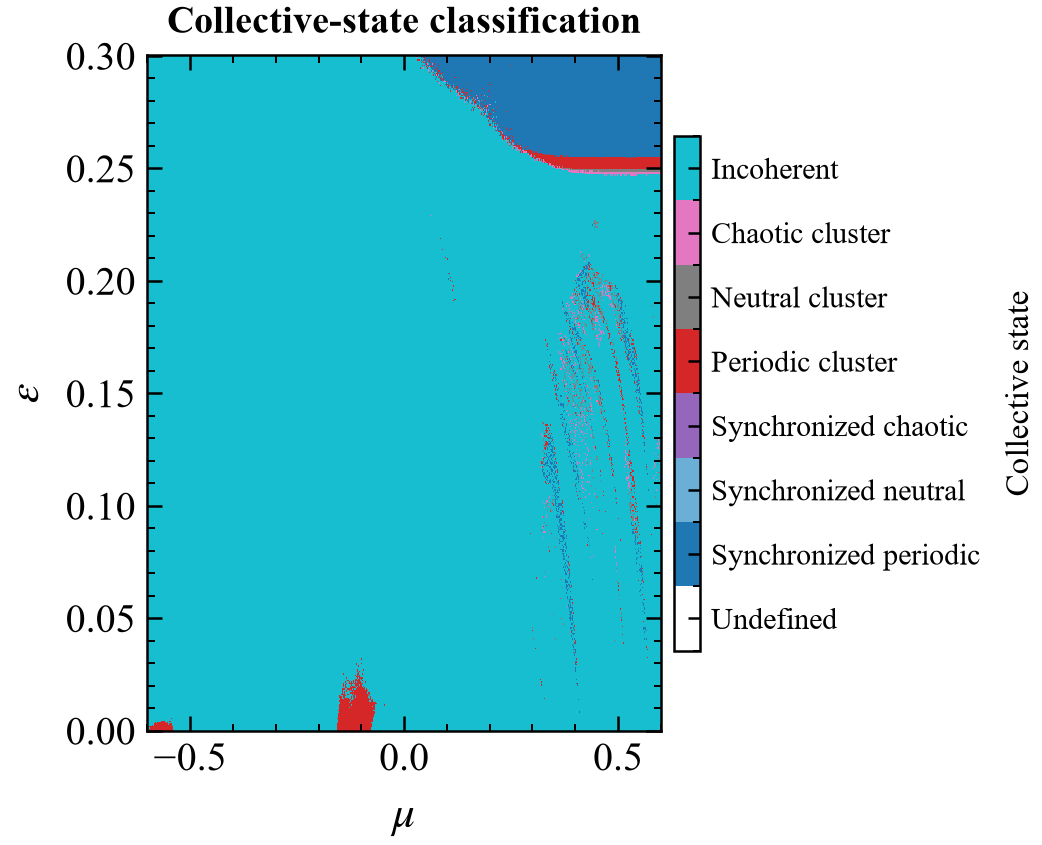

All separate parameter-space figures were saved.


In [22]:
# ============================================================
# 10. SEPARATE PUBLICATION-READY PARAMETER-SPACE FIGURES
# Consistent colors, neutral Lyapunov band, accurate grid-cell edges
# ============================================================


def save_single_map(
    case_name,
    result,
    quantity,
    title,
    colorbar_label,
    filename,
    cmap,
    norm=None,
    vmin=None,
    vmax=None,
    ticks=None,
    ticklabels=None,
    reference_lines=None,
):
    """Save one publication-quality parameter-space diagnostic."""
    mu_edges = coordinate_edges(result["mu"])
    epsilon_edges = coordinate_edges(result["epsilon"])
    values = np.asarray(quantity, dtype=float)

    expected_shape = (len(epsilon_edges) - 1, len(mu_edges) - 1)
    if values.shape != expected_shape:
        raise ValueError(
            f"Case {case_name}, {filename}: expected {expected_shape}, "
            f"received {values.shape}."
        )

    figure, axis = plt.subplots(
        figsize=(5.8, 4.7),
        constrained_layout=True,
    )
    image = axis.pcolormesh(
        mu_edges,
        epsilon_edges,
        np.ma.masked_invalid(values),
        cmap=cmap,
        norm=norm,
        vmin=vmin,
        vmax=vmax,
        shading="flat",
        rasterized=True,
    )

    style_parameter_axis(axis)
    axis.set_title(title, fontsize=TITLE_FONT_SIZE, pad=9)

    colorbar = figure.colorbar(
        image,
        ax=axis,
        pad=0.025,
        fraction=0.050,
        ticks=ticks,
    )
    style_colorbar(
        colorbar,
        colorbar_label,
        label_size=COLORBAR_LABEL_FONT_SIZE,
        tick_size=(PHASE_COLORBAR_FONT_SIZE if ticklabels is not None
                   else COLORBAR_TICK_FONT_SIZE),
    )
    if ticklabels is not None:
        colorbar.ax.set_yticklabels(ticklabels)
    if reference_lines:
        for value in reference_lines:
            colorbar.ax.axhline(
                value,
                color="black",
                linewidth=0.8,
                zorder=5,
            )

    output_stem = FIGURE_DIRECTORY / f"Case{case_name}_{filename}"
    figure.savefig(output_stem.with_suffix(".pdf"), bbox_inches="tight")
    figure.savefig(
        output_stem.with_suffix(".png"),
        dpi=600,
        bbox_inches="tight",
        pad_inches=0.04,
    )
    figure.savefig(output_stem.with_suffix(".eps"), bbox_inches="tight")

    print(f"Saved {output_stem}.pdf / .png / .eps")
    plt.show()
    plt.close(figure)


for case_name, result in network_results.items():
    valid = np.asarray(result["VALID"], dtype=bool)

    # (a) Largest Lyapunov exponent: display-only piecewise mapping
    # makes the tolerance-defined neutral regime visibly distinct.
    le_values = np.where(
        valid,
        np.asarray(result["LE"], dtype=float),
        np.nan,
    )
    (
        le_display,
        le_cmap,
        le_ticks,
        le_ticklabels,
        le_lower,
        le_upper,
        neutral_count,
    ) = build_lyapunov_display(
        le_values,
        float(get_config_value(config, "lambda_tolerance")),
    )
    save_single_map(
        case_name,
        result,
        le_display,
        "Largest Lyapunov exponent",
        r"$\lambda_{\max}$",
        "LyapunovSpace_Version2_visible_neutral",
        le_cmap,
        vmin=0.0,
        vmax=1.0,
        ticks=le_ticks,
        ticklabels=le_ticklabels,
        reference_lines=[NEUTRAL_DISPLAY_LOWER, NEUTRAL_DISPLAY_UPPER],
    )

    # (b) Synchronization error: perceptually uniform sequential map.
    sync_values = np.where(
        valid,
        np.asarray(result["SYNC"], dtype=float),
        np.nan,
    )
    sync_values = np.where(sync_values >= 0.0, sync_values, np.nan)
    log_sync = np.log10(sync_values + 1.0e-16)
    finite_sync = log_sync[np.isfinite(log_sync)]
    if finite_sync.size:
        sync_min = float(np.percentile(finite_sync, 2.0))
        sync_max = float(np.percentile(finite_sync, 98.0))
        if sync_max <= sync_min:
            sync_min = float(np.min(finite_sync))
            sync_max = float(np.max(finite_sync))
        if sync_max <= sync_min:
            sync_min -= 1.0e-6
            sync_max += 1.0e-6
    else:
        sync_min, sync_max = -16.0, 0.0
    sync_ticks = np.arange(
        np.ceil(sync_min / 2.0) * 2.0,
        np.floor(sync_max / 2.0) * 2.0 + 0.1,
        2.0,
    )
    save_single_map(
        case_name,
        result,
        log_sync,
        "Synchronization error",
        r"$\log_{10}E$",
        "SynchronizationSpace_Version2",
        MANUSCRIPT_SYNCHRONIZATION_CMAP,
        vmin=sync_min,
        vmax=sync_max,
        ticks=sync_ticks if sync_ticks.size else None,
    )

    # (c) Cluster number: integer-valued discrete color scale.
    cluster_values = np.where(
        valid,
        np.rint(np.asarray(result["CLUSTERS"], dtype=float)),
        np.nan,
    )
    cluster_cmap, cluster_norm, cluster_bounds, cluster_ticks = (
        build_cluster_scale(NETWORK_SIZE)
    )
    save_single_map(
        case_name,
        result,
        cluster_values,
        "Cluster number",
        r"$N_c$",
        "ClusterSpace_Version2",
        cluster_cmap,
        norm=cluster_norm,
        ticks=cluster_ticks,
        ticklabels=[str(int(value)) for value in cluster_ticks],
    )

    # (d) Collective-state class: fixed manuscript categorical palette.
    phase_values = np.where(
        valid,
        np.asarray(result["PHASE"], dtype=float),
        np.nan,
    )
    if isinstance(PHASE_LABELS, Mapping):
        phase_codes = sorted(int(code) for code in PHASE_LABELS)
        phase_ticklabels = [str(PHASE_LABELS[code]) for code in phase_codes]
    else:
        phase_codes = list(range(len(PHASE_LABELS)))
        phase_ticklabels = [str(label) for label in PHASE_LABELS]
    save_single_map(
        case_name,
        result,
        phase_values,
        "Collective-state classification",
        "Collective state",
        "CollectivePhaseDiagram_Version2",
        MANUSCRIPT_PHASE_CMAP,
        norm=PHASE_NORM,
        ticks=phase_codes,
        ticklabels=phase_ticklabels,
    )

print("All separate parameter-space figures were saved.")


## Recommended workflow after the scan

1. Keep the Version 1 outputs archived and separate.
2. Inspect the Version 2 `FAST` maps before committing to the `FINAL` run.
3. Do not reuse old representative parameter pairs automatically because the phase organization may have changed.
4. Select new representative synchronized, clustered, chaotic, and incoherent points from the Version 2 maps.
5. Run the Comment 4 multiple-initial-condition study at those new points.
6. Update the manuscript's network results, abstract, discussion, and conclusion only after the Version 2 results have been verified.

## Representative-state selection

Select interior parameter points from the Version 2 maps and inspect their locations before running the long verification simulations.


In [23]:
# ============================================================
# ROBUST AUTOMATIC SELECTION OF VERSION 2
# NETWORK REPRESENTATIVE STATES
# ============================================================

from scipy.ndimage import distance_transform_edt


# Collective-state codes used in the Version 2 simulations.
REPRESENTATIVE_PHASE_CODES = {
    "Synchronized periodic": 1,
    "Periodic cluster": 4,
    "Chaotic cluster": 6,
    "Incoherent": 7,
}


# ============================================================
# 1. SUPPORTING FUNCTIONS
# ============================================================

def normalize_values(values):
    """
    Normalize finite values to the interval [0, 1].

    If all finite values are equal, return zeros.
    """
    values = np.asarray(
        values,
        dtype=float,
    )

    normalized = np.zeros_like(
        values,
        dtype=float,
    )

    finite_mask = np.isfinite(
        values
    )

    if not np.any(finite_mask):
        return normalized

    minimum = float(
        np.min(
            values[finite_mask]
        )
    )

    maximum = float(
        np.max(
            values[finite_mask]
        )
    )

    value_range = (
        maximum - minimum
    )

    if value_range > 0.0:
        normalized[finite_mask] = (
            values[finite_mask]
            - minimum
        ) / value_range

    return normalized


def make_parameter_edge_mask(
    shape,
    edge_margin_cells,
):
    """
    Construct a Boolean mask excluding the outer parameter edges.

    Parameters
    ----------
    shape : tuple
        Shape of the two-dimensional parameter array.

    edge_margin_cells : int
        Number of grid cells excluded from each outer boundary.

    Returns
    -------
    numpy.ndarray
        Boolean mask with False values along the outer edges.
    """
    edge_mask = np.ones(
        shape,
        dtype=bool,
    )

    margin = max(
        0,
        int(edge_margin_cells),
    )

    maximum_margin = max(
        0,
        min(shape) // 2 - 1,
    )

    margin = min(
        margin,
        maximum_margin,
    )

    if margin > 0:
        edge_mask[:margin, :] = False
        edge_mask[-margin:, :] = False
        edge_mask[:, :margin] = False
        edge_mask[:, -margin:] = False

    return edge_mask


def validate_network_result_arrays(
    result,
):
    """
    Validate the structure of a Version 2 network result.

    Returns
    -------
    tuple
        phase_array, valid_array, lambda_array,
        synchronization_array, cluster_array,
        mu_values, epsilon_values.
    """
    required_keys = {
        "PHASE",
        "VALID",
        "LE",
        "SYNC",
        "CLUSTERS",
        "mu",
        "epsilon",
    }

    missing_keys = (
        required_keys
        - set(result.keys())
    )

    if missing_keys:
        raise KeyError(
            "The result dictionary is missing: "
            + ", ".join(
                sorted(missing_keys)
            )
        )

    phase_array = np.asarray(
        result["PHASE"]
    )

    valid_array = np.asarray(
        result["VALID"],
        dtype=bool,
    )

    lambda_array = np.asarray(
        result["LE"],
        dtype=float,
    )

    synchronization_array = np.asarray(
        result["SYNC"],
        dtype=float,
    )

    cluster_array = np.asarray(
        result["CLUSTERS"],
        dtype=float,
    )

    mu_values = np.asarray(
        result["mu"],
        dtype=float,
    )

    epsilon_values = np.asarray(
        result["epsilon"],
        dtype=float,
    )

    if phase_array.ndim != 2:
        raise ValueError(
            "The PHASE array must be two-dimensional."
        )

    expected_shape = (
        phase_array.shape
    )

    arrays_to_check = {
        "VALID": valid_array,
        "LE": lambda_array,
        "SYNC": synchronization_array,
        "CLUSTERS": cluster_array,
    }

    for array_name, array in (
        arrays_to_check.items()
    ):
        if array.shape != expected_shape:
            raise ValueError(
                f"{array_name} has shape "
                f"{array.shape}, but PHASE has "
                f"shape {expected_shape}."
            )

    if mu_values.ndim != 1:
        raise ValueError(
            "The mu array must be one-dimensional."
        )

    if epsilon_values.ndim != 1:
        raise ValueError(
            "The epsilon array must be one-dimensional."
        )

    if (
        mu_values.size
        != phase_array.shape[1]
    ):
        raise ValueError(
            "The length of the mu array does not "
            "match the number of PHASE columns."
        )

    if (
        epsilon_values.size
        != phase_array.shape[0]
    ):
        raise ValueError(
            "The length of the epsilon array does not "
            "match the number of PHASE rows."
        )

    return (
        phase_array,
        valid_array,
        lambda_array,
        synchronization_array,
        cluster_array,
        mu_values,
        epsilon_values,
    )


# ============================================================
# 2. ROBUST REPRESENTATIVE-POINT SELECTOR
# ============================================================

def select_interior_phase_point(
    result,
    phase_code,
    minimum_boundary_distance=2.0,
    edge_margin_cells=10,
    minimum_positive_lambda=5.0e-3,
    maximum_negative_lambda=-2.0e-3,
    require_multiple_clusters=True,
    require_chaotic_incoherence=True,
):
    """
    Select a robust representative parameter pair.

    The selected point must:

    1. belong to the requested collective phase;
    2. have valid and finite diagnostics;
    3. lie away from the outer parameter boundaries;
    4. satisfy state-specific Lyapunov, synchronization,
       and cluster-number requirements;
    5. lie sufficiently far from internal phase boundaries.

    The internal boundary-distance criterion is not relaxed
    for chaotic-cluster states.

    Parameters
    ----------
    result : dict
        Dictionary containing mu, epsilon, LE, SYNC,
        CLUSTERS, PHASE, and VALID.

    phase_code : int
        Requested collective-state code.

    minimum_boundary_distance : float
        Preferred minimum distance from an internal phase
        boundary, measured in grid cells.

    edge_margin_cells : int
        Number of grid cells excluded from each outer edge.

    minimum_positive_lambda : float
        Minimum Lyapunov exponent for chaotic representatives.

    maximum_negative_lambda : float
        Maximum Lyapunov exponent for periodic representatives.
        This value must be negative.

    require_multiple_clusters : bool
        Require at least two clusters for periodic-cluster
        and chaotic-cluster states.

    require_chaotic_incoherence : bool
        Require a clearly positive Lyapunov exponent for the
        incoherent representative.

    Returns
    -------
    dict or None
        Selected point and diagnostics, or None if no eligible
        point exists.
    """

    (
        phase_array,
        valid_array,
        lambda_array,
        synchronization_array,
        cluster_array,
        mu_values,
        epsilon_values,
    ) = validate_network_result_arrays(
        result
    )

    # Region belonging to the requested phase.
    requested_phase_region = (
        (phase_array == phase_code)
        & valid_array
    )

    # Begin with valid, finite points in the requested phase.
    candidate_mask = (
        requested_phase_region
        & np.isfinite(lambda_array)
        & np.isfinite(
            synchronization_array
        )
        & np.isfinite(cluster_array)
    )

    # --------------------------------------------------------
    # Exclude outer parameter-domain boundaries
    # --------------------------------------------------------

    edge_mask = make_parameter_edge_mask(
        phase_array.shape,
        edge_margin_cells,
    )

    candidate_mask &= edge_mask

    # --------------------------------------------------------
    # State-specific diagnostic criteria
    # --------------------------------------------------------

    if phase_code == 1:
        # Synchronized periodic:
        # negative exponent, one cluster, and negligible E.

        candidate_mask &= (
            lambda_array
            <= maximum_negative_lambda
        )

        candidate_mask &= (
            synchronization_array
            <= config.synchronization_tolerance
        )

        candidate_mask &= (
            cluster_array == 1
        )

    elif phase_code == 4:
        # Periodic cluster:
        # negative exponent, not completely synchronized,
        # and at least two clusters.

        candidate_mask &= (
            lambda_array
            <= maximum_negative_lambda
        )

        candidate_mask &= (
            synchronization_array
            > config.synchronization_tolerance
        )

        if require_multiple_clusters:
            candidate_mask &= (
                cluster_array >= 2
            )

        candidate_mask &= (
            cluster_array
            <= config.fragmentation_threshold
        )

    elif phase_code == 6:
        # Chaotic cluster:
        # positive exponent, not completely synchronized,
        # and at least two clusters.

        candidate_mask &= (
            lambda_array
            >= minimum_positive_lambda
        )

        candidate_mask &= (
            synchronization_array
            > config.synchronization_tolerance
        )

        if require_multiple_clusters:
            candidate_mask &= (
                cluster_array >= 2
            )

        candidate_mask &= (
            cluster_array
            <= config.fragmentation_threshold
        )

    elif phase_code == 7:
        # Incoherent:
        # more clusters than the fragmentation threshold.

        candidate_mask &= (
            cluster_array
            > config.fragmentation_threshold
        )

        if require_chaotic_incoherence:
            candidate_mask &= (
                lambda_array
                >= minimum_positive_lambda
            )

    else:
        raise ValueError(
            "Unsupported representative phase code: "
            f"{phase_code}"
        )

    if not np.any(candidate_mask):
        return None

    # --------------------------------------------------------
    # Distance from internal phase boundaries
    # --------------------------------------------------------

    boundary_distance = (
        distance_transform_edt(
            requested_phase_region
        )
    )

    interior_mask = (
        candidate_mask
        & (
            boundary_distance
            >= minimum_boundary_distance
        )
    )

    if not np.any(interior_mask):
        # Do not accept one-cell-wide or boundary-sensitive
        # chaotic-cluster candidates.
        if phase_code == 6:
            return None

        # For other classes, relax only the internal-distance
        # requirement. All diagnostic and edge requirements
        # remain active.
        interior_mask = (
            candidate_mask
        )

    candidate_indices = np.argwhere(
        interior_mask
    )

    candidate_boundary_distance = (
        boundary_distance[
            interior_mask
        ]
    )

    candidate_lambda = (
        lambda_array[
            interior_mask
        ]
    )

    candidate_sync = (
        synchronization_array[
            interior_mask
        ]
    )

    candidate_clusters = (
        cluster_array[
            interior_mask
        ]
    )

    # --------------------------------------------------------
    # Construct a robustness score
    # --------------------------------------------------------

    score = normalize_values(
        candidate_boundary_distance
    )

    if phase_code == 1:
        # Prefer more negative exponents.
        negative_strength = (
            normalize_values(
                -candidate_lambda
            )
        )

        # Prefer lower synchronization error.
        synchronization_strength = (
            normalize_values(
                -np.log10(
                    candidate_sync
                    + 1.0e-300
                )
            )
        )

        score += (
            0.25 * negative_strength
            + 0.25
            * synchronization_strength
        )

    elif phase_code == 4:
        # Prefer clearly negative multi-cluster states.
        negative_strength = (
            normalize_values(
                -candidate_lambda
            )
        )

        cluster_strength = (
            normalize_values(
                candidate_clusters
            )
        )

        score += (
            0.30 * negative_strength
            + 0.10 * cluster_strength
        )

    elif phase_code == 6:
        # Prefer clearly positive chaotic-cluster states.
        positive_strength = (
            normalize_values(
                candidate_lambda
            )
        )

        cluster_strength = (
            normalize_values(
                candidate_clusters
            )
        )

        score += (
            0.40 * positive_strength
            + 0.10 * cluster_strength
        )

    elif phase_code == 7:
        # Prefer highly fragmented incoherent states.
        fragmentation_strength = (
            normalize_values(
                candidate_clusters
            )
        )

        score += (
            0.35
            * fragmentation_strength
        )

        if require_chaotic_incoherence:
            positive_strength = (
                normalize_values(
                    candidate_lambda
                )
            )

            score += (
                0.25
                * positive_strength
            )

    # --------------------------------------------------------
    # Slight preference for the center of the parameter plane
    # --------------------------------------------------------

    epsilon_center_index = (
        phase_array.shape[0] - 1
    ) / 2.0

    mu_center_index = (
        phase_array.shape[1] - 1
    ) / 2.0

    distance_from_plane_center = np.sqrt(
        (
            candidate_indices[:, 0]
            - epsilon_center_index
        ) ** 2
        + (
            candidate_indices[:, 1]
            - mu_center_index
        ) ** 2
    )

    center_preference = (
        1.0
        - normalize_values(
            distance_from_plane_center
        )
    )

    score += (
        0.05
        * center_preference
    )

    selected_position = int(
        np.argmax(score)
    )

    epsilon_index = int(
        candidate_indices[
            selected_position,
            0,
        ]
    )

    mu_index = int(
        candidate_indices[
            selected_position,
            1,
        ]
    )

    return {
        "mu": float(
            mu_values[mu_index]
        ),
        "epsilon": float(
            epsilon_values[
                epsilon_index
            ]
        ),
        "mu_index": mu_index,
        "epsilon_index": epsilon_index,
        "phase_code": int(
            phase_array[
                epsilon_index,
                mu_index,
            ]
        ),
        "lambda_max": float(
            lambda_array[
                epsilon_index,
                mu_index,
            ]
        ),
        "sync_error": float(
            synchronization_array[
                epsilon_index,
                mu_index,
            ]
        ),
        "cluster_number": int(
            np.rint(
                cluster_array[
                    epsilon_index,
                    mu_index,
                ]
            )
        ),
        "boundary_distance": float(
            boundary_distance[
                epsilon_index,
                mu_index,
            ]
        ),
        "selection_score": float(
            score[
                selected_position
            ]
        ),
    }


# ============================================================
# 3. SELECT REPRESENTATIVES FOR CASES A AND B
# ============================================================

VERSION2_REPRESENTATIVE_POINTS = {
    "A": {},
    "B": {},
}

representative_rows = []

for case_name in ("A", "B"):
    if case_name not in network_results:
        print(
            f"Case {case_name} is not available "
            "in network_results."
        )

        continue

    result = network_results[
        case_name
    ]

    for state_name, phase_code in (
        REPRESENTATIVE_PHASE_CODES.items()
    ):
        selected_point = (
            select_interior_phase_point(
                result=result,
                phase_code=phase_code,
                minimum_boundary_distance=2.0,
                edge_margin_cells=10,
                minimum_positive_lambda=5.0e-3,
                maximum_negative_lambda=-2.0e-3,
                require_multiple_clusters=True,
                require_chaotic_incoherence=True,
            )
        )

        VERSION2_REPRESENTATIVE_POINTS[
            case_name
        ][state_name] = (
            selected_point
        )

        row = {
            "case": case_name,
            "state": state_name,
            "phase_code": phase_code,
            "selection_successful": (
                selected_point is not None
            ),
        }

        if selected_point is None:
            row.update(
                {
                    "mu": np.nan,
                    "epsilon": np.nan,
                    "lambda_max": np.nan,
                    "sync_error": np.nan,
                    "cluster_number": np.nan,
                    "boundary_distance": np.nan,
                    "selection_score": np.nan,
                }
            )

        else:
            row.update(
                {
                    "mu": selected_point[
                        "mu"
                    ],
                    "epsilon": selected_point[
                        "epsilon"
                    ],
                    "lambda_max": selected_point[
                        "lambda_max"
                    ],
                    "sync_error": selected_point[
                        "sync_error"
                    ],
                    "cluster_number": (
                        selected_point[
                            "cluster_number"
                        ]
                    ),
                    "boundary_distance": (
                        selected_point[
                            "boundary_distance"
                        ]
                    ),
                    "selection_score": (
                        selected_point[
                            "selection_score"
                        ]
                    ),
                }
            )

        representative_rows.append(
            row
        )


version2_representative_summary = (
    pd.DataFrame(
        representative_rows
    )
)

display(
    version2_representative_summary
)

version2_representative_summary.to_csv(
    TABLE_DIRECTORY
    / (
        "Version2_selected_network_"
        "representatives_robust.csv"
    ),
    index=False,
)


# ============================================================
# 4. PRINT SELECTED POINTS
# ============================================================

print(
    "\nRobust Version 2 representative selection:\n"
)

for case_name in ("A", "B"):
    if case_name not in network_results:
        continue

    print(
        f"Case {case_name}"
    )

    for state_name in (
        REPRESENTATIVE_PHASE_CODES
    ):
        selected_point = (
            VERSION2_REPRESENTATIVE_POINTS[
                case_name
            ].get(
                state_name
            )
        )

        if selected_point is None:
            print(
                f"  {state_name}: "
                "no qualifying point found"
            )

        else:
            print(
                f"  {state_name}: "
                f"mu="
                f"{selected_point['mu']:.6f}, "
                f"epsilon="
                f"{selected_point['epsilon']:.6f}, "
                f"lambda_max="
                f"{selected_point['lambda_max']:.4e}, "
                f"E="
                f"{selected_point['sync_error']:.4e}, "
                f"Nc="
                f"{selected_point['cluster_number']}, "
                f"boundary distance="
                f"{selected_point['boundary_distance']:.1f}, "
                f"score="
                f"{selected_point['selection_score']:.3f}"
            )


# ============================================================
# 5. AUTOMATIC CONSISTENCY CHECK
# ============================================================

validation_rows = []

for case_name in ("A", "B"):
    if case_name not in network_results:
        continue

    result = network_results[
        case_name
    ]

    phase_shape = np.asarray(
        result["PHASE"]
    ).shape

    edge_mask = make_parameter_edge_mask(
        phase_shape,
        edge_margin_cells=10,
    )

    for state_name, phase_code in (
        REPRESENTATIVE_PHASE_CODES.items()
    ):
        point = (
            VERSION2_REPRESENTATIVE_POINTS[
                case_name
            ].get(
                state_name
            )
        )

        if point is None:
            validation_rows.append(
                {
                    "case": case_name,
                    "state": state_name,
                    "status": "not selected",
                    "correct_phase": False,
                    "away_from_outer_edge": False,
                    "boundary_distance_ok": False,
                    "diagnostic_rules_ok": False,
                    "all_criteria_satisfied": False,
                }
            )

            continue

        mu_index = point[
            "mu_index"
        ]

        epsilon_index = point[
            "epsilon_index"
        ]

        correct_phase = (
            point["phase_code"]
            == phase_code
        )

        away_from_outer_edge = bool(
            edge_mask[
                epsilon_index,
                mu_index,
            ]
        )

        boundary_distance_ok = (
            point["boundary_distance"]
            >= 2.0
        )

        diagnostic_rules = []

        if state_name == "Synchronized periodic":
            diagnostic_rules = [
                point["lambda_max"]
                <= -2.0e-3,

                point["sync_error"]
                <= config.synchronization_tolerance,

                point["cluster_number"]
                == 1,
            ]

        elif state_name == "Periodic cluster":
            diagnostic_rules = [
                point["lambda_max"]
                <= -2.0e-3,

                point["sync_error"]
                > config.synchronization_tolerance,

                2
                <= point["cluster_number"]
                <= config.fragmentation_threshold,
            ]

        elif state_name == "Chaotic cluster":
            diagnostic_rules = [
                point["lambda_max"]
                >= 5.0e-3,

                point["sync_error"]
                > config.synchronization_tolerance,

                2
                <= point["cluster_number"]
                <= config.fragmentation_threshold,
            ]

        elif state_name == "Incoherent":
            diagnostic_rules = [
                point["lambda_max"]
                >= 5.0e-3,

                point["cluster_number"]
                > config.fragmentation_threshold,
            ]

        diagnostic_rules_ok = all(
            diagnostic_rules
        )

        all_criteria_satisfied = all(
            [
                correct_phase,
                away_from_outer_edge,
                boundary_distance_ok,
                diagnostic_rules_ok,
            ]
        )

        validation_rows.append(
            {
                "case": case_name,
                "state": state_name,
                "status": "selected",
                "correct_phase": correct_phase,
                "away_from_outer_edge": (
                    away_from_outer_edge
                ),
                "boundary_distance_ok": (
                    boundary_distance_ok
                ),
                "diagnostic_rules_ok": (
                    diagnostic_rules_ok
                ),
                "all_criteria_satisfied": (
                    all_criteria_satisfied
                ),
            }
        )


representative_validation = (
    pd.DataFrame(
        validation_rows
    )
)

display(
    representative_validation
)

representative_validation.to_csv(
    TABLE_DIRECTORY
    / (
        "Version2_representative_"
        "selection_validation.csv"
    ),
    index=False,
)


selected_validation_rows = (
    representative_validation.loc[
        representative_validation[
            "status"
        ]
        == "selected"
    ]
)

if selected_validation_rows.empty:
    print(
        "No representative points satisfied "
        "the robust selection requirements."
    )

elif selected_validation_rows[
    "all_criteria_satisfied"
].all():
    print(
        "All selected representative points satisfy "
        "the robust selection criteria."
    )

else:
    print(
        "Warning: at least one selected representative "
        "does not satisfy all robust criteria."
    )

    display(
        selected_validation_rows.loc[
            ~selected_validation_rows[
                "all_criteria_satisfied"
            ]
        ]
    )

,case,state,phase_code,selection_successful,mu,epsilon,lambda_max,sync_error,cluster_number,boundary_distance,selection_score
0,A,Synchronized periodic,1,True,0.575952,0.293988,-0.169087,1.506370e-222,1,233.403085,1.498026
1,A,Periodic cluster,4,True,0.491784,0.017435,-0.003818,9.287124e-02,3,4.123106,1.108709
2,A,Chaotic cluster,6,True,-0.575952,0.292786,0.141462,3.965219e-02,3,2.236068,1.433521
3,A,Incoherent,7,True,-0.494188,0.099198,0.377817,1.056568e+01,42,155.206314,1.520060
4,B,Synchronized periodic,1,True,0.410020,0.293988,-0.031468,3.057566e-44,1,65.000000,1.517321
5,B,Periodic cluster,4,True,-0.104609,0.006012,-0.440031,7.858429e+00,3,12.041595,1.323667
6,B,Chaotic cluster,6,True,0.535070,0.247695,0.012843,1.698269e-02,3,2.000000,0.502462
7,B,Incoherent,7,True,-0.573547,0.175551,0.412377,4.393703e+00,37,279.546061,1.572224



Robust Version 2 representative selection:

Case A
  Synchronized periodic: mu=0.575952, epsilon=0.293988, lambda_max=-1.6909e-01, E=1.5064e-222, Nc=1, boundary distance=233.4, score=1.498
  Periodic cluster: mu=0.491784, epsilon=0.017435, lambda_max=-3.8180e-03, E=9.2871e-02, Nc=3, boundary distance=4.1, score=1.109
  Chaotic cluster: mu=-0.575952, epsilon=0.292786, lambda_max=1.4146e-01, E=3.9652e-02, Nc=3, boundary distance=2.2, score=1.434
  Incoherent: mu=-0.494188, epsilon=0.099198, lambda_max=3.7782e-01, E=1.0566e+01, Nc=42, boundary distance=155.2, score=1.520
Case B
  Synchronized periodic: mu=0.410020, epsilon=0.293988, lambda_max=-3.1468e-02, E=3.0576e-44, Nc=1, boundary distance=65.0, score=1.517
  Periodic cluster: mu=-0.104609, epsilon=0.006012, lambda_max=-4.4003e-01, E=7.8584e+00, Nc=3, boundary distance=12.0, score=1.324
  Chaotic cluster: mu=0.535070, epsilon=0.247695, lambda_max=1.2843e-02, E=1.6983e-02, Nc=3, boundary distance=2.0, score=0.502
  Incoherent: mu=-0.5

,case,state,status,correct_phase,away_from_outer_edge,boundary_distance_ok,diagnostic_rules_ok,all_criteria_satisfied
0,A,Synchronized periodic,selected,True,True,True,True,True
1,A,Periodic cluster,selected,True,True,True,True,True
2,A,Chaotic cluster,selected,True,True,True,True,True
3,A,Incoherent,selected,True,True,True,True,True
4,B,Synchronized periodic,selected,True,True,True,True,True
5,B,Periodic cluster,selected,True,True,True,True,True
6,B,Chaotic cluster,selected,True,True,True,True,True
7,B,Incoherent,selected,True,True,True,True,True


All selected representative points satisfy the robust selection criteria.


In [24]:
print(
    "Automatically selected Version 2 "
    "representative network states:\n"
)

for case_name in ("A", "B"):
    print(
        f"Case {case_name}"
    )

    for state_name in (
        REPRESENTATIVE_PHASE_CODES
    ):
        selected_point = (
            VERSION2_REPRESENTATIVE_POINTS[
                case_name
            ][state_name]
        )

        if selected_point is None:
            print(
                f"  {state_name}: "
                "no qualifying region found"
            )

        else:
            print(
                f"  {state_name}: "
                f"mu={selected_point['mu']:.6f}, "
                f"epsilon="
                f"{selected_point['epsilon']:.6f}, "
                f"lambda_max="
                f"{selected_point['lambda_max']:.4e}, "
                f"E="
                f"{selected_point['sync_error']:.4e}, "
                f"Nc="
                f"{selected_point['cluster_number']}, "
                f"boundary distance="
                f"{selected_point['boundary_distance']:.1f}"
            )

Automatically selected Version 2 representative network states:

Case A
  Synchronized periodic: mu=0.575952, epsilon=0.293988, lambda_max=-1.6909e-01, E=1.5064e-222, Nc=1, boundary distance=233.4
  Periodic cluster: mu=0.491784, epsilon=0.017435, lambda_max=-3.8180e-03, E=9.2871e-02, Nc=3, boundary distance=4.1
  Chaotic cluster: mu=-0.575952, epsilon=0.292786, lambda_max=1.4146e-01, E=3.9652e-02, Nc=3, boundary distance=2.2
  Incoherent: mu=-0.494188, epsilon=0.099198, lambda_max=3.7782e-01, E=1.0566e+01, Nc=42, boundary distance=155.2
Case B
  Synchronized periodic: mu=0.410020, epsilon=0.293988, lambda_max=-3.1468e-02, E=3.0576e-44, Nc=1, boundary distance=65.0
  Periodic cluster: mu=-0.104609, epsilon=0.006012, lambda_max=-4.4003e-01, E=7.8584e+00, Nc=3, boundary distance=12.0
  Chaotic cluster: mu=0.535070, epsilon=0.247695, lambda_max=1.2843e-02, E=1.6983e-02, Nc=3, boundary distance=2.0
  Incoherent: mu=-0.573547, epsilon=0.175551, lambda_max=4.1238e-01, E=4.3937e+00, Nc=37, bo

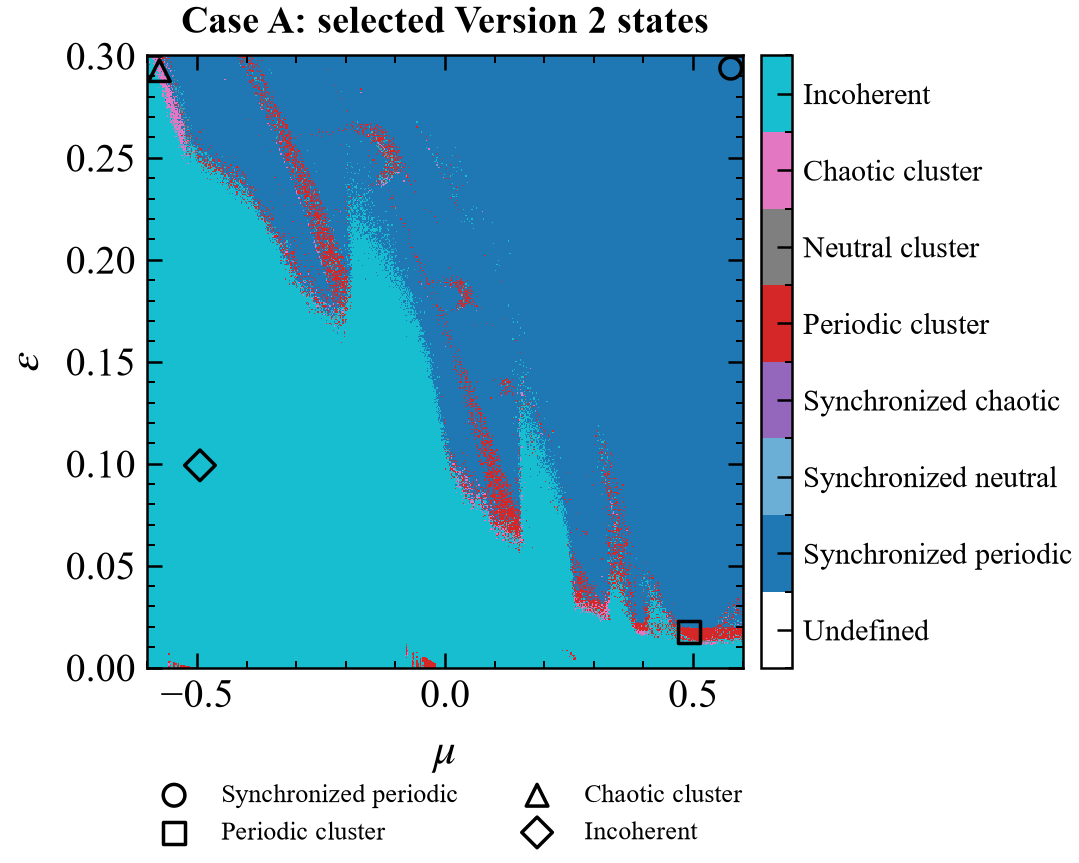

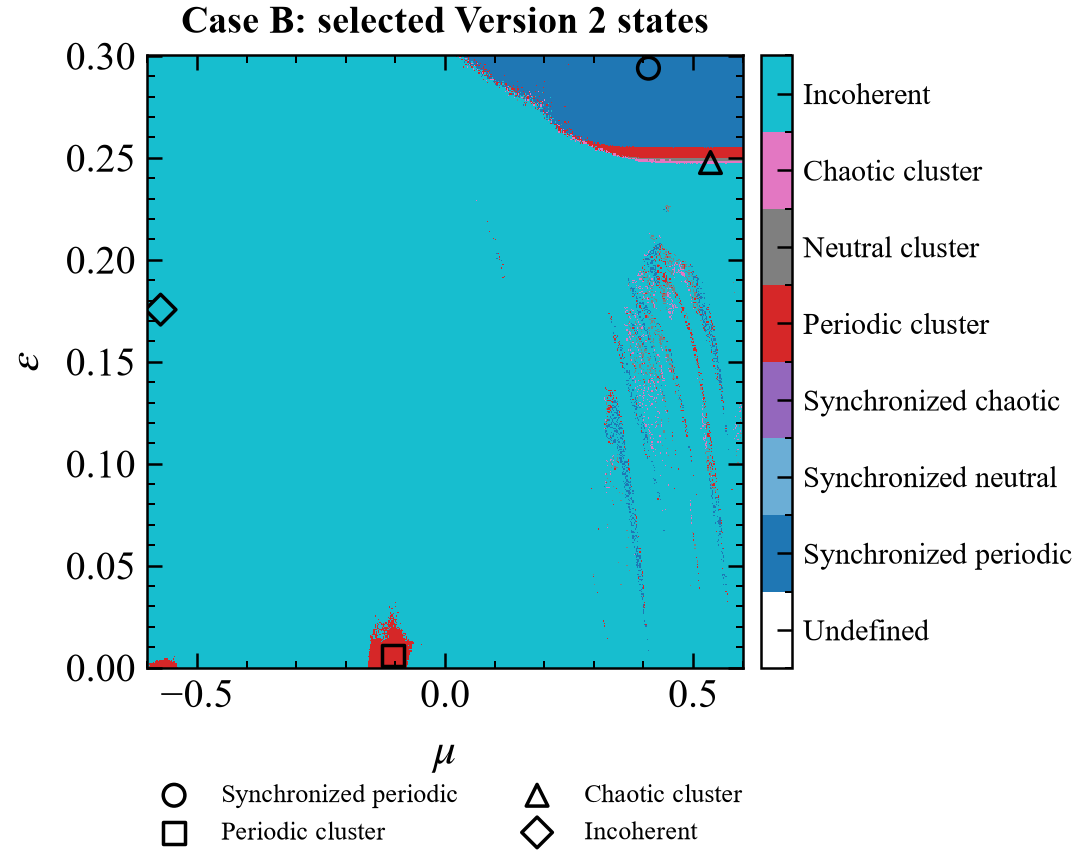

In [25]:
def plot_selected_points_on_phase_map(
    case_name,
    result,
    selected_points,
):
    """
    Display the collective-state map with selected
    representative points marked.
    """

    fig, axis = plt.subplots(
        figsize=(6.0, 4.8),
        constrained_layout=True,
    )

    mu_edges = coordinate_edges(result["mu"])
    epsilon_edges = coordinate_edges(result["epsilon"])
    phase_values = np.asarray(result["PHASE"], dtype=float)
    if "VALID" in result:
        phase_values = np.where(
            np.asarray(result["VALID"], dtype=bool),
            phase_values,
            np.nan,
        )

    image = axis.pcolormesh(
        mu_edges,
        epsilon_edges,
        np.ma.masked_invalid(phase_values),
        cmap=PHASE_CMAP,
        norm=PHASE_NORM,
        shading="flat",
        rasterized=True,
    )

    marker_definitions = {
        "Synchronized periodic": "o",
        "Periodic cluster": "s",
        "Chaotic cluster": "^",
        "Incoherent": "D",
    }

    for state_name, selected_point in (
        selected_points.items()
    ):
        if selected_point is None:
            continue

        axis.scatter(
            selected_point["mu"],
            selected_point["epsilon"],
            marker=marker_definitions[
                state_name
            ],
            s=75,
            facecolor="none",
            edgecolor="black",
            linewidth=1.4,
            label=state_name,
            zorder=5,
        )

    style_parameter_axis(axis)

    axis.set_title(
        f"Case {case_name}: selected Version 2 states",
        fontsize=TITLE_FONT_SIZE,
        pad=9,
    )

    axis.tick_params(
        which="both",
        direction="in",
        top=True,
        right=True,
    )

    axis.legend(
        loc="upper center",
        bbox_to_anchor=(
            0.5,
            -0.15,
        ),
        ncol=2,
        frameon=False,
        fontsize=LEGEND_FONT_SIZE,
    )

    colorbar = fig.colorbar(
        image,
        ax=axis,
        pad=0.02,
        ticks=np.arange(8),
    )

    colorbar.ax.set_yticklabels(
        [
            PHASE_LABELS[index]
            for index in range(8)
        ]
    )

    colorbar.ax.tick_params(
        labelsize=PHASE_COLORBAR_FONT_SIZE
    )

    fig.savefig(
        FIGURE_DIRECTORY
        / (
            f"Case{case_name}_"
            "Version2_selected_points.pdf"
        ),
        bbox_inches="tight",
    )

    fig.savefig(
        FIGURE_DIRECTORY
        / (
            f"Case{case_name}_"
            "Version2_selected_points.png"
        ),
        dpi=600,
        bbox_inches="tight",
        pad_inches=0.04,
    )

    fig.savefig(
        FIGURE_DIRECTORY
        / (
            f"Case{case_name}_"
            "Version2_selected_points.eps"
        ),
        bbox_inches="tight",
    )

    plt.show()
    plt.close()

    return fig, axis


selection_figures = {}

for case_name in ("A", "B"):
    selection_figures[
        case_name
    ] = plot_selected_points_on_phase_map(
        case_name=case_name,
        result=network_results[
            case_name
        ],
        selected_points=(
            VERSION2_REPRESENTATIVE_POINTS[
                case_name
            ]
        ),
    )

## Long-run and multiple-initial-condition verification

Test the selected network states across independent initial conditions and save the verified realizations for the publication figures.


Version 2 points selected for verification:

Case A
  Synchronized periodic: mu=0.575952, epsilon=0.293988
  Periodic cluster: mu=0.491784, epsilon=0.017435
  Chaotic cluster: mu=-0.575952, epsilon=0.292786
  Incoherent: mu=-0.494188, epsilon=0.099198
Case B
  Synchronized periodic: mu=0.410020, epsilon=0.293988
  Periodic cluster: mu=-0.104609, epsilon=0.006012
  Chaotic cluster: mu=0.535070, epsilon=0.247695
  Incoherent: mu=-0.573547, epsilon=0.175551

Case A, Synchronized periodic: mu=0.575952, epsilon=0.293988 (1/8)
  completed 10/50
  completed 20/50
  completed 30/50
  completed 40/50
  completed 50/50
  point elapsed time: 650.4 s

Case A, Periodic cluster: mu=0.491784, epsilon=0.017435 (2/8)
  completed 10/50
  completed 20/50
  completed 30/50
  completed 40/50
  completed 50/50
  point elapsed time: 194.3 s

Case A, Chaotic cluster: mu=-0.575952, epsilon=0.292786 (3/8)
  completed 10/50
  completed 20/50
  completed 30/50
  completed 40/50
  completed 50/50
  point elapsed t

,case,state_requested,mu,epsilon,realization_id,seed,expected_phase_code,lambda_max,sync_error_mean,sync_error_median,...,classification_agreement,initial_mean_x,initial_mean_y,initial_std_x,initial_std_y,final_mean_x,final_mean_y,final_std_x,final_std_y,valid
0,A,Synchronized periodic,0.575952,0.293988,0,20360906,1,-0.169090,0.0,0.0,...,True,-0.020512,-0.071065,0.629950,0.551571,0.0,-0.0,0.0,0.0,True
1,A,Synchronized periodic,0.575952,0.293988,1,20360907,1,-0.169083,0.0,0.0,...,True,-0.059637,-0.266173,0.568890,0.543985,0.0,-0.0,0.0,0.0,True
2,A,Synchronized periodic,0.575952,0.293988,2,20360908,1,-0.169087,0.0,0.0,...,True,0.015869,-0.022973,0.616320,0.548018,0.0,0.0,0.0,0.0,True
3,A,Synchronized periodic,0.575952,0.293988,3,20360909,1,-0.169087,0.0,0.0,...,True,-0.110477,0.052003,0.552701,0.567338,-0.0,0.0,0.0,0.0,True
4,A,Synchronized periodic,0.575952,0.293988,4,20360910,1,-0.169085,0.0,0.0,...,True,-0.030411,-0.129846,0.581429,0.468232,0.0,-0.0,0.0,0.0,True


,case,state_requested,mu,epsilon,observed_state,count,fraction
0,A,Chaotic cluster,-0.575952,0.292786,Chaotic cluster,46,0.92
1,A,Chaotic cluster,-0.575952,0.292786,Synchronized periodic,4,0.08
2,A,Incoherent,-0.494188,0.099198,Incoherent,50,1.00
3,A,Periodic cluster,0.491784,0.017435,Periodic cluster,5,0.10
4,A,Periodic cluster,0.491784,0.017435,Synchronized periodic,45,0.90
5,A,Synchronized periodic,0.575952,0.293988,Synchronized periodic,50,1.00
6,B,Chaotic cluster,0.535070,0.247695,Chaotic cluster,50,1.00
7,B,Incoherent,-0.573547,0.175551,Incoherent,50,1.00
8,B,Periodic cluster,-0.104609,0.006012,Periodic cluster,50,1.00
9,B,Synchronized periodic,0.410020,0.293988,Synchronized periodic,50,1.00


,case,state_requested,mu,epsilon,realizations,valid_realizations,agreement_fraction,lambda_min,lambda_max,lambda_mean,lambda_std,sync_error_min,sync_error_max,sync_error_median,cluster_min,cluster_max,cluster_median,maximum_cluster_variability,final_mean_x_min,final_mean_x_max
0,A,Chaotic cluster,-0.575952,0.292786,50,50,0.92,-0.168237,0.211044,0.114276,0.087910,0.000000e+00,6.007466e-02,2.779642e-02,1,3,2.0,11,-1.992445e-03,2.446048e-01
1,A,Incoherent,-0.494188,0.099198,50,50,1.00,0.370254,0.392081,0.377911,0.003597,1.047793e+01,1.094089e+01,1.069860e+01,39,42,41.0,14,4.568151e-01,2.622242e+00
2,A,Periodic cluster,0.491784,0.017435,50,50,0.10,-0.003845,-0.003813,-0.003820,0.000005,5.046204e-19,1.827368e-01,8.625056e-19,1,3,1.0,1,-4.988031e-18,8.251286e-02
3,A,Synchronized periodic,0.575952,0.293988,50,50,1.00,-0.169095,-0.169077,-0.169086,0.000004,0.000000e+00,0.000000e+00,0.000000e+00,1,1,1.0,0,0.000000e+00,0.000000e+00
4,B,Chaotic cluster,0.535070,0.247695,50,50,1.00,0.003426,0.007867,0.005801,0.000962,1.128561e-02,1.295435e-02,1.200296e-02,1,2,2.0,4,8.016662e-03,3.922366e-02
5,B,Incoherent,-0.573547,0.175551,50,50,1.00,0.402994,0.416974,0.408337,0.003085,4.383958e+00,4.462475e+00,4.425481e+00,34,37,36.0,16,4.641139e-01,2.161597e+00
6,B,Periodic cluster,-0.104609,0.006012,50,50,1.00,-0.448287,-0.439809,-0.441620,0.003136,6.772979e+00,9.310951e+00,8.534088e+00,2,3,3.0,1,2.623358e-01,2.750761e+00
7,B,Synchronized periodic,0.410020,0.293988,50,50,1.00,-0.031478,-0.031468,-0.031472,0.000003,3.498716e-140,5.959634e-140,4.854266e-140,1,1,1.0,0,-5.700859e-138,5.345741e-138


,case,state_requested,mu,epsilon,number_of_observed_states,observed_states,dominant_state_fraction,initial_condition_dependence
0,A,Chaotic cluster,-0.575952,0.292786,2,"Chaotic cluster, Synchronized periodic",0.92,True
1,A,Incoherent,-0.494188,0.099198,1,Incoherent,1.00,False
2,A,Periodic cluster,0.491784,0.017435,2,"Periodic cluster, Synchronized periodic",0.90,True
3,A,Synchronized periodic,0.575952,0.293988,1,Synchronized periodic,1.00,False
4,B,Chaotic cluster,0.535070,0.247695,1,Chaotic cluster,1.00,False
5,B,Incoherent,-0.573547,0.175551,1,Incoherent,1.00,False
6,B,Periodic cluster,-0.104609,0.006012,1,Periodic cluster,1.00,False
7,B,Synchronized periodic,0.410020,0.293988,1,Synchronized periodic,1.00,False


findfont: Failed to find font weight semibold, now using 700.


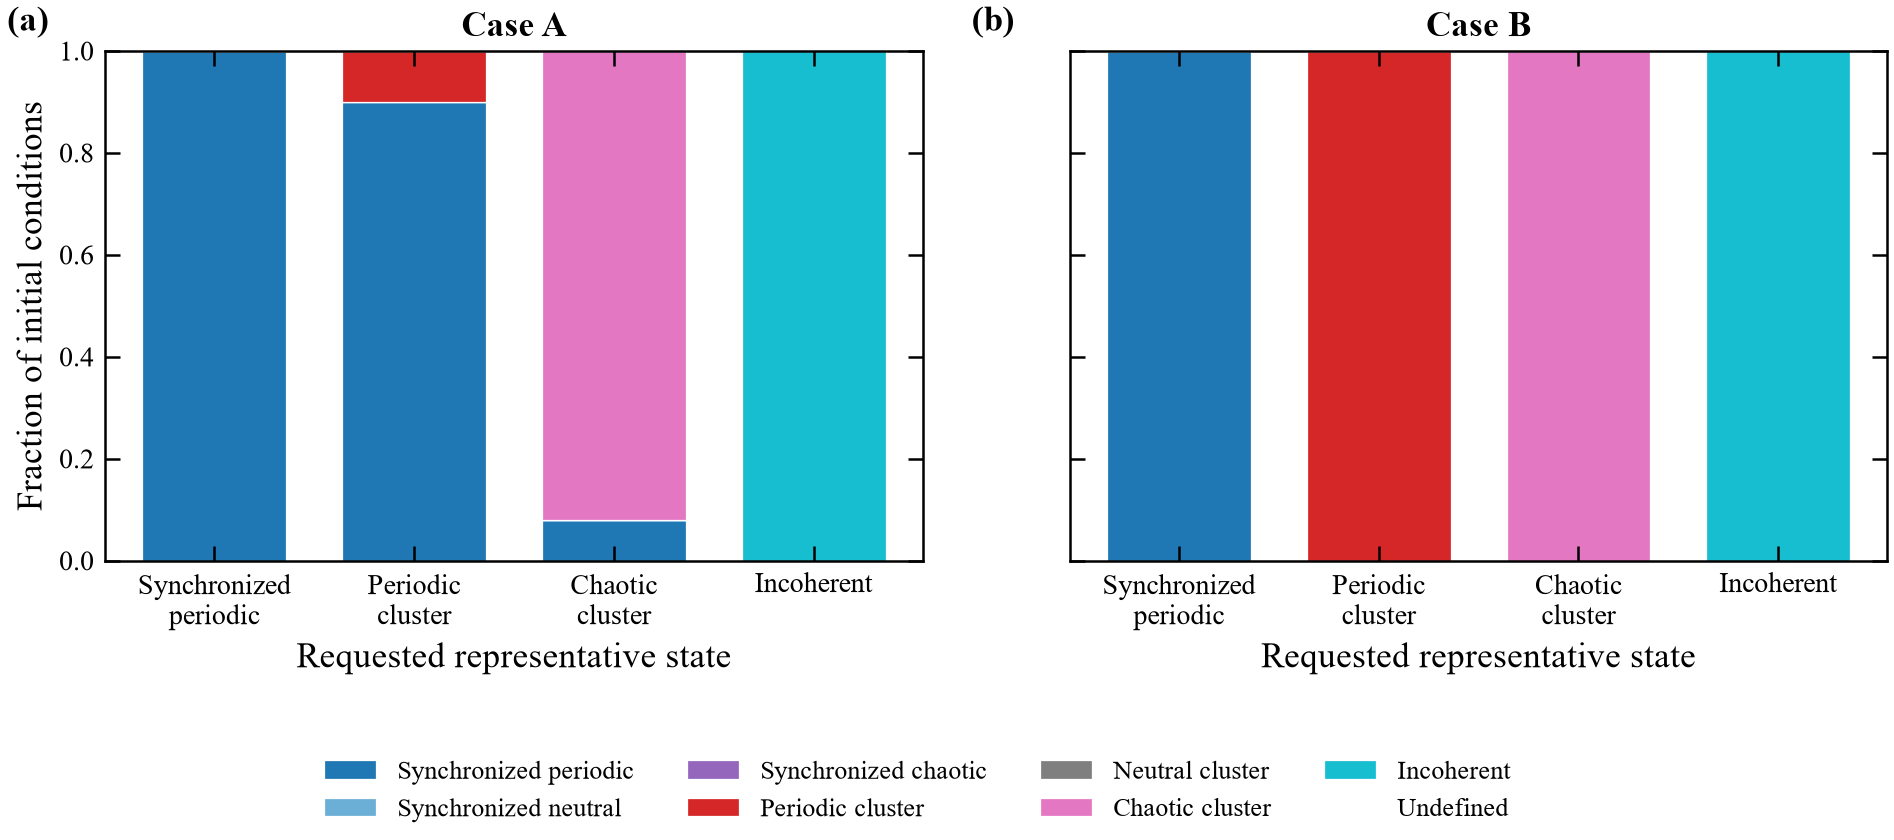

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


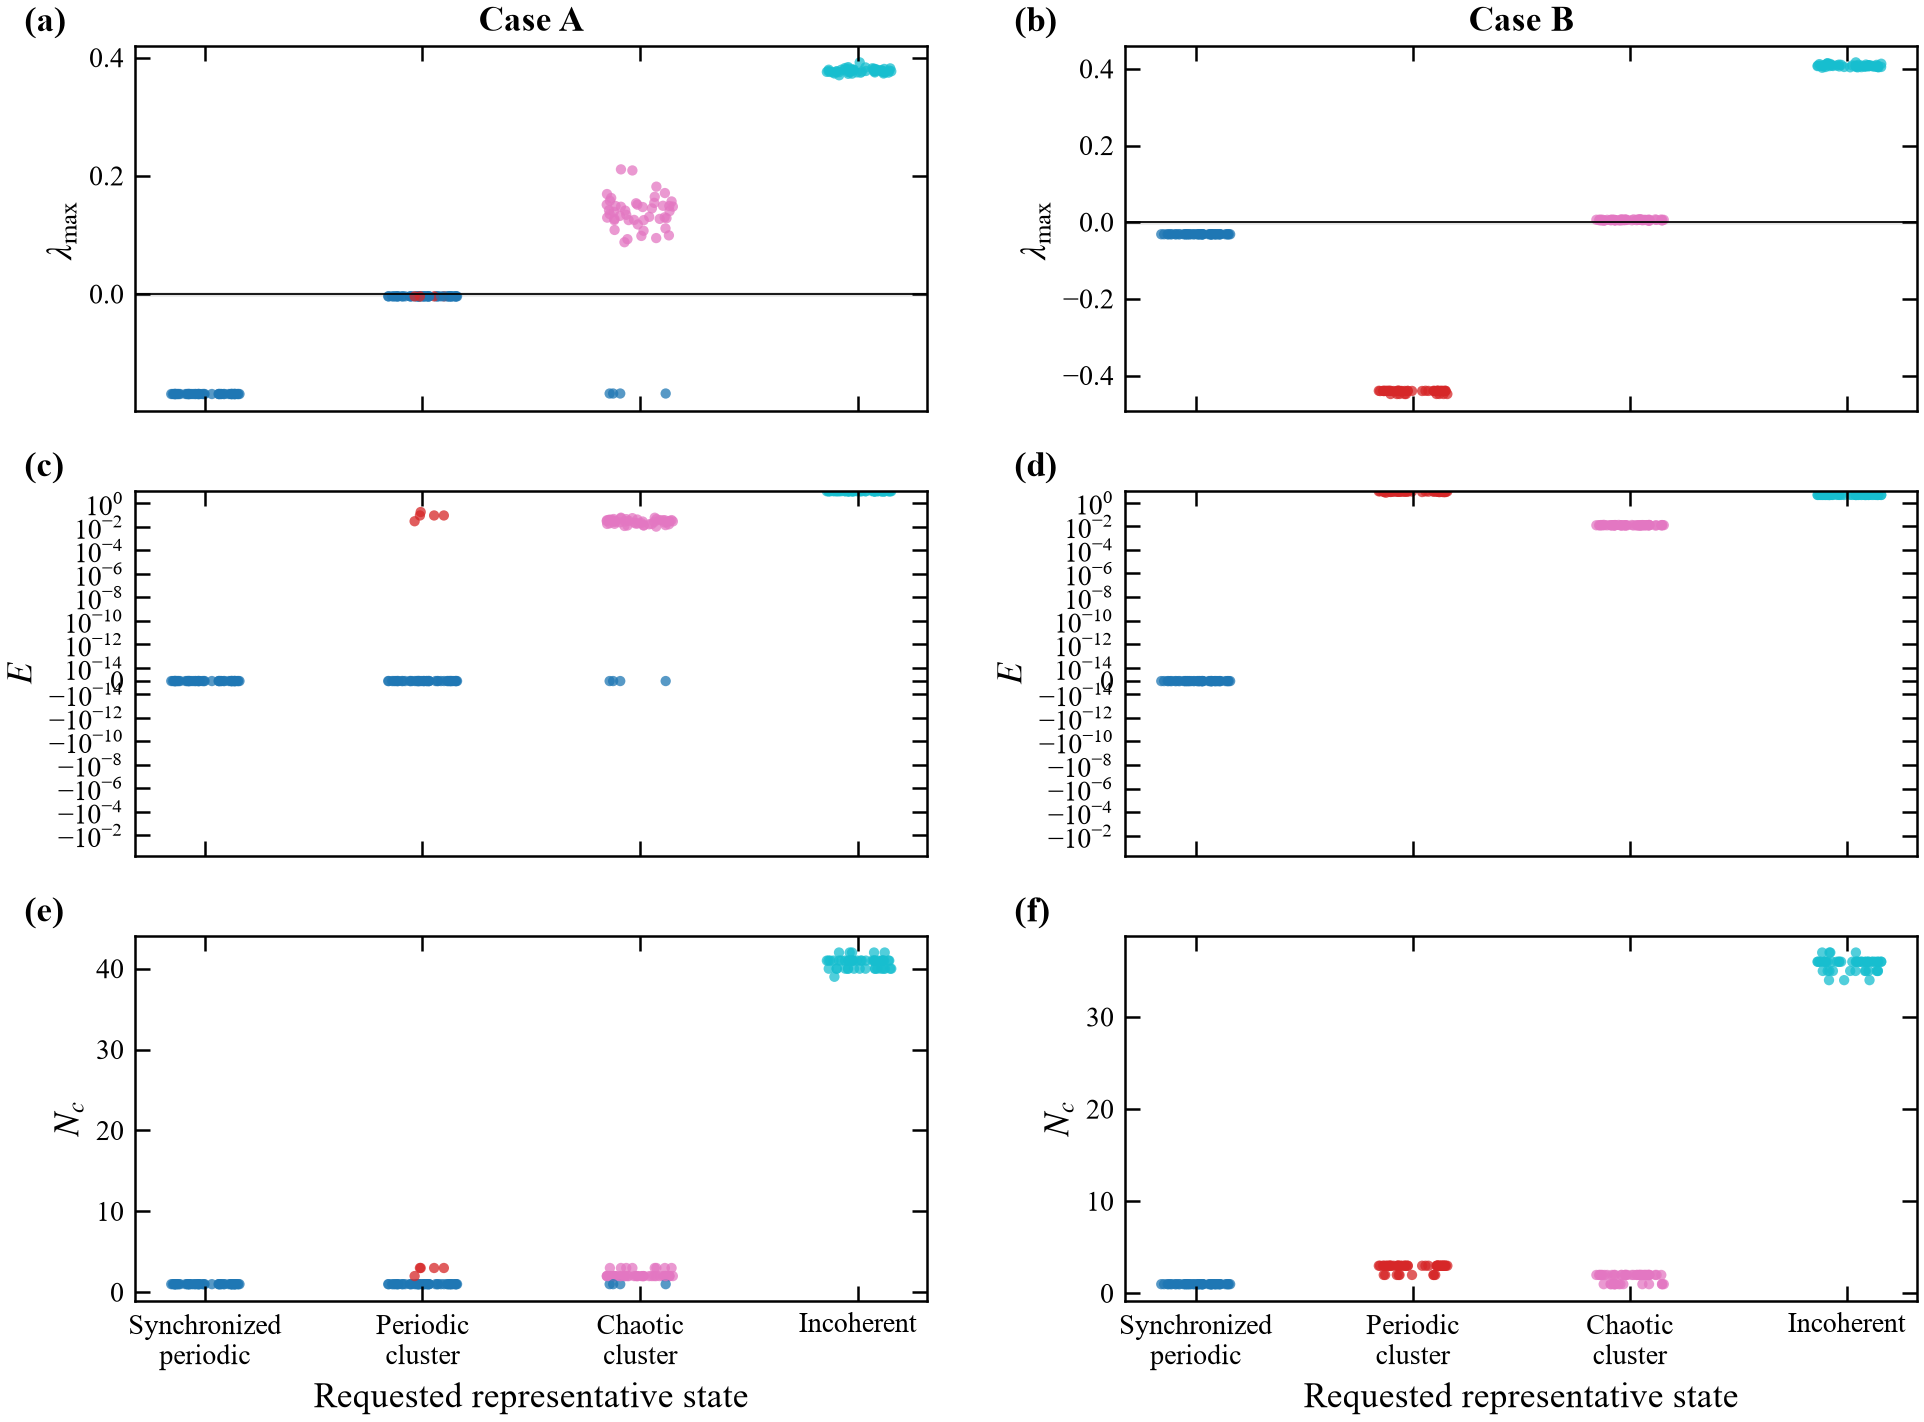


Initial-condition-dependent collective classifications were detected:


,case,state_requested,mu,epsilon,number_of_observed_states,observed_states,dominant_state_fraction,initial_condition_dependence
0,A,Chaotic cluster,-0.575952,0.292786,2,"Chaotic cluster, Synchronized periodic",0.92,True
2,A,Periodic cluster,0.491784,0.017435,2,"Periodic cluster, Synchronized periodic",0.90,True


In [26]:
# ============================================================
# LONG-RUN AND MULTIPLE-INITIAL-CONDITION VERIFICATION
# OF SELECTED VERSION 2 NETWORK STATES
# ============================================================

from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ============================================================
# 1. VERIFICATION SETTINGS
# ============================================================

VERIFICATION_DIRECTORY = (
    RUN_DIRECTORY
    / "representative_verification"
)

VERIFICATION_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)

# Use 10 for an initial test.
# Restore 50 for the final reviewer analysis.
N_VERIFICATION_INITIAL_CONDITIONS = 50

VERIFICATION_NETWORK_SIZE = 50

VERIFICATION_TRANSIENT = 5_000
VERIFICATION_OBSERVATION = 3_000
VERIFICATION_LYAPUNOV_ITERATIONS = 5_000

VERIFICATION_CLUSTER_SAMPLES = 30

VERIFICATION_SEED = 20260906

VERIFICATION_DELTA0 = 1.0e-8
VERIFICATION_ESCAPE_BOUND = 1.0e8

# Use the same thresholds as the Version 2 parameter scan.
VERIFICATION_LAMBDA_TOLERANCE = (
    config.lambda_tolerance
)

VERIFICATION_SYNC_TOLERANCE = (
    config.synchronization_tolerance
)

VERIFICATION_CLUSTER_TOLERANCE = (
    config.cluster_tolerance
)

VERIFICATION_FRAGMENTATION_THRESHOLD = (
    config.fragmentation_threshold
)


# ============================================================
# 2. BUILD THE LIST OF POINTS TO VERIFY
# ============================================================

# Use only points successfully selected by the robust selector.
VERSION2_POINTS_FOR_VERIFICATION = {
    case_name: {
        state_name: {
            "mu": point["mu"],
            "epsilon": point["epsilon"],
            "expected_phase_code": (
                REPRESENTATIVE_PHASE_CODES[
                    state_name
                ]
            ),
        }
        for state_name, point
        in VERSION2_REPRESENTATIVE_POINTS[
            case_name
        ].items()
        if point is not None
    }
    for case_name in ("A", "B")
}


print(
    "Version 2 points selected for verification:\n"
)

for case_name, points in (
    VERSION2_POINTS_FOR_VERIFICATION.items()
):
    print(
        f"Case {case_name}"
    )

    for state_name, point in points.items():
        print(
            f"  {state_name}: "
            f"mu={point['mu']:.6f}, "
            f"epsilon={point['epsilon']:.6f}"
        )


# ============================================================
# 3. SINGLE-TRAJECTORY NETWORK UPDATE
# ============================================================

def coupled_step_single(
    X,
    Y,
    mu,
    a,
    b,
    epsilon,
):
    """
    Advance one coupled Gumowski-Mira ring by one iteration.

    This uses the corrected Version 2 nonlinearity F_v2.
    """
    local_update = (
        a * Y
        * (
            1.0
            - b * Y**2
        )
        + Y
        + F_v2(X, mu)
    )

    left_neighbors = np.roll(
        X,
        shift=1,
    )

    right_neighbors = np.roll(
        X,
        shift=-1,
    )

    X_next = (
        (1.0 - epsilon)
        * local_update
        + 0.5
        * epsilon
        * (
            left_neighbors
            + right_neighbors
        )
    )

    Y_next = (
        -X
        + F_v2(
            X_next,
            mu,
        )
    )

    return (
        X_next,
        Y_next,
    )


def valid_single_network_state(
    X,
    Y,
    escape_bound=VERIFICATION_ESCAPE_BOUND,
):
    """
    Check whether one network state is finite and bounded.
    """
    return bool(
        np.all(np.isfinite(X))
        and np.all(np.isfinite(Y))
        and np.max(np.abs(X))
        <= escape_bound
        and np.max(np.abs(Y))
        <= escape_bound
    )


def synchronization_error_single(X):
    """
    X-based synchronization error used in the parameter maps.
    """
    mean_x = np.mean(X)

    return float(
        np.mean(
            (X - mean_x) ** 2
        )
    )


def cluster_number_single(
    X,
    tolerance=VERIFICATION_CLUSTER_TOLERANCE,
):
    """
    X-based one-dimensional single-linkage cluster number.
    """
    sorted_x = np.sort(
        np.asarray(
            X,
            dtype=float,
        )
    )

    if sorted_x.size == 0:
        return 0

    return int(
        1
        + np.count_nonzero(
            np.diff(sorted_x)
            > tolerance
        )
    )


# ============================================================
# 4. COLLECTIVE-STATE CLASSIFICATION
# ============================================================

VERIFICATION_PHASE_LABELS = {
    0: "Undefined",
    1: "Synchronized periodic",
    2: "Synchronized neutral",
    3: "Synchronized chaotic",
    4: "Periodic cluster",
    5: "Neutral cluster",
    6: "Chaotic cluster",
    7: "Incoherent",
}


def classify_verified_network_state(
    lambda_max,
    synchronization_error_value,
    cluster_number_value,
):
    """
    Apply the same collective-state criteria used in the
    Version 2 parameter-space calculation.
    """
    if not (
        np.isfinite(lambda_max)
        and np.isfinite(
            synchronization_error_value
        )
        and np.isfinite(
            cluster_number_value
        )
    ):
        return (
            0,
            "Undefined",
        )

    synchronized = (
        synchronization_error_value
        <= VERIFICATION_SYNC_TOLERANCE
        and cluster_number_value == 1
    )

    if (
        lambda_max
        < -VERIFICATION_LAMBDA_TOLERANCE
    ):
        temporal_class = "periodic"

    elif (
        lambda_max
        > VERIFICATION_LAMBDA_TOLERANCE
    ):
        temporal_class = "chaotic"

    else:
        temporal_class = "neutral"

    if synchronized:
        phase_code = {
            "periodic": 1,
            "neutral": 2,
            "chaotic": 3,
        }[temporal_class]

    elif (
        cluster_number_value
        <= VERIFICATION_FRAGMENTATION_THRESHOLD
    ):
        phase_code = {
            "periodic": 4,
            "neutral": 5,
            "chaotic": 6,
        }[temporal_class]

    else:
        phase_code = 7

    return (
        phase_code,
        VERIFICATION_PHASE_LABELS[
            phase_code
        ],
    )


# ============================================================
# 5. EVALUATE ONE INITIAL CONDITION
# ============================================================

def evaluate_selected_network_realization(
    case_name,
    state_name,
    mu,
    epsilon,
    expected_phase_code,
    realization_id,
    seed,
    network_size=VERIFICATION_NETWORK_SIZE,
    transient=VERIFICATION_TRANSIENT,
    observation=VERIFICATION_OBSERVATION,
    lyapunov_iterations=(
        VERIFICATION_LYAPUNOV_ITERATIONS
    ),
    cluster_samples=(
        VERIFICATION_CLUSTER_SAMPLES
    ),
):
    """
    Perform a long-run calculation from one random initial state.

    The reference trajectory and its perturbed copy are used for
    the Lyapunov exponent. Synchronization and cluster diagnostics
    are computed from the same reference trajectory.
    """
    parameters = CASES[
        case_name
    ]

    a = parameters["a"]
    b = parameters["b"]

    local_rng = np.random.default_rng(
        seed
    )

    # Reference initial state
    X = local_rng.uniform(
        -1.0,
        1.0,
        network_size,
    )

    Y = local_rng.uniform(
        -1.0,
        1.0,
        network_size,
    )

    initial_mean_x = float(
        np.mean(X)
    )

    initial_mean_y = float(
        np.mean(Y)
    )

    initial_std_x = float(
        np.std(X)
    )

    initial_std_y = float(
        np.std(Y)
    )

    # Random perturbation in the full 2N-dimensional state space
    perturbation = local_rng.normal(
        size=2 * network_size
    )

    perturbation_norm = np.linalg.norm(
        perturbation
    )

    if (
        not np.isfinite(
            perturbation_norm
        )
        or perturbation_norm == 0.0
    ):
        perturbation = np.zeros(
            2 * network_size
        )

        perturbation[0] = 1.0
        perturbation_norm = 1.0

    perturbation *= (
        VERIFICATION_DELTA0
        / perturbation_norm
    )

    X_perturbed = (
        X
        + perturbation[
            :network_size
        ]
    )

    Y_perturbed = (
        Y
        + perturbation[
            network_size:
        ]
    )

    # --------------------------------------------------------
    # Common transient
    # --------------------------------------------------------

    for _ in range(transient):
        with np.errstate(
            over="ignore",
            invalid="ignore",
            divide="ignore",
        ):
            X, Y = coupled_step_single(
                X,
                Y,
                mu,
                a,
                b,
                epsilon,
            )

            (
                X_perturbed,
                Y_perturbed,
            ) = coupled_step_single(
                X_perturbed,
                Y_perturbed,
                mu,
                a,
                b,
                epsilon,
            )

        if not (
            valid_single_network_state(
                X,
                Y,
            )
            and valid_single_network_state(
                X_perturbed,
                Y_perturbed,
            )
        ):
            return {
                "case": case_name,
                "state_requested": state_name,
                "mu": mu,
                "epsilon": epsilon,
                "realization_id": realization_id,
                "seed": seed,
                "expected_phase_code": (
                    expected_phase_code
                ),
                "lambda_max": np.nan,
                "sync_error_mean": np.nan,
                "sync_error_median": np.nan,
                "sync_error_max": np.nan,
                "cluster_number_median": np.nan,
                "cluster_number_min": np.nan,
                "cluster_number_max": np.nan,
                "cluster_temporal_variability": np.nan,
                "observed_phase_code": 0,
                "observed_state": "Undefined",
                "classification_agreement": False,
                "initial_mean_x": initial_mean_x,
                "initial_mean_y": initial_mean_y,
                "initial_std_x": initial_std_x,
                "initial_std_y": initial_std_y,
                "final_mean_x": np.nan,
                "final_mean_y": np.nan,
                "final_std_x": np.nan,
                "final_std_y": np.nan,
                "valid": False,
            }

        difference_x = (
            X_perturbed - X
        )

        difference_y = (
            Y_perturbed - Y
        )

        distance = np.sqrt(
            np.sum(
                difference_x**2
                + difference_y**2
            )
        )

        if (
            not np.isfinite(distance)
            or distance <= 1.0e-300
        ):
            return {
                "case": case_name,
                "state_requested": state_name,
                "mu": mu,
                "epsilon": epsilon,
                "realization_id": realization_id,
                "seed": seed,
                "expected_phase_code": (
                    expected_phase_code
                ),
                "lambda_max": np.nan,
                "sync_error_mean": np.nan,
                "sync_error_median": np.nan,
                "sync_error_max": np.nan,
                "cluster_number_median": np.nan,
                "cluster_number_min": np.nan,
                "cluster_number_max": np.nan,
                "cluster_temporal_variability": np.nan,
                "observed_phase_code": 0,
                "observed_state": "Undefined",
                "classification_agreement": False,
                "initial_mean_x": initial_mean_x,
                "initial_mean_y": initial_mean_y,
                "initial_std_x": initial_std_x,
                "initial_std_y": initial_std_y,
                "final_mean_x": np.nan,
                "final_mean_y": np.nan,
                "final_std_x": np.nan,
                "final_std_y": np.nan,
                "valid": False,
            }

        scale = (
            VERIFICATION_DELTA0
            / distance
        )

        X_perturbed = (
            X
            + difference_x
            * scale
        )

        Y_perturbed = (
            Y
            + difference_y
            * scale
        )

    # --------------------------------------------------------
    # Post-transient calculation
    # --------------------------------------------------------

    total_steps = max(
        observation,
        lyapunov_iterations,
    )

    lyapunov_sum = 0.0
    lyapunov_count = 0

    synchronization_values = []
    cluster_values = []

    cluster_indices = set(
        np.linspace(
            0,
            observation - 1,
            min(
                cluster_samples,
                observation,
            ),
            dtype=int,
        ).tolist()
    )

    for step in range(total_steps):
        with np.errstate(
            over="ignore",
            invalid="ignore",
            divide="ignore",
        ):
            X, Y = coupled_step_single(
                X,
                Y,
                mu,
                a,
                b,
                epsilon,
            )

            (
                X_perturbed,
                Y_perturbed,
            ) = coupled_step_single(
                X_perturbed,
                Y_perturbed,
                mu,
                a,
                b,
                epsilon,
            )

        if not (
            valid_single_network_state(
                X,
                Y,
            )
            and valid_single_network_state(
                X_perturbed,
                Y_perturbed,
            )
        ):
            break

        difference_x = (
            X_perturbed - X
        )

        difference_y = (
            Y_perturbed - Y
        )

        distance = np.sqrt(
            np.sum(
                difference_x**2
                + difference_y**2
            )
        )

        if (
            not np.isfinite(distance)
            or distance <= 1.0e-300
        ):
            break

        if step < lyapunov_iterations:
            lyapunov_sum += np.log(
                distance
                / VERIFICATION_DELTA0
            )

            lyapunov_count += 1

        scale = (
            VERIFICATION_DELTA0
            / distance
        )

        X_perturbed = (
            X
            + difference_x
            * scale
        )

        Y_perturbed = (
            Y
            + difference_y
            * scale
        )

        if step < observation:
            synchronization_values.append(
                synchronization_error_single(
                    X
                )
            )

            if step in cluster_indices:
                cluster_values.append(
                    cluster_number_single(
                        X
                    )
                )

    valid = (
        lyapunov_count
        == lyapunov_iterations
        and len(synchronization_values)
        == observation
        and len(cluster_values) > 0
        and valid_single_network_state(
            X,
            Y,
        )
    )

    if not valid:
        return {
            "case": case_name,
            "state_requested": state_name,
            "mu": mu,
            "epsilon": epsilon,
            "realization_id": realization_id,
            "seed": seed,
            "expected_phase_code": expected_phase_code,
            "lambda_max": np.nan,
            "sync_error_mean": np.nan,
            "sync_error_median": np.nan,
            "sync_error_max": np.nan,
            "cluster_number_median": np.nan,
            "cluster_number_min": np.nan,
            "cluster_number_max": np.nan,
            "cluster_temporal_variability": np.nan,
            "observed_phase_code": 0,
            "observed_state": "Undefined",
            "classification_agreement": False,
            "initial_mean_x": initial_mean_x,
            "initial_mean_y": initial_mean_y,
            "initial_std_x": initial_std_x,
            "initial_std_y": initial_std_y,
            "final_mean_x": np.nan,
            "final_mean_y": np.nan,
            "final_std_x": np.nan,
            "final_std_y": np.nan,
            "valid": False,
        }

    lambda_max = (
        lyapunov_sum
        / lyapunov_count
    )

    synchronization_values = np.asarray(
        synchronization_values
    )

    cluster_values = np.asarray(
        cluster_values
    )

    sync_error_mean = float(
        np.mean(
            synchronization_values
        )
    )

    sync_error_median = float(
        np.median(
            synchronization_values
        )
    )

    sync_error_max = float(
        np.max(
            synchronization_values
        )
    )

    cluster_number_median = int(
        np.rint(
            np.median(
                cluster_values
            )
        )
    )

    cluster_number_min = int(
        np.min(
            cluster_values
        )
    )

    cluster_number_max = int(
        np.max(
            cluster_values
        )
    )

    cluster_temporal_variability = int(
        cluster_number_max
        - cluster_number_min
    )

    (
        observed_phase_code,
        observed_state,
    ) = classify_verified_network_state(
        lambda_max,
        sync_error_mean,
        cluster_number_median,
    )

    return {
        "case": case_name,
        "state_requested": state_name,
        "mu": mu,
        "epsilon": epsilon,
        "realization_id": realization_id,
        "seed": seed,
        "expected_phase_code": expected_phase_code,
        "lambda_max": float(
            lambda_max
        ),
        "sync_error_mean": sync_error_mean,
        "sync_error_median": sync_error_median,
        "sync_error_max": sync_error_max,
        "cluster_number_median": (
            cluster_number_median
        ),
        "cluster_number_min": (
            cluster_number_min
        ),
        "cluster_number_max": (
            cluster_number_max
        ),
        "cluster_temporal_variability": (
            cluster_temporal_variability
        ),
        "observed_phase_code": (
            observed_phase_code
        ),
        "observed_state": observed_state,
        "classification_agreement": (
            observed_phase_code
            == expected_phase_code
        ),
        "initial_mean_x": initial_mean_x,
        "initial_mean_y": initial_mean_y,
        "initial_std_x": initial_std_x,
        "initial_std_y": initial_std_y,
        "final_mean_x": float(
            np.mean(X)
        ),
        "final_mean_y": float(
            np.mean(Y)
        ),
        "final_std_x": float(
            np.std(X)
        ),
        "final_std_y": float(
            np.std(Y)
        ),
        "valid": True,
    }


# ============================================================
# 6. RUN ALL INITIAL CONDITIONS
# ============================================================

def run_representative_verification(
    points_for_verification,
    n_initial_conditions=(
        N_VERIFICATION_INITIAL_CONDITIONS
    ),
):
    """
    Verify all selected states over several initial conditions.
    """
    rows = []

    total_points = sum(
        len(points)
        for points
        in points_for_verification.values()
    )

    point_counter = 0
    start_time = perf_counter()

    for case_name in ("A", "B"):
        points = points_for_verification.get(
            case_name,
            {},
        )

        for state_name, point in points.items():
            point_counter += 1

            print(
                f"\nCase {case_name}, "
                f"{state_name}: "
                f"mu={point['mu']:.6f}, "
                f"epsilon={point['epsilon']:.6f} "
                f"({point_counter}/{total_points})"
            )

            point_start = perf_counter()

            for realization_id in range(
                n_initial_conditions
            ):
                case_offset = (
                    0
                    if case_name == "A"
                    else 10_000_000
                )

                seed = (
                    VERIFICATION_SEED
                    + case_offset
                    + point_counter
                    * 100_000
                    + realization_id
                )

                result = (
                    evaluate_selected_network_realization(
                        case_name=case_name,
                        state_name=state_name,
                        mu=point["mu"],
                        epsilon=point[
                            "epsilon"
                        ],
                        expected_phase_code=(
                            point[
                                "expected_phase_code"
                            ]
                        ),
                        realization_id=(
                            realization_id
                        ),
                        seed=seed,
                    )
                )

                rows.append(
                    result
                )

                if (
                    (realization_id + 1) % 10
                    == 0
                    or realization_id + 1
                    == n_initial_conditions
                ):
                    print(
                        f"  completed "
                        f"{realization_id + 1}/"
                        f"{n_initial_conditions}"
                    )

            print(
                "  point elapsed time: "
                f"{perf_counter() - point_start:.1f} s"
            )

    print(
        "\nTotal verification time: "
        f"{perf_counter() - start_time:.1f} s"
    )

    return pd.DataFrame(
        rows
    )


verification_results = (
    run_representative_verification(
        VERSION2_POINTS_FOR_VERIFICATION
    )
)

verification_results.to_csv(
    VERIFICATION_DIRECTORY
    / "Version2_representative_initial_conditions.csv",
    index=False,
)

display(
    verification_results.head()
)


# ============================================================
# 7. OBSERVED STATE FRACTIONS
# ============================================================

verification_state_counts = (
    verification_results
    .groupby(
        [
            "case",
            "state_requested",
            "mu",
            "epsilon",
            "observed_state",
        ],
        dropna=False,
    )
    .size()
    .rename("count")
    .reset_index()
)

verification_state_counts[
    "fraction"
] = (
    verification_state_counts
    .groupby(
        [
            "case",
            "state_requested",
            "mu",
            "epsilon",
        ]
    )["count"]
    .transform(
        lambda values: (
            values
            / values.sum()
        )
    )
)

verification_state_counts.to_csv(
    VERIFICATION_DIRECTORY
    / "Version2_representative_state_fractions.csv",
    index=False,
)

display(
    verification_state_counts
)


# ============================================================
# 8. NUMERICAL SUMMARY
# ============================================================

verification_summary = (
    verification_results
    .groupby(
        [
            "case",
            "state_requested",
            "mu",
            "epsilon",
        ]
    )
    .agg(
        realizations=(
            "realization_id",
            "count",
        ),
        valid_realizations=(
            "valid",
            "sum",
        ),
        agreement_fraction=(
            "classification_agreement",
            "mean",
        ),
        lambda_min=(
            "lambda_max",
            "min",
        ),
        lambda_max=(
            "lambda_max",
            "max",
        ),
        lambda_mean=(
            "lambda_max",
            "mean",
        ),
        lambda_std=(
            "lambda_max",
            "std",
        ),
        sync_error_min=(
            "sync_error_mean",
            "min",
        ),
        sync_error_max=(
            "sync_error_mean",
            "max",
        ),
        sync_error_median=(
            "sync_error_mean",
            "median",
        ),
        cluster_min=(
            "cluster_number_median",
            "min",
        ),
        cluster_max=(
            "cluster_number_median",
            "max",
        ),
        cluster_median=(
            "cluster_number_median",
            "median",
        ),
        maximum_cluster_variability=(
            "cluster_temporal_variability",
            "max",
        ),
        final_mean_x_min=(
            "final_mean_x",
            "min",
        ),
        final_mean_x_max=(
            "final_mean_x",
            "max",
        ),
    )
    .reset_index()
)

verification_summary.to_csv(
    VERIFICATION_DIRECTORY
    / "Version2_representative_verification_summary.csv",
    index=False,
)

display(
    verification_summary
)


# ============================================================
# 9. IDENTIFY INITIAL-CONDITION DEPENDENCE
# ============================================================

verification_coexistence = (
    verification_state_counts
    .groupby(
        [
            "case",
            "state_requested",
            "mu",
            "epsilon",
        ]
    )
    .agg(
        number_of_observed_states=(
            "observed_state",
            "nunique",
        ),
        observed_states=(
            "observed_state",
            lambda values: ", ".join(
                sorted(
                    set(values)
                )
            ),
        ),
        dominant_state_fraction=(
            "fraction",
            "max",
        ),
    )
    .reset_index()
)

verification_coexistence[
    "initial_condition_dependence"
] = (
    verification_coexistence[
        "number_of_observed_states"
    ] > 1
)

verification_coexistence.to_csv(
    VERIFICATION_DIRECTORY
    / "Version2_representative_coexistence_summary.csv",
    index=False,
)

display(
    verification_coexistence
)


# ============================================================
# 10. PUBLICATION-READY STATE-FRACTION PLOT
# ============================================================

STATE_ORDER = [
    "Synchronized periodic",
    "Synchronized neutral",
    "Synchronized chaotic",
    "Periodic cluster",
    "Neutral cluster",
    "Chaotic cluster",
    "Incoherent",
    "Undefined",
]

STATE_COLORS = {
    "Synchronized periodic": "#1F77B4",
    "Synchronized neutral": "#6BAED6",
    "Synchronized chaotic": "#9467BD",
    "Periodic cluster": "#D62728",
    "Neutral cluster": "#7F7F7F",
    "Chaotic cluster": "#E377C2",
    "Incoherent": "#17BECF",
    "Undefined": "#FFFFFF",
}


def plot_verification_state_fractions(
    state_counts,
):
    """
    Plot observed collective-state fractions over initial states.
    """
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(11.0, 4.8),
        sharey=True,
        constrained_layout=False,
    )

    for column, case_name in enumerate(
        ("A", "B")
    ):
        axis = axes[
            column
        ]

        subset = state_counts.loc[
            state_counts["case"]
            == case_name
        ].copy()

        requested_order = [
            state_name
            for state_name in (
                REPRESENTATIVE_PHASE_CODES
            )
            if state_name
            in subset[
                "state_requested"
            ].unique()
        ]

        x_positions = np.arange(
            len(requested_order)
        )

        bottom = np.zeros(
            len(requested_order)
        )

        for observed_state in STATE_ORDER:
            fractions = []

            for requested_state in (
                requested_order
            ):
                selected = subset.loc[
                    (
                        subset[
                            "state_requested"
                        ]
                        == requested_state
                    )
                    &
                    (
                        subset[
                            "observed_state"
                        ]
                        == observed_state
                    ),
                    "fraction",
                ]

                if selected.empty:
                    fractions.append(
                        0.0
                    )
                else:
                    fractions.append(
                        float(
                            selected.iloc[0]
                        )
                    )

            fractions = np.asarray(
                fractions
            )

            axis.bar(
                x_positions,
                fractions,
                bottom=bottom,
                width=0.72,
                color=STATE_COLORS[
                    observed_state
                ],
                edgecolor="white",
                linewidth=0.5,
                label=observed_state,
            )

            bottom += fractions

        axis.set_xticks(
            x_positions
        )

        axis.set_xticklabels(
            [
                state.replace(
                    " ",
                    "\n",
                )
                for state in requested_order
            ],
            fontsize=10.5,
        )

        axis.set_ylim(
            0.0,
            1.0,
        )

        axis.set_xlabel(
            "Requested representative state",
            fontsize=14,
        )

        axis.set_title(
            f"Case {case_name}",
            fontsize=14,
        )

        axis.tick_params(
            which="both",
            direction="in",
            top=True,
            right=True,
            labelsize=11,
        )

        axis.text(
            -0.12,
            1.04,
            "(a)" if column == 0
            else "(b)",
            transform=axis.transAxes,
            fontsize=14,
            fontweight="bold",
        )

    axes[0].set_ylabel(
        "Fraction of initial conditions",
        fontsize=14,
    )

    handles, labels = (
        axes[0]
        .get_legend_handles_labels()
    )

    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=4,
        frameon=False,
        bbox_to_anchor=(
            0.5,
            -0.02,
        ),
        fontsize=10.5,
    )

    fig.subplots_adjust(
        left=0.09,
        right=0.99,
        top=0.90,
        bottom=0.31,
        wspace=0.18,
    )

    fig.savefig(
        VERIFICATION_DIRECTORY
        / "Version2_state_fraction_verification.pdf",
        bbox_inches="tight",
    )

    fig.savefig(
        VERIFICATION_DIRECTORY
        / "Version2_state_fraction_verification.png",
        dpi=600,
        bbox_inches="tight",
    )
    fig.savefig(
        VERIFICATION_DIRECTORY
        / "Version2_state_fraction_verification.eps",
        bbox_inches="tight",
    )

    plt.show()
    plt.close()

    return (
        fig,
        axes,
    )


(
    verification_fraction_figure,
    verification_fraction_axes,
) = plot_verification_state_fractions(
    verification_state_counts
)


# ============================================================
# 11. PUBLICATION-READY DIAGNOSTIC SPREAD PLOT
# ============================================================

def plot_verification_diagnostic_spread(
    data,
):
    """
    Plot the spread of lambda_max, E, and Nc across initial states.
    """
    fig, axes = plt.subplots(
        3,
        2,
        figsize=(11.0, 8.4),
        sharex="col",
    )

    metrics = [
        "lambda_max",
        "sync_error_mean",
        "cluster_number_median",
    ]

    y_labels = [
        r"$\lambda_{\max}$",
        r"$E$",
        r"$N_c$",
    ]

    for column, case_name in enumerate(
        ("A", "B")
    ):
        subset = data.loc[
            data["case"]
            == case_name
        ].copy()

        requested_order = [
            state_name
            for state_name in (
                REPRESENTATIVE_PHASE_CODES
            )
            if state_name
            in subset[
                "state_requested"
            ].unique()
        ]

        position_map = {
            state_name: position
            for position, state_name
            in enumerate(
                requested_order
            )
        }

        base_positions = (
            subset[
                "state_requested"
            ]
            .map(position_map)
            .to_numpy(
                dtype=float
            )
        )

        local_rng = np.random.default_rng(
            VERIFICATION_SEED
            + 50_000
            + column
        )

        jitter = local_rng.uniform(
            -0.16,
            0.16,
            len(subset),
        )

        plotted_positions = (
            base_positions
            + jitter
        )

        point_colors = (
            subset[
                "observed_state"
            ]
            .map(
                STATE_COLORS
            )
            .fillna(
                "#BDBDBD"
            )
            .to_numpy()
        )

        for row, (
            metric,
            y_label,
        ) in enumerate(
            zip(
                metrics,
                y_labels,
            )
        ):
            axis = axes[
                row,
                column,
            ]

            axis.scatter(
                plotted_positions,
                subset[metric],
                color=point_colors,
                s=17,
                alpha=0.75,
                linewidths=0,
            )

            axis.set_ylabel(
                y_label,
                fontsize=14,
            )

            axis.set_xticks(
                np.arange(
                    len(
                        requested_order
                    )
                )
            )

            axis.set_xticklabels(
                [
                    state.replace(
                        " ",
                        "\n",
                    )
                    for state in (
                        requested_order
                    )
                ],
                fontsize=10.5,
            )

            axis.tick_params(
                which="both",
                direction="in",
                top=True,
                right=True,
                labelsize=11,
            )

            if metric == "lambda_max":
                axis.axhspan(
                    -VERIFICATION_LAMBDA_TOLERANCE,
                    VERIFICATION_LAMBDA_TOLERANCE,
                    color="#D9D9D9",
                    alpha=0.60,
                    zorder=0,
                )

                axis.axhline(
                    0.0,
                    color="black",
                    linewidth=0.7,
                )

            if metric == "sync_error_mean":
                axis.set_yscale(
                    "symlog",
                    linthresh=1.0e-14,
                )

        axes[0, column].set_title(
            f"Case {case_name}",
            fontsize=14,
        )

        axes[2, column].set_xlabel(
            "Requested representative state",
            fontsize=14,
        )

    panel_labels = [
        "(a)",
        "(b)",
        "(c)",
        "(d)",
        "(e)",
        "(f)",
    ]

    for panel_label, axis in zip(
        panel_labels,
        axes.flat,
    ):
        axis.text(
            -0.14,
            1.04,
            panel_label,
            transform=axis.transAxes,
            fontsize=14,
            fontweight="bold",
        )

    fig.subplots_adjust(
        left=0.09,
        right=0.99,
        top=0.94,
        bottom=0.11,
        wspace=0.25,
        hspace=0.22,
    )

    fig.savefig(
        VERIFICATION_DIRECTORY
        / "Version2_diagnostic_spread_verification.pdf",
        bbox_inches="tight",
    )

    fig.savefig(
        VERIFICATION_DIRECTORY
        / "Version2_diagnostic_spread_verification.png",
        dpi=600,
        bbox_inches="tight",
    )
    fig.savefig(
        VERIFICATION_DIRECTORY
        / "Version2_diagnostic_spread_verification.eps",
        bbox_inches="tight",
    )

    plt.show()
    plt.close()

    return (
        fig,
        axes,
    )


(
    verification_spread_figure,
    verification_spread_axes,
) = plot_verification_diagnostic_spread(
    verification_results
)


# ============================================================
# 12. FINAL REPORT
# ============================================================

dependent_points = (
    verification_coexistence.loc[
        verification_coexistence[
            "initial_condition_dependence"
        ]
    ]
)

if dependent_points.empty:
    print(
        "\nNo coexistence of different collective-state "
        "classifications was detected at the tested "
        "representative parameter pairs."
    )

    print(
        "This does not rule out geometrically distinct "
        "collective attractors belonging to the same "
        "numerical class."
    )

else:
    print(
        "\nInitial-condition-dependent collective "
        "classifications were detected:"
    )

    display(
        dependent_points
    )

## Figure 7: verified state fractions

Build the state-fraction summary from the verification CSV and check the reported fractions against the manuscript values.



Figure 7 input validation:

case       state_requested  rows  unique_realization_ids  unique_seeds  valid_rows  unique_mu_values  unique_epsilon_values        mu  epsilon  row_count_valid  realization_ids_valid  seeds_valid  all_rows_valid  coordinates_valid  all_checks_passed
   A       Chaotic cluster    50                      50            50          50                 1                      1 -0.575952 0.292786             True                   True         True            True               True               True
   A            Incoherent    50                      50            50          50                 1                      1 -0.494188 0.099198             True                   True         True            True               True               True
   A      Periodic cluster    50                      50            50          50                 1                      1  0.491784 0.017435             True                   True         True            True          

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


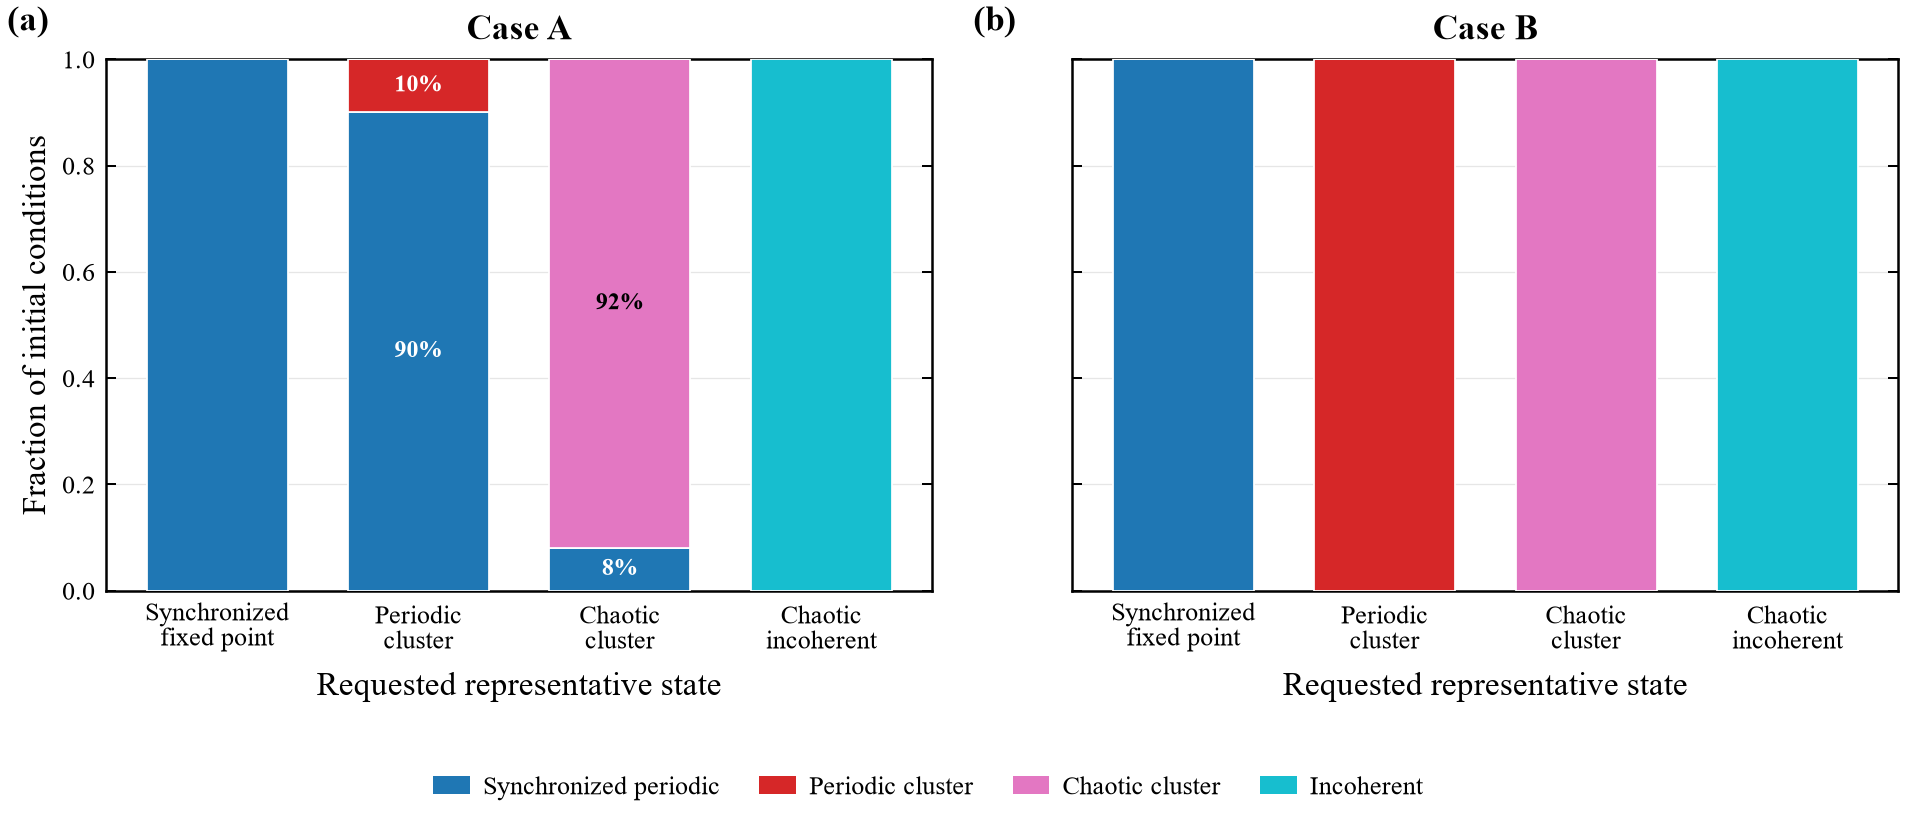


Manuscript percentage check:

case       state_requested        observed_state  expected_fraction  actual_fraction  matches
   A Synchronized periodic Synchronized periodic               1.00             1.00     True
   A      Periodic cluster Synchronized periodic               0.90             0.90     True
   A      Periodic cluster      Periodic cluster               0.10             0.10     True
   A       Chaotic cluster Synchronized periodic               0.08             0.08     True
   A       Chaotic cluster       Chaotic cluster               0.92             0.92     True
   A            Incoherent            Incoherent               1.00             1.00     True
   B Synchronized periodic Synchronized periodic               1.00             1.00     True
   B      Periodic cluster      Periodic cluster               1.00             1.00     True
   B       Chaotic cluster       Chaotic cluster               1.00             1.00     True
   B            Incoherent   

In [27]:
# ============================================================
# COMPLETE STANDALONE PUBLICATION-READY FIGURE 7 WORKFLOW
# ============================================================
#
# Reads the existing 400-row verification file and generates:
#   1. Version2_state_fraction_verification.pdf
#   2. Version2_state_fraction_verification.png
#   3. Version2_representative_state_fractions.csv
#   4. Version2_Figure7_plotted_fractions.csv
#   5. Version2_Figure7_validation.csv
#
# The legend contains only classes that actually occur.
# Mixed bars are annotated with percentages.
# ============================================================

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch


# ============================================================
# 1. USER SETTINGS
# ============================================================

RUN_DIRECTORY = Path(RUN_DIRECTORY)

VERIFICATION_DIRECTORY = (
    RUN_DIRECTORY
    / "representative_verification"
)

INPUT_CSV = (
    VERIFICATION_DIRECTORY
    / "Version2_representative_initial_conditions.csv"
)

OUTPUT_PDF = (
    VERIFICATION_DIRECTORY
    / "Version2_state_fraction_verification.pdf"
)

OUTPUT_PNG = (
    VERIFICATION_DIRECTORY
    / "Version2_state_fraction_verification.png"
)

EXPECTED_CASES = ["A", "B"]
EXPECTED_REALIZATIONS_PER_POINT = 50
EXPECTED_TOTAL_ROWS = 400

ANNOTATE_MIXED_BARS = True
MINIMUM_ANNOTATION_FRACTION = 0.04


# ============================================================
# 2. STATE ORDER, LABELS, AND COLORS
# ============================================================

ALL_STATE_ORDER = [
    "Synchronized periodic",
    "Synchronized neutral",
    "Synchronized chaotic",
    "Periodic cluster",
    "Neutral cluster",
    "Chaotic cluster",
    "Incoherent",
    "Undefined",
]

REQUESTED_STATE_ORDER = [
    "Synchronized periodic",
    "Periodic cluster",
    "Chaotic cluster",
    "Incoherent",
]

REQUESTED_STATE_LABELS = {
    "Synchronized periodic": "Synchronized\nfixed point",
    "Periodic cluster": "Periodic\ncluster",
    "Chaotic cluster": "Chaotic\ncluster",
    "Incoherent": "Chaotic\nincoherent",
}

OBSERVED_STATE_LABELS = {
    "Synchronized periodic": "Synchronized periodic",
    "Synchronized neutral": "Synchronized neutral",
    "Synchronized chaotic": "Synchronized chaotic",
    "Periodic cluster": "Periodic cluster",
    "Neutral cluster": "Neutral cluster",
    "Chaotic cluster": "Chaotic cluster",
    "Incoherent": "Incoherent",
    "Undefined": "Undefined",
}

STATE_COLORS = {
    "Synchronized periodic": "#1F77B4",
    "Synchronized neutral": "#6BAED6",
    "Synchronized chaotic": "#9467BD",
    "Periodic cluster": "#D62728",
    "Neutral cluster": "#7F7F7F",
    "Chaotic cluster": "#E377C2",
    "Incoherent": "#17BECF",
    "Undefined": "#FFFFFF",
}


# ============================================================
# 3. PUBLICATION STYLE
# ============================================================

plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": [
            "Times New Roman",
            "Times",
            "DejaVu Serif",
        ],
        "mathtext.fontset": "stix",
        "font.size": 12,
        "axes.labelsize": 13,
        "axes.titlesize": 14,
        "axes.linewidth": 1.0,
        "xtick.labelsize": 10.5,
        "ytick.labelsize": 10.5,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.top": True,
        "ytick.right": True,
        "xtick.major.size": 5.5,
        "ytick.major.size": 5.5,
        "xtick.major.width": 1.0,
        "ytick.major.width": 1.0,
        "figure.dpi": 180,
        "savefig.dpi": 600,
        "savefig.bbox": "tight",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)


# ============================================================
# 4. HELPERS
# ============================================================

def convert_to_boolean(series, column_name):
    """Convert a Boolean-like CSV column safely."""

    if pd.api.types.is_bool_dtype(series):
        return series.astype(bool)

    converted = (
        series.astype(str)
        .str.strip()
        .str.lower()
        .map(
            {
                "true": True,
                "false": False,
                "1": True,
                "0": False,
                "yes": True,
                "no": False,
            }
        )
    )

    if converted.isna().any():
        bad_values = sorted(
            series.loc[converted.isna()]
            .astype(str)
            .unique()
            .tolist()
        )
        raise ValueError(
            "Unable to interpret values in "
            + column_name
            + ": "
            + ", ".join(bad_values)
        )

    return converted.astype(bool)


def requested_label(state_name):
    """Return the publication label for one requested state."""
    return REQUESTED_STATE_LABELS[state_name]


# ============================================================
# 5. LOAD AND CLEAN THE 400-ROW VERIFICATION FILE
# ============================================================

VERIFICATION_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)

if not INPUT_CSV.is_file():
    raise FileNotFoundError(
        "The verification CSV was not found:\n"
        + str(INPUT_CSV)
    )

verification_results = pd.read_csv(INPUT_CSV)

required_columns = {
    "case",
    "state_requested",
    "observed_state",
    "valid",
    "mu",
    "epsilon",
    "realization_id",
    "seed",
}

missing_columns = required_columns - set(verification_results.columns)

if missing_columns:
    raise KeyError(
        "The verification CSV is missing: "
        + ", ".join(sorted(missing_columns))
    )

for column_name in [
    "case",
    "state_requested",
    "observed_state",
]:
    verification_results[column_name] = (
        verification_results[column_name]
        .astype(str)
        .str.strip()
    )

verification_results["valid"] = convert_to_boolean(
    verification_results["valid"],
    "valid",
)

for column_name in [
    "mu",
    "epsilon",
    "realization_id",
    "seed",
]:
    verification_results[column_name] = pd.to_numeric(
        verification_results[column_name],
        errors="raise",
    )

expected_pairs = {
    (case_name, state_name)
    for case_name in EXPECTED_CASES
    for state_name in REQUESTED_STATE_ORDER
}

actual_pairs = set(
    zip(
        verification_results["case"],
        verification_results["state_requested"],
    )
)

missing_pairs = expected_pairs - actual_pairs

if missing_pairs:
    raise RuntimeError(
        "Missing case-state pairs: "
        + ", ".join(str(value) for value in sorted(missing_pairs))
    )

# Retain only the final eight requested case-state pairs.
verification_results = verification_results.loc[
    [
        (case_value, state_value) in expected_pairs
        for case_value, state_value in zip(
            verification_results["case"],
            verification_results["state_requested"],
        )
    ]
].copy()


# ============================================================
# 6. VALIDATE REALIZATION COUNTS AND COORDINATES
# ============================================================

validation = (
    verification_results.groupby(
        ["case", "state_requested"],
        as_index=False,
    )
    .agg(
        rows=("realization_id", "count"),
        unique_realization_ids=("realization_id", "nunique"),
        unique_seeds=("seed", "nunique"),
        valid_rows=("valid", "sum"),
        unique_mu_values=("mu", "nunique"),
        unique_epsilon_values=("epsilon", "nunique"),
        mu=("mu", "first"),
        epsilon=("epsilon", "first"),
    )
)

validation["row_count_valid"] = (
    validation["rows"] == EXPECTED_REALIZATIONS_PER_POINT
)
validation["realization_ids_valid"] = (
    validation["unique_realization_ids"]
    == EXPECTED_REALIZATIONS_PER_POINT
)
validation["seeds_valid"] = (
    validation["unique_seeds"]
    == EXPECTED_REALIZATIONS_PER_POINT
)
validation["all_rows_valid"] = (
    validation["valid_rows"] == validation["rows"]
)
validation["coordinates_valid"] = (
    (validation["unique_mu_values"] == 1)
    & (validation["unique_epsilon_values"] == 1)
)
validation["all_checks_passed"] = validation[
    [
        "row_count_valid",
        "realization_ids_valid",
        "seeds_valid",
        "all_rows_valid",
        "coordinates_valid",
    ]
].all(axis=1)

validation.to_csv(
    VERIFICATION_DIRECTORY
    / "Version2_Figure7_validation.csv",
    index=False,
)

print("\nFigure 7 input validation:\n")
print(validation.to_string(index=False))

if len(verification_results) != EXPECTED_TOTAL_ROWS:
    raise RuntimeError(
        "Expected 400 rows but found "
        + str(len(verification_results))
        + "."
    )

if len(validation) != 8:
    raise RuntimeError(
        "Expected eight case-state groups but found "
        + str(len(validation))
        + "."
    )

if not validation["all_checks_passed"].all():
    raise RuntimeError(
        "At least one representative point failed validation."
    )

print(
    "\nSUCCESS: all eight parameter pairs contain "
    "50 unique and valid realizations."
)


# ============================================================
# 7. CALCULATE EXACT COUNTS AND FRACTIONS
# ============================================================

state_counts = (
    verification_results.groupby(
        [
            "case",
            "state_requested",
            "mu",
            "epsilon",
            "observed_state",
        ],
        as_index=False,
        dropna=False,
    )
    .agg(count=("realization_id", "count"))
)

state_counts["total"] = (
    state_counts.groupby(
        ["case", "state_requested", "mu", "epsilon"]
    )["count"]
    .transform("sum")
)

state_counts["fraction"] = (
    state_counts["count"] / state_counts["total"]
)
state_counts["percentage"] = 100.0 * state_counts["fraction"]

state_counts = state_counts.sort_values(
    ["case", "state_requested", "observed_state"]
).reset_index(drop=True)

state_counts.to_csv(
    VERIFICATION_DIRECTORY
    / "Version2_representative_state_fractions.csv",
    index=False,
)

print("\nExact nonzero fractions:\n")
print(state_counts.to_string(index=False))


# ============================================================
# 8. DETERMINE WHICH OBSERVED CLASSES ACTUALLY APPEAR
# ============================================================

appearing_state_set = set(
    state_counts.loc[
        state_counts["fraction"] > 0.0,
        "observed_state",
    ]
)

unknown_states = appearing_state_set - set(ALL_STATE_ORDER)

if unknown_states:
    raise RuntimeError(
        "Unknown observed states: "
        + ", ".join(sorted(unknown_states))
    )

APPEARING_STATE_ORDER = [
    state_name
    for state_name in ALL_STATE_ORDER
    if state_name in appearing_state_set
]

if not APPEARING_STATE_ORDER:
    raise RuntimeError("No observed classes have positive fractions.")

print("\nFigure 7 legend entries:")
for state_name in APPEARING_STATE_ORDER:
    print("  " + OBSERVED_STATE_LABELS[state_name])


# ============================================================
# 9. CREATE A COMPLETE PLOTTING TABLE
# ============================================================

plot_rows = []

for case_name in EXPECTED_CASES:
    for requested_state in REQUESTED_STATE_ORDER:
        coordinate_row = validation.loc[
            (validation["case"] == case_name)
            & (validation["state_requested"] == requested_state)
        ]

        if len(coordinate_row) != 1:
            raise RuntimeError(
                "No unique coordinate for "
                + case_name
                + ", "
                + requested_state
                + "."
            )

        mu = float(coordinate_row["mu"].iloc[0])
        epsilon = float(coordinate_row["epsilon"].iloc[0])

        for observed_state in APPEARING_STATE_ORDER:
            match = state_counts.loc[
                (state_counts["case"] == case_name)
                & (state_counts["state_requested"] == requested_state)
                & (state_counts["observed_state"] == observed_state)
            ]

            if match.empty:
                count = 0
                fraction = 0.0
            else:
                count = int(match["count"].sum())
                fraction = float(match["fraction"].sum())

            plot_rows.append(
                {
                    "case": case_name,
                    "state_requested": requested_state,
                    "requested_display_name": requested_label(
                        requested_state
                    ).replace("\n", " "),
                    "mu": mu,
                    "epsilon": epsilon,
                    "observed_state": observed_state,
                    "count": count,
                    "fraction": fraction,
                    "percentage": 100.0 * fraction,
                }
            )

plot_data = pd.DataFrame(plot_rows)

plot_data.to_csv(
    VERIFICATION_DIRECTORY
    / "Version2_Figure7_plotted_fractions.csv",
    index=False,
)

bar_check = (
    plot_data.groupby(
        ["case", "state_requested"],
        as_index=False,
    )
    .agg(
        count_sum=("count", "sum"),
        fraction_sum=("fraction", "sum"),
    )
)

bar_check["count_valid"] = (
    bar_check["count_sum"] == EXPECTED_REALIZATIONS_PER_POINT
)
bar_check["fraction_valid"] = np.isclose(
    bar_check["fraction_sum"],
    1.0,
    atol=1.0e-12,
    rtol=0.0,
)
bar_check["all_checks_passed"] = (
    bar_check["count_valid"] & bar_check["fraction_valid"]
)

if not bar_check["all_checks_passed"].all():
    raise RuntimeError("At least one stacked bar failed validation.")

print("\nSUCCESS: every stacked bar contains 50 rows and sums to one.")


# ============================================================
# 10. PLOT FIGURE 7
# ============================================================

def plot_figure_7(data):
    """Create the final publication-ready state-fraction figure."""

    figure, axes = plt.subplots(
        1,
        2,
        figsize=(11.0, 4.8),
        sharey=True,
        constrained_layout=False,
    )

    x_positions = np.arange(len(REQUESTED_STATE_ORDER))

    for column, case_name in enumerate(EXPECTED_CASES):
        axis = axes[column]
        case_data = data.loc[data["case"] == case_name].copy()
        bottoms = np.zeros(len(REQUESTED_STATE_ORDER), dtype=float)

        for observed_state in APPEARING_STATE_ORDER:
            fractions = np.array(
                [
                    float(
                        case_data.loc[
                            (
                                case_data["state_requested"]
                                == requested_state
                            )
                            & (
                                case_data["observed_state"]
                                == observed_state
                            ),
                            "fraction",
                        ].sum()
                    )
                    for requested_state in REQUESTED_STATE_ORDER
                ],
                dtype=float,
            )

            if np.allclose(
                fractions,
                0.0,
                atol=1.0e-15,
                rtol=0.0,
            ):
                continue

            axis.bar(
                x_positions,
                fractions,
                bottom=bottoms,
                width=0.70,
                color=STATE_COLORS[observed_state],
                edgecolor="white",
                linewidth=0.7,
                zorder=3,
            )

            bottoms += fractions

        if not np.allclose(
            bottoms,
            1.0,
            atol=1.0e-12,
            rtol=0.0,
        ):
            raise RuntimeError(
                "Plotted bars do not sum to one for Case "
                + case_name
                + "."
            )

        # Percentage labels only for mixed bars.
        if ANNOTATE_MIXED_BARS:
            for position, requested_state in enumerate(
                REQUESTED_STATE_ORDER
            ):
                mixed_data = case_data.loc[
                    (case_data["state_requested"] == requested_state)
                    & (case_data["fraction"] > 0.0),
                    ["observed_state", "fraction"],
                ]

                if len(mixed_data) <= 1:
                    continue

                annotation_bottom = 0.0

                for observed_state in APPEARING_STATE_ORDER:
                    selected = mixed_data.loc[
                        mixed_data["observed_state"] == observed_state,
                        "fraction",
                    ]

                    if selected.empty:
                        continue

                    fraction = float(selected.sum())
                    annotation_center = (
                        annotation_bottom + 0.5 * fraction
                    )

                    if fraction >= MINIMUM_ANNOTATION_FRACTION:
                        text_color = (
                            "white"
                            if observed_state
                            in [
                                "Synchronized periodic",
                                "Periodic cluster",
                                "Synchronized chaotic",
                            ]
                            else "black"
                        )

                        axis.text(
                            position,
                            annotation_center,
                            f"{100.0 * fraction:.0f}%",
                            ha="center",
                            va="center",
                            fontsize=9.5,
                            color=text_color,
                            fontweight="bold",
                            zorder=5,
                        )

                    annotation_bottom += fraction

        axis.set_xticks(x_positions)
        axis.set_xticklabels(
            [
                requested_label(state_name)
                for state_name in REQUESTED_STATE_ORDER
            ],
            fontsize=10.5,
            linespacing=1.05,
        )
        axis.set_xlim(-0.55, len(REQUESTED_STATE_ORDER) - 0.45)
        axis.set_ylim(0.0, 1.0)
        axis.set_yticks(np.linspace(0.0, 1.0, 6))
        axis.set_xlabel(
            "Requested representative state",
            fontsize=13,
            labelpad=8,
        )
        axis.set_title(
            "Case " + case_name,
            fontsize=14,
            pad=8,
        )
        axis.tick_params(
            which="both",
            direction="in",
            top=True,
            right=True,
            labelsize=10.5,
            length=4,
            width=0.8,
        )
        axis.grid(
            axis="y",
            color="#D9D9D9",
            linewidth=0.5,
            alpha=0.65,
            zorder=0,
        )
        axis.text(
            -0.12,
            1.04,
            "(a)" if column == 0 else "(b)",
            transform=axis.transAxes,
            fontsize=14,
            fontweight="bold",
            ha="left",
            va="bottom",
        )

    axes[0].set_ylabel(
        "Fraction of initial conditions",
        fontsize=13,
    )

    legend_handles = [
        Patch(
            facecolor=STATE_COLORS[state_name],
            edgecolor="none",
        )
        for state_name in APPEARING_STATE_ORDER
    ]

    legend_labels = [
        OBSERVED_STATE_LABELS[state_name]
        for state_name in APPEARING_STATE_ORDER
    ]

    figure.legend(
        handles=legend_handles,
        labels=legend_labels,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.015),
        ncol=len(APPEARING_STATE_ORDER),
        frameon=False,
        fontsize=10.5,
        handlelength=1.4,
        handletextpad=0.5,
        columnspacing=1.5,
    )

    figure.subplots_adjust(
        left=0.085,
        right=0.99,
        top=0.90,
        bottom=0.285,
        wspace=0.17,
    )

    figure.savefig(OUTPUT_PDF, bbox_inches="tight")
    figure.savefig(OUTPUT_PNG, dpi=600, bbox_inches="tight")
    figure.savefig(
        Path(OUTPUT_PDF).with_suffix(".eps"),
        bbox_inches="tight",
    )

    plt.show()
    plt.close()

    return figure, axes


figure_7, figure_7_axes = plot_figure_7(plot_data)


# ============================================================
# 11. CHECK THE MANUSCRIPT PERCENTAGES
# ============================================================

expected_fractions = {
    ("A", "Synchronized periodic", "Synchronized periodic"): 1.00,
    ("A", "Periodic cluster", "Synchronized periodic"): 0.90,
    ("A", "Periodic cluster", "Periodic cluster"): 0.10,
    ("A", "Chaotic cluster", "Synchronized periodic"): 0.08,
    ("A", "Chaotic cluster", "Chaotic cluster"): 0.92,
    ("A", "Incoherent", "Incoherent"): 1.00,
    ("B", "Synchronized periodic", "Synchronized periodic"): 1.00,
    ("B", "Periodic cluster", "Periodic cluster"): 1.00,
    ("B", "Chaotic cluster", "Chaotic cluster"): 1.00,
    ("B", "Incoherent", "Incoherent"): 1.00,
}

manuscript_checks = []

for key, expected_fraction in expected_fractions.items():
    case_name, requested_state, observed_state = key

    actual_fraction = float(
        plot_data.loc[
            (plot_data["case"] == case_name)
            & (plot_data["state_requested"] == requested_state)
            & (plot_data["observed_state"] == observed_state),
            "fraction",
        ].sum()
    )

    manuscript_checks.append(
        {
            "case": case_name,
            "state_requested": requested_state,
            "observed_state": observed_state,
            "expected_fraction": expected_fraction,
            "actual_fraction": actual_fraction,
            "matches": bool(
                np.isclose(
                    actual_fraction,
                    expected_fraction,
                    atol=1.0e-12,
                    rtol=0.0,
                )
            ),
        }
    )

manuscript_check = pd.DataFrame(manuscript_checks)

manuscript_check.to_csv(
    VERIFICATION_DIRECTORY
    / "Version2_Figure7_manuscript_fraction_check.csv",
    index=False,
)

print("\nManuscript percentage check:\n")
print(manuscript_check.to_string(index=False))

if not manuscript_check["matches"].all():
    raise RuntimeError(
        "At least one Figure 7 fraction does not match "
        "the manuscript."
    )

print("\nSUCCESS: all plotted fractions match the manuscript.")


# ============================================================
# 12. FINAL OUTPUT CHECK
# ============================================================

expected_outputs = [
    OUTPUT_PDF,
    OUTPUT_PNG,
    VERIFICATION_DIRECTORY
    / "Version2_representative_state_fractions.csv",
    VERIFICATION_DIRECTORY
    / "Version2_Figure7_plotted_fractions.csv",
    VERIFICATION_DIRECTORY
    / "Version2_Figure7_validation.csv",
    VERIFICATION_DIRECTORY
    / "Version2_Figure7_manuscript_fraction_check.csv",
]

print("\nFinal output-file check:")

all_outputs_exist = True

for output_path in expected_outputs:
    exists = output_path.is_file()
    all_outputs_exist = all_outputs_exist and exists
    print(
        ("[OK]      " if exists else "[MISSING] ")
        + str(output_path)
    )

if not all_outputs_exist:
    raise RuntimeError("At least one expected output file is missing.")

print("\nAll amended Figure 7 outputs were created successfully.")
print("Output directory:")
print(VERIFICATION_DIRECTORY.resolve())


## Figures 5 and 6: representative network states

Generate the four-state phase-plane, space-time, and final-network-snapshot figures for Cases A and B. The cell also exports the realization table and LaTeX captions used by the full-spectrum workflow.


Requested and observed state counts:
case       state_requested        observed_state  count
   A       Chaotic cluster       Chaotic cluster     46
   A       Chaotic cluster Synchronized periodic      4
   A            Incoherent            Incoherent     50
   A      Periodic cluster      Periodic cluster      5
   A      Periodic cluster Synchronized periodic     45
   A Synchronized periodic Synchronized periodic     50
   B       Chaotic cluster       Chaotic cluster     50
   B            Incoherent            Incoherent     50
   B      Periodic cluster      Periodic cluster     50
   B Synchronized periodic Synchronized periodic     50

Selected representative realizations:
case       state_requested            display_state        mu  epsilon     seed  lambda_max    sync_error  cluster_number  selection_successful
   A Synchronized periodic Synchronized fixed point  0.575952 0.293988 20360935   -0.169087  0.000000e+00               1                  True
   A      Periodic c

findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.


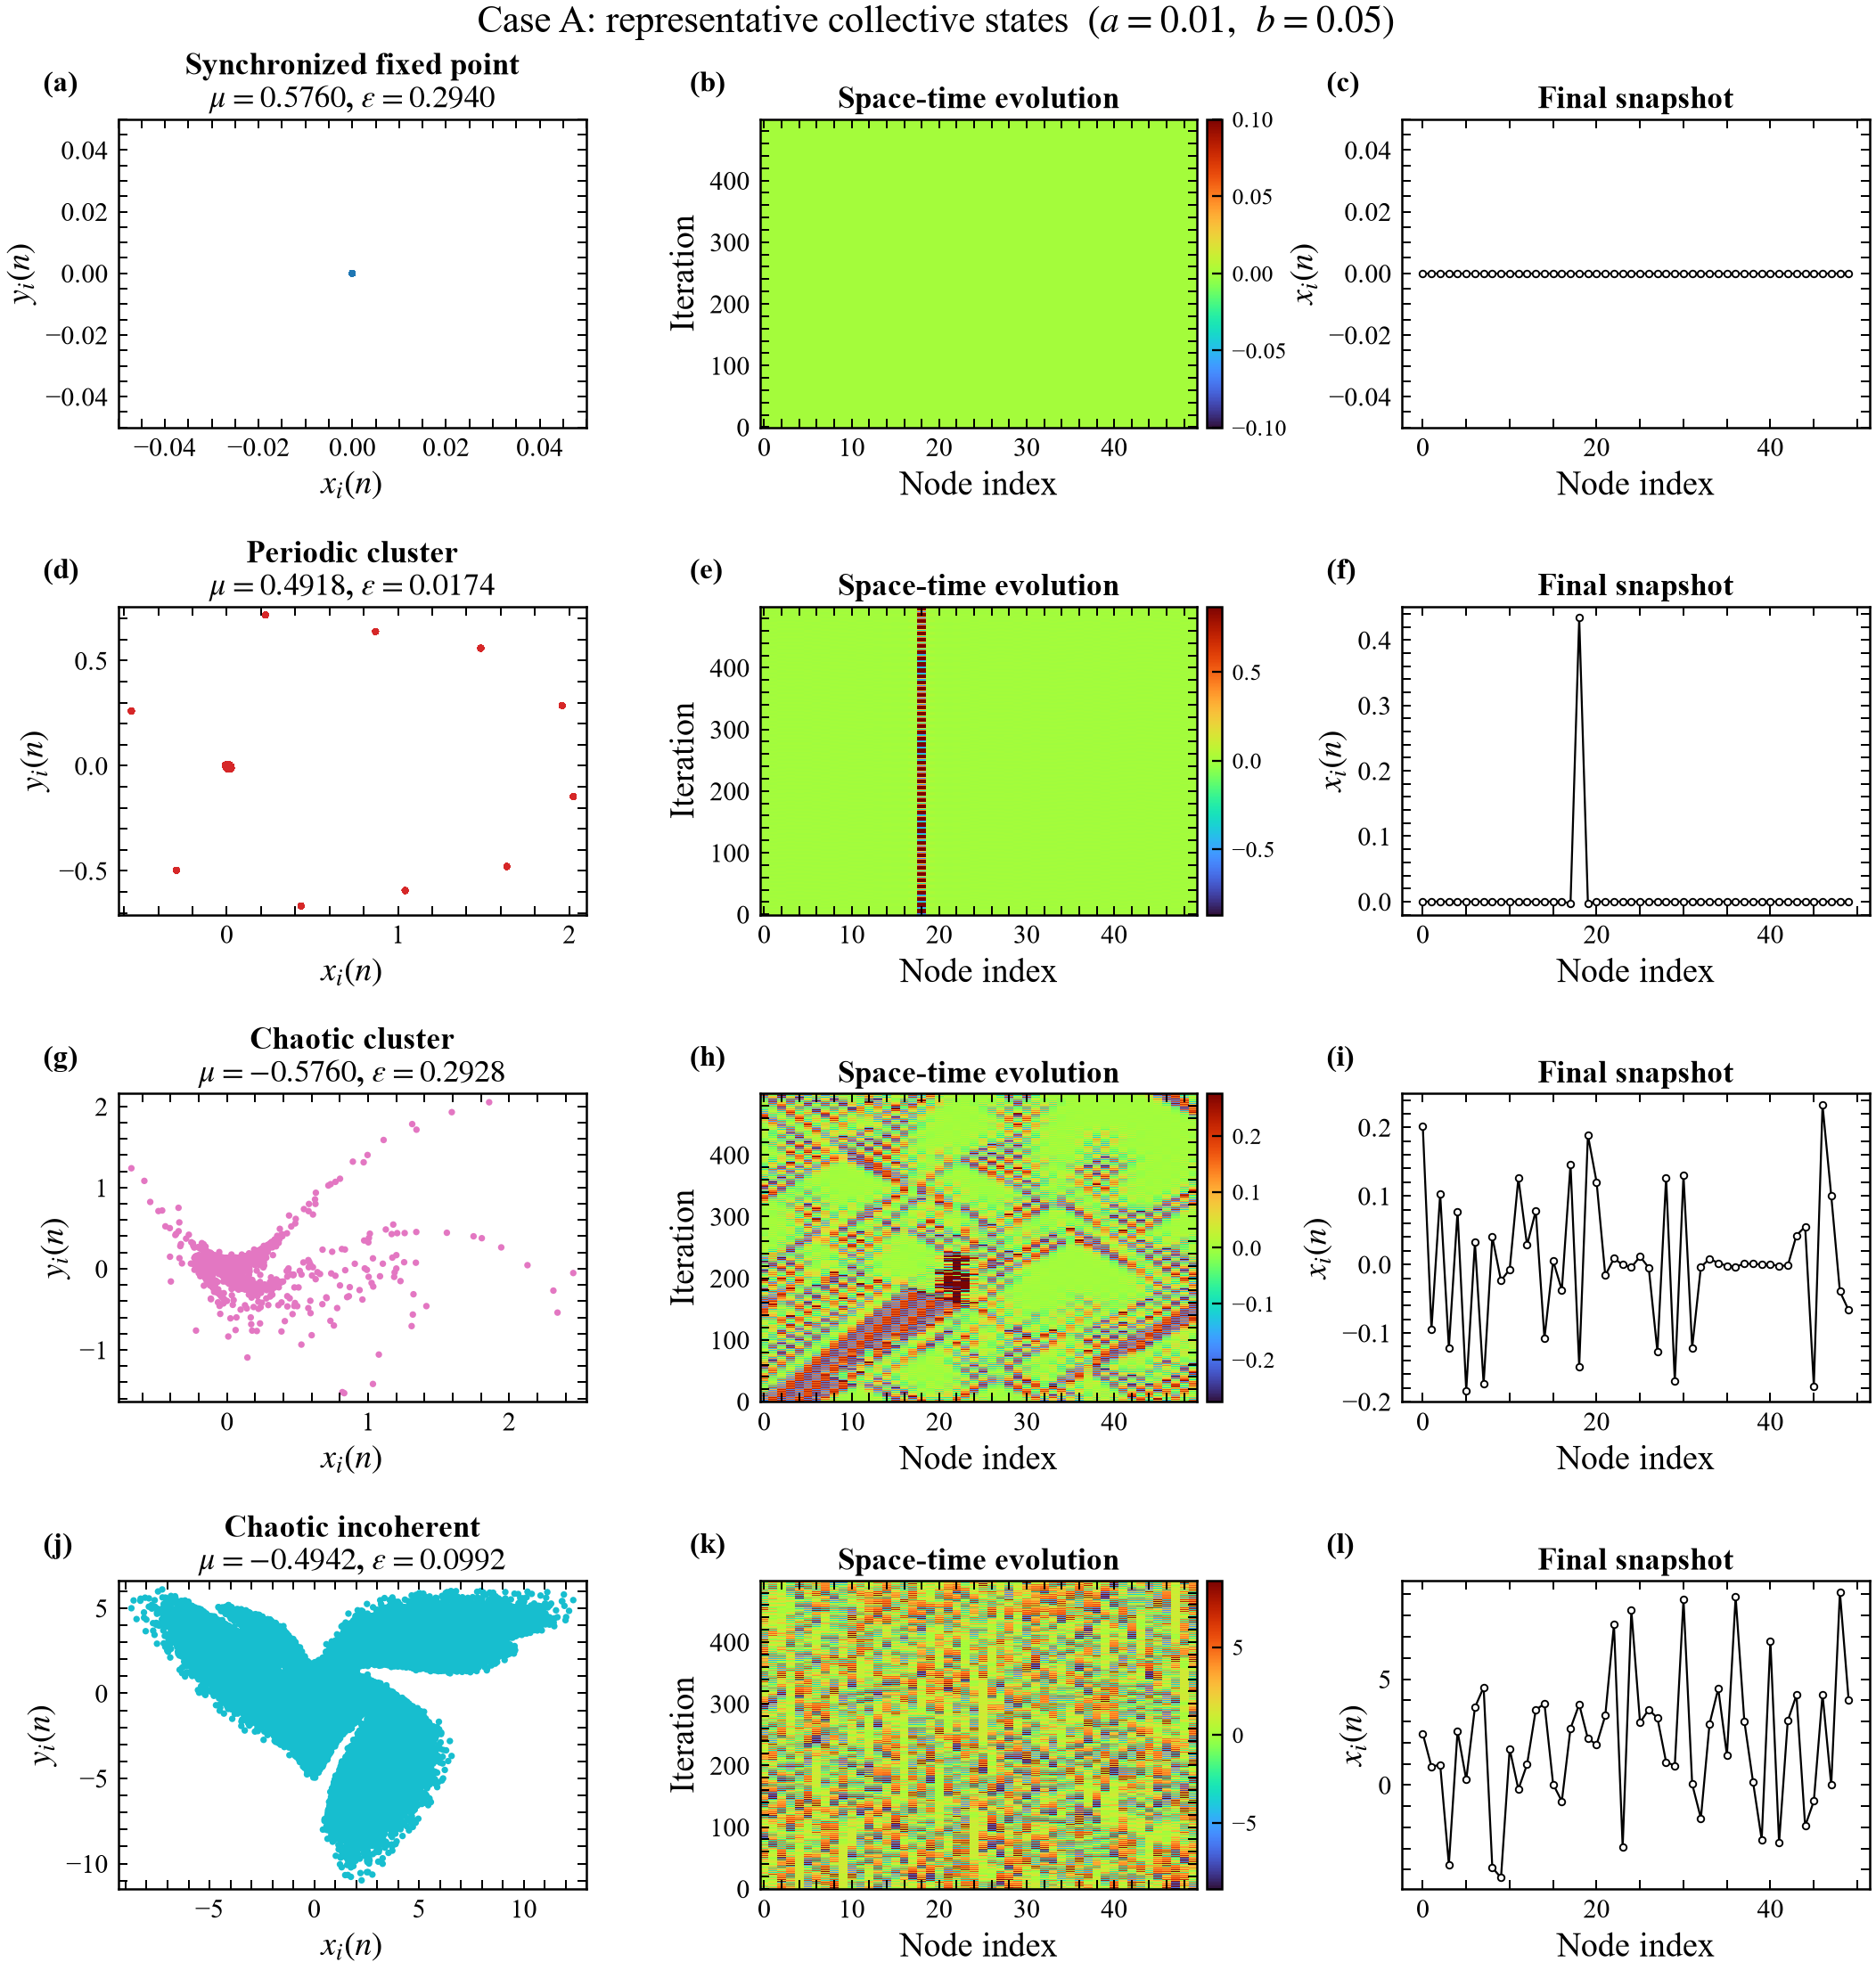

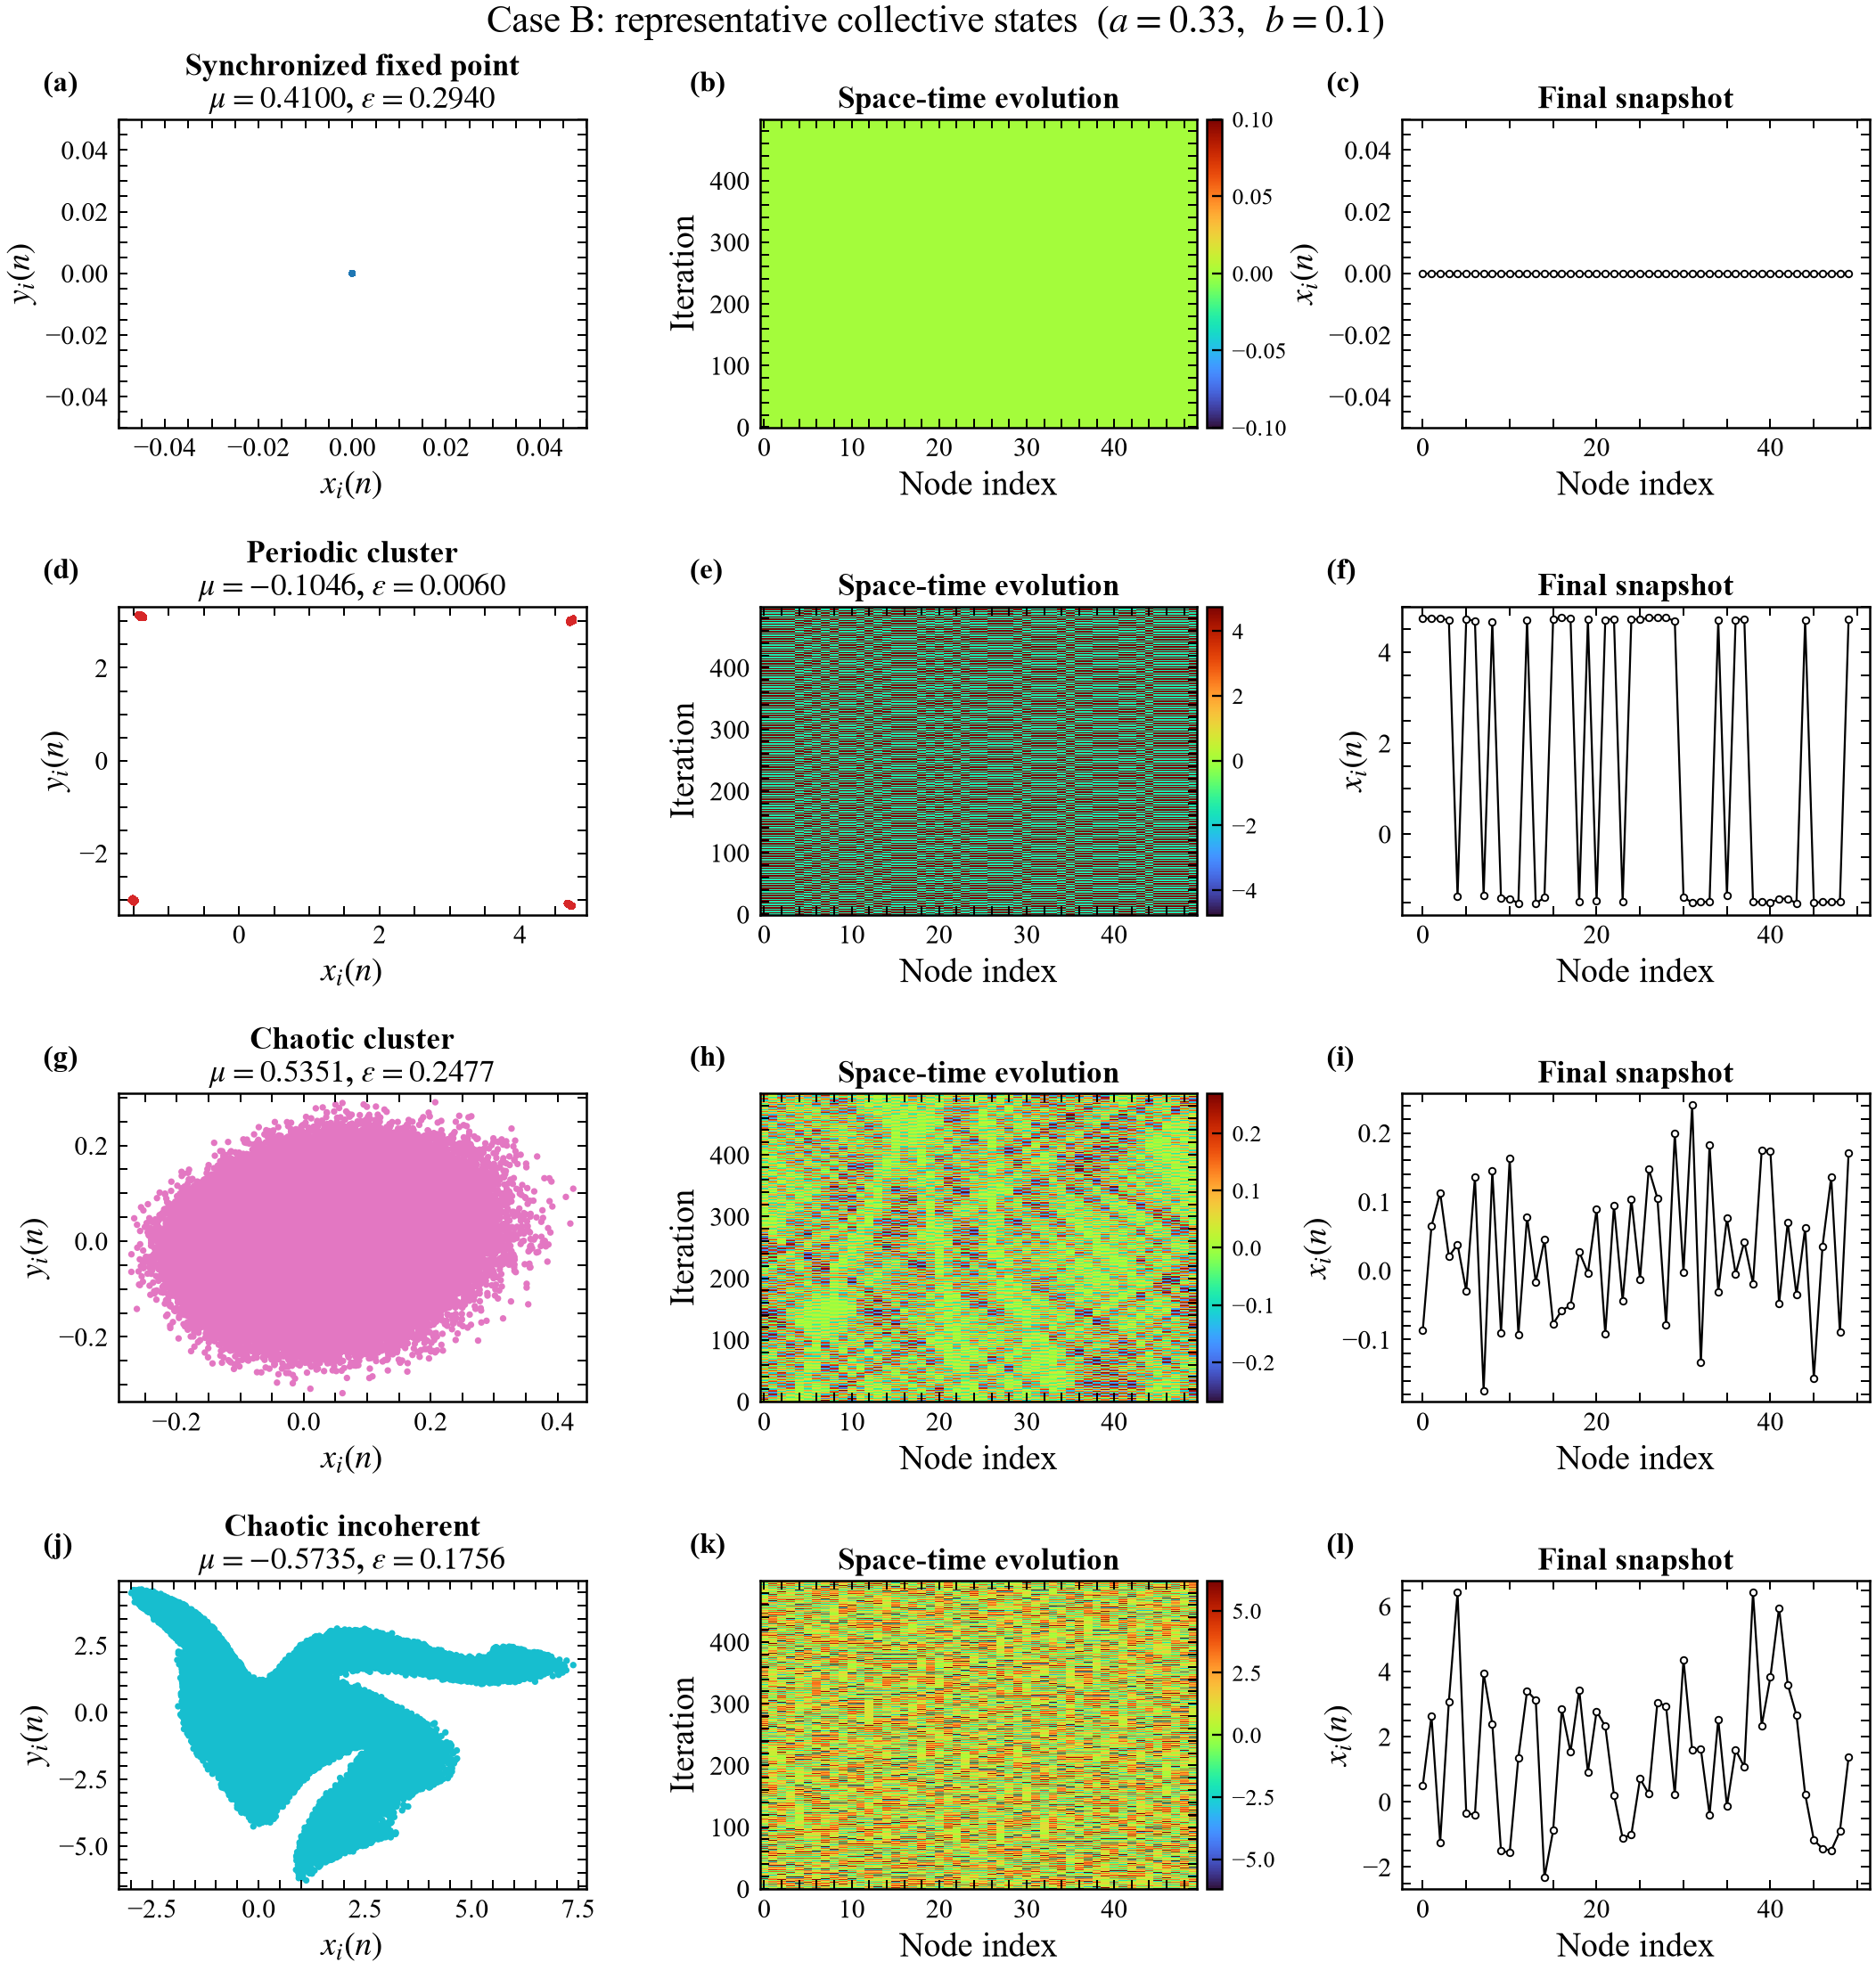


Final publication-figure validation:
case       state_requested            display_state        mu  epsilon     seed  lambda_max    sync_error  cluster_number  history_valid  classification_valid
   A Synchronized periodic Synchronized fixed point  0.575952 0.293988 20360935   -0.169087  0.000000e+00               1           True                  True
   A      Periodic cluster         Periodic cluster  0.491784 0.017435 20460955   -0.003817  2.992337e-02               2           True                  True
   A       Chaotic cluster          Chaotic cluster -0.575952 0.292786 20560915    0.132286  2.429486e-02               2           True                  True
   A            Incoherent       Chaotic incoherent -0.494188 0.099198 20660933    0.377471  1.074592e+01              41           True                  True
   B Synchronized periodic Synchronized fixed point  0.410020 0.293988 30760941   -0.031472 4.393034e-140               1           True                  True
   B    

In [29]:
# ============================================================
# PUBLICATION-READY REPRESENTATIVE NETWORK STATES
#
# Produces:
#   Figure 5: Case A representative collective states
#   Figure 6: Case B representative collective states
#
# Rows:
#   1. Synchronized fixed point
#   2. Periodic cluster
#   3. Chaotic cluster
#   4. Chaotic incoherent
#
# Columns:
#   1. Physical phase plane of all network nodes
#   2. Space-time evolution
#   3. Final network snapshot
#
# Required existing objects:
#   verification_results
#   CASES
#   RUN_DIRECTORY
#   F_v2
#   config
#
# The verification_results DataFrame must contain:
#   case
#   state_requested
#   observed_state
#   valid
#   mu
#   epsilon
#   seed
#   realization_id
#   lambda_max
#   sync_error_mean
#   cluster_number_median
# ============================================================

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ============================================================
# 1. OUTPUT DIRECTORY
# ============================================================

RUN_DIRECTORY = Path(
    RUN_DIRECTORY
)

REPRESENTATIVE_FIGURE_DIRECTORY = (
    RUN_DIRECTORY
    / "publication_representative_states_200x200"
)

REPRESENTATIVE_FIGURE_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# 2. NUMERICAL AND DISPLAY SETTINGS
# ============================================================

REPRESENTATIVE_NETWORK_SIZE = 50

REPRESENTATIVE_TRANSIENT = 5_000

REPRESENTATIVE_HISTORY_LENGTH = 2_500

REPRESENTATIVE_SPACE_TIME_LENGTH = 500

REPRESENTATIVE_PHASE_LENGTH = 1_500

REPRESENTATIVE_ESCAPE_BOUND = 1.0e8

SPACE_TIME_CMAP = "turbo"

SYNCHRONIZED_DISPLAY_LIMIT = 0.05

SYNCHRONIZED_COLOR_LIMIT = 0.10


REPRESENTATIVE_STATE_ORDER = [
    "Synchronized periodic",
    "Periodic cluster",
    "Chaotic cluster",
    "Incoherent",
]


DISPLAY_STATE_NAMES = {
    "Synchronized periodic": (
        "Synchronized fixed point"
    ),
    "Periodic cluster": (
        "Periodic cluster"
    ),
    "Chaotic cluster": (
        "Chaotic cluster"
    ),
    "Incoherent": (
        "Chaotic incoherent"
    ),
}


REPRESENTATIVE_STATE_COLORS = {
    "Synchronized periodic": "#1F77B4",
    "Periodic cluster": "#D62728",
    "Chaotic cluster": "#E377C2",
    "Incoherent": "#17BECF",
}

#REPRESENTATIVE_STATE_COLORS = {
 #   "Synchronized periodic": "#1F77B4",
 #   "Periodic cluster": "#D62728",
 #   "Chaotic cluster": "#D66DB8",
 #   "Incoherent": "#1FB5C4",
#}


# ============================================================
# 3. PUBLICATION STYLE
# ============================================================

plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": [
            "Times New Roman",
            "Times",
            "DejaVu Serif",
        ],
        "mathtext.fontset": "stix",
        "font.size": 16,
        "axes.labelsize": 15,
        "axes.titlesize": 14,
        "axes.linewidth": 1.0,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.top": True,
        "ytick.right": True,
        "xtick.major.size": 4.5,
        "ytick.major.size": 4.5,
        "xtick.minor.size": 2.5,
        "ytick.minor.size": 2.5,
        "xtick.major.width": 0.9,
        "ytick.major.width": 0.9,
        "figure.dpi": 180,
        "savefig.dpi": 600,
        "savefig.bbox": "tight",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)


# ============================================================
# 4. VALIDATE AND FREEZE THE 200 x 200 VERIFICATION DATA
# ============================================================

REQUIRED_VERIFICATION_COLUMNS = {
    "case",
    "state_requested",
    "observed_state",
    "valid",
    "mu",
    "epsilon",
    "seed",
    "realization_id",
    "lambda_max",
    "sync_error_mean",
    "cluster_number_median",
}


missing_columns = (
    REQUIRED_VERIFICATION_COLUMNS
    - set(
        verification_results.columns
    )
)


if missing_columns:
    raise KeyError(
        "verification_results is missing: "
        + ", ".join(
            sorted(
                missing_columns
            )
        )
    )


verification_results_200 = (
    verification_results.copy()
)


for column_name in [
    "case",
    "state_requested",
    "observed_state",
]:
    verification_results_200[
        column_name
    ] = (
        verification_results_200[
            column_name
        ]
        .astype(str)
        .str.strip()
    )


if (
    verification_results_200[
        "valid"
    ].dtype
    == object
):
    verification_results_200[
        "valid"
    ] = (
        verification_results_200[
            "valid"
        ]
        .astype(str)
        .str.strip()
        .str.lower()
        .map(
            {
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            }
        )
    )


verification_results_200[
    "valid"
] = (
    verification_results_200[
        "valid"
    ]
    .fillna(False)
    .astype(bool)
)


for column_name in [
    "mu",
    "epsilon",
    "seed",
    "realization_id",
    "lambda_max",
    "sync_error_mean",
    "cluster_number_median",
]:
    verification_results_200[
        column_name
    ] = pd.to_numeric(
        verification_results_200[
            column_name
        ],
        errors="raise",
    )


print(
    "Requested and observed state counts:"
)

print(
    verification_results_200.groupby(
        [
            "case",
            "state_requested",
            "observed_state",
        ]
    )
    .size()
    .rename(
        "count"
    )
    .reset_index()
    .to_string(
        index=False
    )
)


# ============================================================
# 5. VERSION 2 NETWORK UPDATE
# ============================================================

def coupled_step_single_version2(
    X,
    Y,
    mu,
    a,
    b,
    epsilon,
):
    """
    Advance one corrected coupled Gumowski-Mira ring.
    """

    local_update = (
        a
        * Y
        * (
            1.0
            - b * Y**2
        )
        + Y
        + F_v2(
            X,
            mu,
        )
    )

    left_neighbors = np.roll(
        X,
        shift=1,
    )

    right_neighbors = np.roll(
        X,
        shift=-1,
    )

    X_next = (
        (1.0 - epsilon)
        * local_update
        + 0.5
        * epsilon
        * (
            left_neighbors
            + right_neighbors
        )
    )

    Y_next = (
        -X
        + F_v2(
            X_next,
            mu,
        )
    )

    return (
        X_next,
        Y_next,
    )


def representative_state_is_valid(
    X,
    Y,
    escape_bound=REPRESENTATIVE_ESCAPE_BOUND,
):
    """
    Check whether all network variables are finite and bounded.
    """

    return bool(
        np.all(
            np.isfinite(
                X
            )
        )
        and np.all(
            np.isfinite(
                Y
            )
        )
        and np.max(
            np.abs(
                X
            )
        )
        <= escape_bound
        and np.max(
            np.abs(
                Y
            )
        )
        <= escape_bound
    )


# ============================================================
# 6. SCIENTIFIC-NOTATION FORMATTER
# ============================================================

def scientific_latex(
    value,
    precision=2,
    zero_tolerance=1.0e-300,
):
    """
    Convert a numerical value to LaTeX scientific notation.
    """

    value = float(
        value
    )

    if not np.isfinite(
        value
    ):
        return r"\mathrm{undefined}"

    if abs(
        value
    ) <= zero_tolerance:
        return "0"

    formatted_value = format(
        value,
        "."
        + str(
            precision
        )
        + "e",
    )

    coefficient_text, exponent_text = (
        formatted_value.split(
            "e"
        )
    )

    coefficient = float(
        coefficient_text
    )

    exponent = int(
        exponent_text
    )

    return (
        format(
            coefficient,
            "."
            + str(
                precision
            )
            + "f",
        )
        + r"\times10^{"
        + str(
            exponent
        )
        + "}"
    )


# ============================================================
# 7. SELECT TYPICAL VERIFIED REALIZATIONS
# ============================================================

def select_verified_realization(
    verification_data,
    case_name,
    requested_state,
):
    """
    Select a valid realization that retained the requested
    classification.

    For clustered states, prefer a clear two-cluster realization
    when one is available. Among equally preferred realizations,
    select the realization whose largest exponent is closest to
    the median of the eligible subset.
    """

    subset = verification_data.loc[
        (
            verification_data[
                "case"
            ]
            == case_name
        )
        &
        (
            verification_data[
                "state_requested"
            ]
            == requested_state
        )
        &
        (
            verification_data[
                "observed_state"
            ]
            == requested_state
        )
        &
        (
            verification_data[
                "valid"
            ]
        )
    ].copy()

    if subset.empty:
        return None

    subset[
        "rounded_cluster_number"
    ] = np.rint(
        subset[
            "cluster_number_median"
        ]
    ).astype(int)

    if requested_state in [
        "Periodic cluster",
        "Chaotic cluster",
    ]:
        subset[
            "cluster_preference"
        ] = np.abs(
            subset[
                "rounded_cluster_number"
            ]
            - 2
        )

        minimum_cluster_preference = (
            subset[
                "cluster_preference"
            ].min()
        )

        subset = subset.loc[
            subset[
                "cluster_preference"
            ]
            == minimum_cluster_preference
        ].copy()

    median_lambda = float(
        subset[
            "lambda_max"
        ].median()
    )

    subset[
        "distance_from_median_lambda"
    ] = np.abs(
        subset[
            "lambda_max"
        ]
        - median_lambda
    )

    selected = (
        subset.sort_values(
            by=[
                "distance_from_median_lambda",
                "sync_error_mean",
                "realization_id",
            ],
            ascending=[
                True,
                True,
                True,
            ],
        )
        .iloc[0]
    )

    return {
        "case": case_name,
        "state_requested": requested_state,
        "display_state": (
            DISPLAY_STATE_NAMES[
                requested_state
            ]
        ),
        "mu": float(
            selected[
                "mu"
            ]
        ),
        "epsilon": float(
            selected[
                "epsilon"
            ]
        ),
        "seed": int(
            selected[
                "seed"
            ]
        ),
        "realization_id": int(
            selected[
                "realization_id"
            ]
        ),
        "lambda_max": float(
            selected[
                "lambda_max"
            ]
        ),
        "sync_error": float(
            selected[
                "sync_error_mean"
            ]
        ),
        "cluster_number": int(
            np.rint(
                selected[
                    "cluster_number_median"
                ]
            )
        ),
    }


VERIFIED_REALIZATIONS_FOR_FIGURES = {
    "A": {},
    "B": {},
}


selected_realization_rows = []


for case_name in (
    "A",
    "B",
):
    for requested_state in (
        REPRESENTATIVE_STATE_ORDER
    ):
        selected_realization = (
            select_verified_realization(
                verification_data=(
                    verification_results_200
                ),
                case_name=case_name,
                requested_state=(
                    requested_state
                ),
            )
        )

        VERIFIED_REALIZATIONS_FOR_FIGURES[
            case_name
        ][requested_state] = (
            selected_realization
        )

        if selected_realization is None:
            selected_realization_rows.append(
                {
                    "case": case_name,
                    "state_requested": (
                        requested_state
                    ),
                    "display_state": (
                        DISPLAY_STATE_NAMES[
                            requested_state
                        ]
                    ),
                    "selection_successful": False,
                    "mu": np.nan,
                    "epsilon": np.nan,
                    "seed": np.nan,
                    "realization_id": np.nan,
                    "lambda_max": np.nan,
                    "sync_error": np.nan,
                    "cluster_number": np.nan,
                }
            )

        else:
            selected_realization_rows.append(
                {
                    **selected_realization,
                    "selection_successful": True,
                }
            )


selected_realizations_table = (
    pd.DataFrame(
        selected_realization_rows
    )
)


print()
print(
    "Selected representative realizations:"
)

print(
    selected_realizations_table[
        [
            "case",
            "state_requested",
            "display_state",
            "mu",
            "epsilon",
            "seed",
            "lambda_max",
            "sync_error",
            "cluster_number",
            "selection_successful",
        ]
    ].to_string(
        index=False
    )
)


selected_realizations_table.to_csv(
    REPRESENTATIVE_FIGURE_DIRECTORY
    / "publication_representative_realizations.csv",
    index=False,
)


# ============================================================
# 8. HARD PRE-FIGURE AVAILABILITY CHECK
# ============================================================

expected_requested_states = set(
    REPRESENTATIVE_STATE_ORDER
)


for case_name in (
    "A",
    "B",
):
    available_states = {
        state_name
        for state_name, selected in (
            VERIFIED_REALIZATIONS_FOR_FIGURES[
                case_name
            ].items()
        )
        if selected is not None
    }

    missing_states = (
        expected_requested_states
        - available_states
    )

    if missing_states:
        raise RuntimeError(
            "Missing representative states for Case "
            + case_name
            + ": "
            + ", ".join(
                sorted(
                    missing_states
                )
            )
        )


print()
print(
    "All eight representative states are available."
)


# ============================================================
# 9. VALIDATE THE SELECTED CLASSIFICATIONS BEFORE SIMULATION
# ============================================================

def classification_criteria_are_satisfied(
    requested_state,
    lambda_max,
    synchronization_error,
    cluster_number,
):
    """
    Validate one selected representative against the numerical
    collective-state criteria.
    """

    lambda_max = float(
        lambda_max
    )

    synchronization_error = float(
        synchronization_error
    )

    cluster_number = int(
        cluster_number
    )

    if requested_state == "Synchronized periodic":
        criteria = [
            lambda_max
            < -config.lambda_tolerance,

            synchronization_error
            <= config.synchronization_tolerance,

            cluster_number == 1,
        ]

    elif requested_state == "Periodic cluster":
        criteria = [
            lambda_max
            < -config.lambda_tolerance,

            synchronization_error
            > config.synchronization_tolerance,

            cluster_number >= 2,

            cluster_number
            <= config.fragmentation_threshold,
        ]

    elif requested_state == "Chaotic cluster":
        criteria = [
            lambda_max
            > config.lambda_tolerance,

            synchronization_error
            > config.synchronization_tolerance,

            cluster_number >= 2,

            cluster_number
            <= config.fragmentation_threshold,
        ]

    elif requested_state == "Incoherent":
        criteria = [
            lambda_max
            > config.lambda_tolerance,

            synchronization_error
            > config.synchronization_tolerance,

            cluster_number
            > config.fragmentation_threshold,
        ]

    else:
        criteria = [
            False
        ]

    return bool(
        all(
            criteria
        )
    )


prefigure_validation_rows = []


for _, row in (
    selected_realizations_table.iterrows()
):
    selection_successful = bool(
        row[
            "selection_successful"
        ]
    )

    if selection_successful:
        classification_valid = (
            classification_criteria_are_satisfied(
                requested_state=row[
                    "state_requested"
                ],
                lambda_max=row[
                    "lambda_max"
                ],
                synchronization_error=row[
                    "sync_error"
                ],
                cluster_number=row[
                    "cluster_number"
                ],
            )
        )

    else:
        classification_valid = False

    prefigure_validation_rows.append(
        {
            **row.to_dict(),
            "classification_valid": (
                classification_valid
            ),
        }
    )


prefigure_validation = pd.DataFrame(
    prefigure_validation_rows
)


print()
print(
    "Pre-figure classification validation:"
)

print(
    prefigure_validation[
        [
            "case",
            "state_requested",
            "mu",
            "epsilon",
            "lambda_max",
            "sync_error",
            "cluster_number",
            "classification_valid",
        ]
    ].to_string(
        index=False
    )
)


prefigure_validation.to_csv(
    REPRESENTATIVE_FIGURE_DIRECTORY
    / "prefigure_classification_validation.csv",
    index=False,
)


if not prefigure_validation[
    "classification_valid"
].all():
    raise RuntimeError(
        "At least one selected representative does not satisfy "
        "the required numerical classification."
    )


# ============================================================
# 10. REPRODUCE A VERIFIED REFERENCE TRAJECTORY
# ============================================================

def simulate_verified_network_history(
    case_name,
    mu,
    epsilon,
    seed,
    network_size=REPRESENTATIVE_NETWORK_SIZE,
    transient=REPRESENTATIVE_TRANSIENT,
    history_length=REPRESENTATIVE_HISTORY_LENGTH,
):
    """
    Reproduce the reference trajectory associated with a
    verified network initial condition.
    """

    parameters = CASES[
        case_name
    ]

    a = float(
        parameters[
            "a"
        ]
    )

    b = float(
        parameters[
            "b"
        ]
    )

    local_rng = np.random.default_rng(
        int(
            seed
        )
    )

    X = local_rng.uniform(
        -1.0,
        1.0,
        network_size,
    )

    Y = local_rng.uniform(
        -1.0,
        1.0,
        network_size,
    )

    # Consume the perturbation vector generated by the
    # original verification workflow.
    _ = local_rng.normal(
        size=2 * network_size
    )

    for _ in range(
        transient
    ):
        with np.errstate(
            over="ignore",
            invalid="ignore",
            divide="ignore",
        ):
            X, Y = (
                coupled_step_single_version2(
                    X,
                    Y,
                    mu,
                    a,
                    b,
                    epsilon,
                )
            )

        if not representative_state_is_valid(
            X,
            Y,
        ):
            return (
                None,
                None,
                False,
            )

    X_history = np.empty(
        (
            history_length,
            network_size,
        ),
        dtype=float,
    )

    Y_history = np.empty(
        (
            history_length,
            network_size,
        ),
        dtype=float,
    )

    for time_index in range(
        history_length
    ):
        with np.errstate(
            over="ignore",
            invalid="ignore",
            divide="ignore",
        ):
            X, Y = (
                coupled_step_single_version2(
                    X,
                    Y,
                    mu,
                    a,
                    b,
                    epsilon,
                )
            )

        if not representative_state_is_valid(
            X,
            Y,
        ):
            return (
                None,
                None,
                False,
            )

        X_history[
            time_index
        ] = X

        Y_history[
            time_index
        ] = Y

    return (
        X_history,
        Y_history,
        True,
    )


# ============================================================
# 11. AXIS AND COLOR-LIMIT HELPERS
# ============================================================

def padded_limits(
    values,
    minimum_half_width=0.05,
    padding_fraction=0.08,
):
    """
    Calculate stable plotting limits for one-dimensional data.
    """

    values = np.asarray(
        values,
        dtype=float,
    )

    finite_values = values[
        np.isfinite(
            values
        )
    ]

    if finite_values.size == 0:
        return (
            -minimum_half_width,
            minimum_half_width,
        )

    minimum = float(
        np.min(
            finite_values
        )
    )

    maximum = float(
        np.max(
            finite_values
        )
    )

    center = (
        minimum
        + maximum
    ) / 2.0

    half_range = (
        maximum
        - minimum
    ) / 2.0

    half_width = max(
        minimum_half_width,
        half_range
        * (
            1.0
            + padding_fraction
        ),
    )

    if max(
        abs(
            minimum
        ),
        abs(
            maximum
        ),
    ) < minimum_half_width:
        center = 0.0

    return (
        center
        - half_width,
        center
        + half_width,
    )


def padded_phase_limits(
    x_values,
    y_values,
    minimum_half_width=0.05,
    padding_fraction=0.06,
):
    """
    Return padded limits for a two-dimensional phase plane.
    """

    x_limits = padded_limits(
        x_values,
        minimum_half_width=(
            minimum_half_width
        ),
        padding_fraction=(
            padding_fraction
        ),
    )

    y_limits = padded_limits(
        y_values,
        minimum_half_width=(
            minimum_half_width
        ),
        padding_fraction=(
            padding_fraction
        ),
    )

    return (
        x_limits,
        y_limits,
    )


def robust_color_limits(
    values,
    upper_percentile=99.0,
    minimum_half_width=1.0e-3,
):
    """
    Calculate symmetric, zero-centred limits for a signed state-variable panel.
    """

    values = np.asarray(
        values,
        dtype=float,
    )

    finite_values = values[
        np.isfinite(
            values
        )
    ]

    if finite_values.size == 0:
        return (
            -1.0,
            1.0,
        )

    # The state variable is signed, so centre a diverging map at zero.
    # Percentile clipping reduces the effect of rare extreme excursions.
    color_limit = float(
        np.percentile(
            np.abs(finite_values),
            max(upper_percentile, 50.0),
        )
    )
    color_limit = max(color_limit, minimum_half_width)

    return (
        -color_limit,
        color_limit,
    )


# ============================================================
# 12. PUBLICATION FIGURE FUNCTION
# ============================================================

def plot_publication_representative_states(
    case_name,
    selected_realizations,
):
    """
    Create a publication-ready representative-state figure.

    Rows
    ----
    1. Synchronized fixed point
    2. Periodic cluster
    3. Chaotic cluster
    4. Chaotic incoherent

    Columns
    -------
    1. Physical phase plane
    2. Space-time evolution
    3. Final network snapshot
    """

    number_of_rows = len(
        REPRESENTATIVE_STATE_ORDER
    )

    figure, axes = plt.subplots(
        number_of_rows,
        3,
        figsize=(
            12.0,
            12.4,
        ),
        constrained_layout=False,
    )

    panel_letters = (
        "abcdefghijkl"
    )

    figure_records = []

    for row, requested_state in enumerate(
        REPRESENTATIVE_STATE_ORDER
    ):
        selected = selected_realizations.get(
            requested_state
        )

        display_state = (
            DISPLAY_STATE_NAMES[
                requested_state
            ]
        )

        if selected is None:
            for column in range(
                3
            ):
                axis = axes[
                    row,
                    column,
                ]

                axis.text(
                    0.5,
                    0.5,
                    "No verified realization",
                    transform=axis.transAxes,
                    ha="center",
                    va="center",
                    fontsize=11,
                )

                axis.set_xticks(
                    []
                )

                axis.set_yticks(
                    []
                )

            continue

        (
            X_history,
            Y_history,
            history_valid,
        ) = simulate_verified_network_history(
            case_name=case_name,
            mu=selected[
                "mu"
            ],
            epsilon=selected[
                "epsilon"
            ],
            seed=selected[
                "seed"
            ],
        )

        if not history_valid:
            for column in range(
                3
            ):
                axis = axes[
                    row,
                    column,
                ]

                axis.text(
                    0.5,
                    0.5,
                    "Trajectory invalid",
                    transform=axis.transAxes,
                    ha="center",
                    va="center",
                    fontsize=17,
                )

                axis.set_xticks(
                    []
                )

                axis.set_yticks(
                    []
                )

            continue

        state_color = (
            REPRESENTATIVE_STATE_COLORS[
                requested_state
            ]
        )

        displayed_history = (
            X_history[
                -REPRESENTATIVE_SPACE_TIME_LENGTH:
            ]
        )

        phase_start = max(
            0,
            len(
                X_history
            )
            - REPRESENTATIVE_PHASE_LENGTH,
        )

        phase_x = (
            X_history[
                phase_start:
            ]
            .reshape(
                -1
            )
        )

        phase_y = (
            Y_history[
                phase_start:
            ]
            .reshape(
                -1
            )
        )

        final_snapshot = (
            X_history[
                -1
            ]
        )

        lambda_text = scientific_latex(
            selected[
                "lambda_max"
            ],
            precision=2,
        )

        error_text = scientific_latex(
            selected[
                "sync_error"
            ],
            precision=1,
        )

        # ----------------------------------------------------
        # Column 1: physical phase plane
        # ----------------------------------------------------

        phase_axis = axes[
            row,
            0,
        ]

        phase_axis.scatter(
            phase_x,
            phase_y,
            s=8.6,
            color=state_color,
            alpha=1.0,
            linewidths=0,
            edgecolors="none",
            rasterized=True,
        )

        phase_axis.set_xlabel(
            r"$x_i(n)$"
        )

        phase_axis.set_ylabel(
            r"$y_i(n)$"
        )

        phase_axis.set_title(
            (
                display_state
                + "\n"
                + r"$\mu="
                + format(
                    selected[
                        "mu"
                    ],
                    ".4f",
                )
                + r"$, "
                + r"$\epsilon="
                + format(
                    selected[
                        "epsilon"
                    ],
                    ".4f",
                )
                + r"$"
            ),
            pad=5,
        )

        if requested_state == "Synchronized periodic":
            phase_axis.set_xlim(
                -SYNCHRONIZED_DISPLAY_LIMIT,
                SYNCHRONIZED_DISPLAY_LIMIT,
            )

            phase_axis.set_ylim(
                -SYNCHRONIZED_DISPLAY_LIMIT,
                SYNCHRONIZED_DISPLAY_LIMIT,
            )

        else:
            (
                phase_x_limits,
                phase_y_limits,
            ) = padded_phase_limits(
                phase_x,
                phase_y,
                minimum_half_width=0.05,
                padding_fraction=0.06,
            )

            phase_axis.set_xlim(
                phase_x_limits
            )

            phase_axis.set_ylim(
                phase_y_limits
            )

        # ----------------------------------------------------
        # Column 2: space-time evolution
        # ----------------------------------------------------

        space_time_axis = axes[
            row,
            1,
        ]

        if requested_state == "Synchronized periodic":
            color_minimum = (
                -SYNCHRONIZED_COLOR_LIMIT
            )

            color_maximum = (
                SYNCHRONIZED_COLOR_LIMIT
            )

        else:
            (
                color_minimum,
                color_maximum,
            ) = robust_color_limits(
                displayed_history
            )

        space_time_image = (
            space_time_axis.imshow(
                displayed_history,
                aspect="auto",
                origin="lower",
                cmap=SPACE_TIME_CMAP,
                interpolation="nearest",
                rasterized=True,
                vmin=color_minimum,
                vmax=color_maximum,
            )
        )

        space_time_axis.set_xlabel(
            "Node index"
        )

        space_time_axis.set_ylabel(
            "Iteration"
        )

        space_time_axis.set_title(
            "Space-time evolution",
            pad=5,
        )

        colorbar = figure.colorbar(
            space_time_image,
            ax=space_time_axis,
            pad=0.02,
            fraction=0.046,
        )

        colorbar.ax.tick_params(
            labelsize=10.5
        )

        # ----------------------------------------------------
        # Column 3: final network snapshot
        # ----------------------------------------------------

        snapshot_axis = axes[
            row,
            2,
        ]

        node_indices = np.arange(
            REPRESENTATIVE_NETWORK_SIZE
        )

        snapshot_axis.plot(
            node_indices,
            final_snapshot,
            "o-",
            color="black",
            linewidth=0.9,
            markersize=3.0,
            markerfacecolor="white",
            markeredgewidth=0.75,
        )

        snapshot_axis.set_xlabel(
            "Node index"
        )

        snapshot_axis.set_ylabel(
            r"$x_i(n)$"
        )

        snapshot_axis.set_title(
            "Final snapshot",
            pad=5,
        )

        if requested_state == "Synchronized periodic":
            snapshot_axis.set_ylim(
                -SYNCHRONIZED_DISPLAY_LIMIT,
                SYNCHRONIZED_DISPLAY_LIMIT,
            )

        else:
            snapshot_axis.set_ylim(
                padded_limits(
                    final_snapshot,
                    minimum_half_width=0.05,
                    padding_fraction=0.08,
                )
            )

        # ----------------------------------------------------
        # Common panel formatting
        # ----------------------------------------------------

        for column in range(
            3
        ):
            axis = axes[
                row,
                column,
            ]

            axis.tick_params(
                which="both",
                direction="in",
                top=True,
                right=True,
                length=4,
                width=0.8,
            )

            axis.minorticks_on()

            panel_index = (
                row * 3
                + column
            )

            axis.text(
                -0.16,
                1.07,
                (
                    "("
                    + panel_letters[
                        panel_index
                    ]
                    + ")"
                ),
                transform=axis.transAxes,
                fontsize=13,
                fontweight="bold",
                ha="left",
                va="bottom",
            )

        figure_records.append(
            {
                **selected,
                "display_state": (
                    display_state
                ),
                "lambda_text": (
                    lambda_text
                ),
                "sync_error_text": (
                    error_text
                ),
                "history_valid": True,
                "phase_points_plotted": int(
                    phase_x.size
                ),
                "space_time_iterations": (
                    REPRESENTATIVE_SPACE_TIME_LENGTH
                ),
            }
        )

    parameters = CASES[
        case_name
    ]

    # Keep the publication title concise.
    figure.suptitle(
        (
            "Case "
            + case_name
            + ": representative collective states  "
            + r"$("
            + "a="
            + str(
                parameters[
                    "a"
                ]
            )
            + r",\ b="
            + str(
                parameters[
                    "b"
                ]
            )
            + r")$"
        ),
        fontsize=17,
        y=0.992,
    )

    figure.subplots_adjust(
        left=0.075,
        right=0.985,
        bottom=0.045,
        top=0.935,
        wspace=0.37,
        hspace=0.58,
    )

    filename_stem = (
        "Figure_representative_states_"
        + "Case"
        + case_name
        + "_200x200_publication"
    )

    figure.savefig(
        REPRESENTATIVE_FIGURE_DIRECTORY
        / (
            filename_stem
            + ".pdf"
        ),
        bbox_inches="tight",
    )

    figure.savefig(
        REPRESENTATIVE_FIGURE_DIRECTORY
        / (
            filename_stem
            + ".png"
        ),
        dpi=600,
        bbox_inches="tight",
    )

    figure.savefig(
        REPRESENTATIVE_FIGURE_DIRECTORY
        / (
            filename_stem
            + ".eps"
        ),
        bbox_inches="tight",
    )

    figure_details = pd.DataFrame(
        figure_records
    )

    figure_details.to_csv(
        REPRESENTATIVE_FIGURE_DIRECTORY
        / (
            "Case"
            + case_name
            + "_publication_figure_details.csv"
        ),
        index=False,
    )

    plt.show()
    plt.close()

    return (
        figure,
        axes,
        figure_details,
    )


# ============================================================
# 13. GENERATE FIGURES 5 AND 6
# ============================================================

(
    figure_case_a,
    axes_case_a,
    figure_case_a_details,
) = plot_publication_representative_states(
    case_name="A",
    selected_realizations=(
        VERIFIED_REALIZATIONS_FOR_FIGURES[
            "A"
        ]
    ),
)


(
    figure_case_b,
    axes_case_b,
    figure_case_b_details,
) = plot_publication_representative_states(
    case_name="B",
    selected_realizations=(
        VERIFIED_REALIZATIONS_FOR_FIGURES[
            "B"
        ]
    ),
)


# ============================================================
# 14. VALIDATE THE DISPLAYED CLASSIFICATIONS
# ============================================================

def validate_publication_figure_details(
    figure_details,
    case_name,
):
    """
    Confirm that every displayed state satisfies the expected
    numerical classification criteria.
    """

    validation_rows = []

    for _, row in (
        figure_details.iterrows()
    ):
        requested_state = str(
            row[
                "state_requested"
            ]
        )

        lambda_max = float(
            row[
                "lambda_max"
            ]
        )

        synchronization_error_value = float(
            row[
                "sync_error"
            ]
        )

        cluster_number = int(
            row[
                "cluster_number"
            ]
        )

        classification_valid = (
            classification_criteria_are_satisfied(
                requested_state=(
                    requested_state
                ),
                lambda_max=lambda_max,
                synchronization_error=(
                    synchronization_error_value
                ),
                cluster_number=(
                    cluster_number
                ),
            )
        )

        validation_rows.append(
            {
                "case": case_name,
                "state_requested": (
                    requested_state
                ),
                "display_state": row[
                    "display_state"
                ],
                "mu": float(
                    row[
                        "mu"
                    ]
                ),
                "epsilon": float(
                    row[
                        "epsilon"
                    ]
                ),
                "seed": int(
                    row[
                        "seed"
                    ]
                ),
                "lambda_max": (
                    lambda_max
                ),
                "sync_error": (
                    synchronization_error_value
                ),
                "cluster_number": (
                    cluster_number
                ),
                "history_valid": bool(
                    row[
                        "history_valid"
                    ]
                ),
                "classification_valid": (
                    classification_valid
                ),
            }
        )

    return pd.DataFrame(
        validation_rows
    )


case_a_figure_validation = (
    validate_publication_figure_details(
        figure_details=(
            figure_case_a_details
        ),
        case_name="A",
    )
)


case_b_figure_validation = (
    validate_publication_figure_details(
        figure_details=(
            figure_case_b_details
        ),
        case_name="B",
    )
)


publication_figure_validation = (
    pd.concat(
        [
            case_a_figure_validation,
            case_b_figure_validation,
        ],
        ignore_index=True,
    )
)


print()
print(
    "Final publication-figure validation:"
)

print(
    publication_figure_validation.to_string(
        index=False
    )
)


publication_figure_validation.to_csv(
    REPRESENTATIVE_FIGURE_DIRECTORY
    / (
        "publication_representative_"
        "figure_validation.csv"
    ),
    index=False,
)


if not publication_figure_validation[
    "classification_valid"
].all():
    print()
    print(
        "Representatives failing classification validation:"
    )

    print(
        publication_figure_validation.loc[
            ~publication_figure_validation[
                "classification_valid"
            ]
        ].to_string(
            index=False
        )
    )

    raise RuntimeError(
        "At least one displayed state does not satisfy "
        "the publication classification criteria."
    )


print()
print(
    "All eight displayed representative states satisfy "
    "the publication classification criteria."
)


# ============================================================
# 15. CREATE LATEX-FORMATTED CAPTION VALUES
# ============================================================

def make_caption_value_table(
    validation_table,
):
    """
    Create numerical strings suitable for LaTeX captions.
    """

    caption_rows = []

    for _, row in (
        validation_table.iterrows()
    ):
        caption_rows.append(
            {
                "case": row[
                    "case"
                ],
                "state": row[
                    "display_state"
                ],
                "mu": format(
                    float(
                        row[
                            "mu"
                        ]
                    ),
                    ".4f",
                ),
                "epsilon": format(
                    float(
                        row[
                            "epsilon"
                        ]
                    ),
                    ".4f",
                ),
                "lambda_latex": (
                    scientific_latex(
                        row[
                            "lambda_max"
                        ],
                        precision=2,
                    )
                ),
                "sync_error_latex": (
                    scientific_latex(
                        row[
                            "sync_error"
                        ],
                        precision=1,
                    )
                ),
                "cluster_number": int(
                    row[
                        "cluster_number"
                    ]
                ),
            }
        )

    return pd.DataFrame(
        caption_rows
    )


caption_value_table = (
    make_caption_value_table(
        publication_figure_validation
    )
)


print()
print(
    "Caption values:"
)

print(
    caption_value_table.to_string(
        index=False
    )
)


caption_value_table.to_csv(
    REPRESENTATIVE_FIGURE_DIRECTORY
    / "publication_caption_values.csv",
    index=False,
)


# ============================================================
# 16. GENERATE LATEX CAPTIONS
# ============================================================

def generate_latex_caption(
    case_name,
    caption_values,
):
    """
    Generate a draft LaTeX caption for one case.
    """

    subset = caption_values.loc[
        caption_values[
            "case"
        ]
        == case_name
    ].copy()

    state_lookup = {
        row[
            "state"
        ]: row
        for _, row in (
            subset.iterrows()
        )
    }

    required_states = [
        "Synchronized fixed point",
        "Periodic cluster",
        "Chaotic cluster",
        "Chaotic incoherent",
    ]

    missing_states = [
        state_name
        for state_name in required_states
        if state_name not in state_lookup
    ]

    if missing_states:
        raise RuntimeError(
            "Caption generation is missing: "
            + ", ".join(
                missing_states
            )
        )

    fixed_point = state_lookup[
        "Synchronized fixed point"
    ]

    periodic_cluster = state_lookup[
        "Periodic cluster"
    ]

    chaotic_cluster = state_lookup[
        "Chaotic cluster"
    ]

    chaotic_incoherent = state_lookup[
        "Chaotic incoherent"
    ]

    parameters = CASES[
        case_name
    ]

    caption = (
        r"\caption{"
        + "\n"
        + "Representative collective states of the coupled\n"
        + "Gumowski--Mira network for Case~"
        + case_name
        + ", with\n"
        + "$a="
        + str(
            parameters[
                "a"
            ]
        )
        + "$ and $b="
        + str(
            parameters[
                "b"
            ]
        )
        + "$.\n"
        + "The rows show a synchronized fixed point at\n"
        + r"$(\mu,\epsilon)=("
        + fixed_point[
            "mu"
        ]
        + ","
        + fixed_point[
            "epsilon"
        ]
        + ")$,\n"
        + "a periodic cluster state at\n"
        + r"$(\mu,\epsilon)=("
        + periodic_cluster[
            "mu"
        ]
        + ","
        + periodic_cluster[
            "epsilon"
        ]
        + ")$,\n"
        + "a chaotic cluster state at\n"
        + r"$(\mu,\epsilon)=("
        + chaotic_cluster[
            "mu"
        ]
        + ","
        + chaotic_cluster[
            "epsilon"
        ]
        + ")$,\n"
        + "and a chaotic incoherent state at\n"
        + r"$(\mu,\epsilon)=("
        + chaotic_incoherent[
            "mu"
        ]
        + ","
        + chaotic_incoherent[
            "epsilon"
        ]
        + ")$.\n"
        + "The first column shows the physical $(x_i,y_i)$ "
        + "phase-space\n"
        + "trajectories of all nodes, the second column shows "
        + "the final\n"
        + str(
            REPRESENTATIVE_SPACE_TIME_LENGTH
        )
        + " iterations of the space-time evolution, and the "
        + "third\n"
        + "column shows the final network snapshot. "
        + "The corresponding\n"
        + "largest Lyapunov exponents are\n"
        + "$"
        + fixed_point[
            "lambda_latex"
        ]
        + "$, $"
        + periodic_cluster[
            "lambda_latex"
        ]
        + "$, $"
        + chaotic_cluster[
            "lambda_latex"
        ]
        + "$, and $"
        + chaotic_incoherent[
            "lambda_latex"
        ]
        + "$, respectively.\n"
        + "The associated cluster numbers are\n"
        + "$N_c="
        + str(
            fixed_point[
                "cluster_number"
            ]
        )
        + "$, $"
        + str(
            periodic_cluster[
                "cluster_number"
            ]
        )
        + "$, $"
        + str(
            chaotic_cluster[
                "cluster_number"
            ]
        )
        + "$, and $"
        + str(
            chaotic_incoherent[
                "cluster_number"
            ]
        )
        + "$, respectively.\n"
        + "}"
    )

    return caption


latex_caption_case_a = (
    generate_latex_caption(
        case_name="A",
        caption_values=(
            caption_value_table
        ),
    )
)


latex_caption_case_b = (
    generate_latex_caption(
        case_name="B",
        caption_values=(
            caption_value_table
        ),
    )
)


print()
print(
    "CASE A LATEX CAPTION"
)
print()
print(
    latex_caption_case_a
)

print()
print(
    "CASE B LATEX CAPTION"
)
print()
print(
    latex_caption_case_b
)


# ============================================================
# 17. SAVE LATEX CAPTIONS
# ============================================================

caption_file = (
    REPRESENTATIVE_FIGURE_DIRECTORY
    / "publication_figure_captions.tex"
)


caption_file.write_text(
    (
        "% Case A representative-state caption\n\n"
        + latex_caption_case_a
        + "\n\n"
        + "% Case B representative-state caption\n\n"
        + latex_caption_case_b
        + "\n"
    ),
    encoding="utf-8",
)


print()
print(
    "LaTeX captions saved to:"
)
print(
    caption_file.resolve()
)


# ============================================================
# 18. FINAL OUTPUT-FILE CHECK
# ============================================================

expected_output_files = [
    (
        REPRESENTATIVE_FIGURE_DIRECTORY
        / (
            "Figure_representative_states_"
            "CaseA_200x200_publication.pdf"
        )
    ),
    (
        REPRESENTATIVE_FIGURE_DIRECTORY
        / (
            "Figure_representative_states_"
            "CaseA_200x200_publication.png"
        )
    ),
    (
        REPRESENTATIVE_FIGURE_DIRECTORY
        / (
            "Figure_representative_states_"
            "CaseB_200x200_publication.pdf"
        )
    ),
    (
        REPRESENTATIVE_FIGURE_DIRECTORY
        / (
            "Figure_representative_states_"
            "CaseB_200x200_publication.png"
        )
    ),
    (
        REPRESENTATIVE_FIGURE_DIRECTORY
        / "publication_representative_realizations.csv"
    ),
    (
        REPRESENTATIVE_FIGURE_DIRECTORY
        / "prefigure_classification_validation.csv"
    ),
    (
        REPRESENTATIVE_FIGURE_DIRECTORY
        / (
            "publication_representative_"
            "figure_validation.csv"
        )
    ),
    (
        REPRESENTATIVE_FIGURE_DIRECTORY
        / "publication_caption_values.csv"
    ),
    (
        REPRESENTATIVE_FIGURE_DIRECTORY
        / "publication_figure_captions.tex"
    ),
]


print()
print(
    "Final output-file check:"
)


all_files_exist = True


for output_file in expected_output_files:
    file_exists = output_file.exists()

    all_files_exist = (
        all_files_exist
        and file_exists
    )

    status_text = (
        "[OK]      "
        if file_exists
        else "[MISSING] "
    )

    print(
        status_text
        + str(
            output_file
        )
    )


if all_files_exist:
    print()
    print(
        "All publication-ready figure files were "
        "generated successfully."
    )

else:
    print()
    print(
        "At least one expected output file is missing."
    )


print()
print(
    "Four-state representative-figure workflow completed."
)

print(
    "Output directory:"
)

print(
    REPRESENTATIVE_FIGURE_DIRECTORY.resolve()
)

## Full Lyapunov spectra

Calculate and compare the complete spectra for the eight verified representative case-state combinations. The representative coordinates and seeds are read from the CSV produced above.


In [ ]:
# ============================================================
# COMPLETE EIGHT-STATE FULL LYAPUNOV-SPECTRUM WORKFLOW
# ============================================================
#
# Representative states:
#
#   1. Synchronized fixed point
#   2. Periodic cluster
#   3. Chaotic cluster
#   4. Chaotic incoherent
#
# Cases:
#
#   Case A: a = 0.01, b = 0.05
#   Case B: a = 0.33, b = 0.10
#
# Network map:
#
#   u_i(n) =
#       a*y_i(n)*(1 - b*y_i(n)^2)
#       + y_i(n)
#       + F(x_i(n), mu)
#
#   x_i(n+1) =
#       (1-epsilon)*u_i(n)
#       + epsilon/2 * [x_{i-1}(n) + x_{i+1}(n)]
#
#   y_i(n+1) =
#       -x_i(n) + F(x_i(n+1), mu)
#
# Correct nonlinearity:
#
#   F(x, mu) =
#       mu*x + 2*(1-mu)*x^2/(1+x^2)
#
# State ordering:
#
#   Z = (X_1, ..., X_N, Y_1, ..., Y_N)
#
# For N = 50, each full spectrum contains 100 exponents.
#
# The exact representative coordinates and seeds are loaded
# from the CSV generated by the revised Figures 5 and 6.
# ============================================================

from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ============================================================
# 1. USER SETTINGS
# ============================================================

# Use "QUICK" for a preliminary test.
# Use "FINAL" for manuscript-quality results.
SPECTRUM_MODE = "FINAL"

# Use True for the first eight-state calculation.
# Change to False after correct caches have been generated.
FORCE_SPECTRUM_RECOMPUTE = True

RUN_DIRECTORY = Path(RUN_DIRECTORY)

REPRESENTATIVE_FILE = (
    RUN_DIRECTORY
    / "publication_representative_states_200x200"
    / "publication_representative_realizations.csv"
)

FULL_SPECTRUM_DIRECTORY = (
    RUN_DIRECTORY
    / "manual_full_lyapunov_spectra_8_states"
)

FULL_SPECTRUM_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# 2. LOCAL PARAMETER CASES
# ============================================================

CASES = {
    "A": {
        "a": 0.01,
        "b": 0.05,
    },
    "B": {
        "a": 0.33,
        "b": 0.10,
    },
}


# ============================================================
# 3. NUMERICAL SETTINGS
# ============================================================

SPECTRUM_PRESETS = {
    "QUICK": {
        "network_size": 50,
        "transient": 2_000,
        "iterations": 3_000,
        "checkpoints": [
            500,
            1_000,
            2_000,
            3_000,
        ],
    },
    "FINAL": {
        "network_size": 50,
        "transient": 5_000,
        "iterations": 20_000,
        "checkpoints": [
            2_000,
            5_000,
            10_000,
            15_000,
            20_000,
        ],
    },
}


if SPECTRUM_MODE not in SPECTRUM_PRESETS:
    raise ValueError(
        "SPECTRUM_MODE must be 'QUICK' or 'FINAL'."
    )


SPECTRUM_CONFIG = SPECTRUM_PRESETS[
    SPECTRUM_MODE
]

NETWORK_SIZE = int(
    SPECTRUM_CONFIG["network_size"]
)

TRANSIENT_ITERATIONS = int(
    SPECTRUM_CONFIG["transient"]
)

SPECTRUM_ITERATIONS = int(
    SPECTRUM_CONFIG["iterations"]
)

SPECTRUM_CHECKPOINTS = sorted(
    {
        int(value)
        for value in SPECTRUM_CONFIG["checkpoints"]
        if int(value) <= SPECTRUM_ITERATIONS
    }
)

STATE_DIMENSION = (
    2 * NETWORK_SIZE
)

LAMBDA_TOLERANCE = 1.0e-3
ESCAPE_BOUND = 1.0e8
QR_DIAGONAL_FLOOR = 1.0e-300

LEADING_EXPONENT_WARNING_TOLERANCE = (
    2.0e-2
)


STATE_ORDER = [
    "Synchronized periodic",
    "Periodic cluster",
    "Chaotic cluster",
    "Incoherent",
]


DISPLAY_NAMES = {
    "Synchronized periodic": (
        "Synchronized fixed point"
    ),
    "Periodic cluster": (
        "Periodic cluster"
    ),
    "Chaotic cluster": (
        "Chaotic cluster"
    ),
    "Incoherent": (
        "Chaotic incoherent"
    ),
}


STATE_COLORS = {
    "Synchronized periodic": "#1F77B4",
    "Periodic cluster": "#D62728",
    "Chaotic cluster": "#D66DB8",
    "Incoherent": "#1FB5C4",
}


print(
    "Spectrum mode:",
    SPECTRUM_MODE,
)

print(
    "Network size:",
    NETWORK_SIZE,
)

print(
    "State-space dimension:",
    STATE_DIMENSION,
)

print(
    "Transient iterations:",
    TRANSIENT_ITERATIONS,
)

print(
    "Spectrum iterations:",
    SPECTRUM_ITERATIONS,
)

print(
    "Convergence checkpoints:",
    SPECTRUM_CHECKPOINTS,
)

print(
    "Representative CSV:",
    REPRESENTATIVE_FILE,
)

print(
    "Output directory:",
    FULL_SPECTRUM_DIRECTORY.resolve(),
)


# ============================================================
# 4. LOAD THE EXACT FIGURES 5 AND 6 REPRESENTATIVES
# ============================================================

if not REPRESENTATIVE_FILE.is_file():
    raise FileNotFoundError(
        "Could not find the representative CSV:\n"
        + str(REPRESENTATIVE_FILE)
        + "\nRun the revised Figures 5 and 6 workflow first."
    )


representative_source = pd.read_csv(
    REPRESENTATIVE_FILE
)


required_columns = {
    "case",
    "state_requested",
    "display_state",
    "selection_successful",
    "mu",
    "epsilon",
    "seed",
    "realization_id",
    "lambda_max",
    "sync_error",
    "cluster_number",
}


missing_columns = (
    required_columns
    - set(representative_source.columns)
)


if missing_columns:
    raise KeyError(
        "The representative CSV is missing: "
        + ", ".join(
            sorted(missing_columns)
        )
    )


for column_name in [
    "case",
    "state_requested",
    "display_state",
]:
    representative_source[column_name] = (
        representative_source[column_name]
        .astype(str)
        .str.strip()
    )


if (
    representative_source[
        "selection_successful"
    ].dtype
    == object
):
    representative_source[
        "selection_successful"
    ] = (
        representative_source[
            "selection_successful"
        ]
        .astype(str)
        .str.strip()
        .str.lower()
        .map(
            {
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            }
        )
    )


representative_source[
    "selection_successful"
] = (
    representative_source[
        "selection_successful"
    ]
    .fillna(False)
    .astype(bool)
)


for column_name in [
    "mu",
    "epsilon",
    "seed",
    "realization_id",
    "lambda_max",
    "sync_error",
    "cluster_number",
]:
    representative_source[column_name] = (
        pd.to_numeric(
            representative_source[column_name],
            errors="raise",
        )
    )


representative_source = (
    representative_source.loc[
        representative_source[
            "selection_successful"
        ]
    ]
    .copy()
)


# ============================================================
# 5. VALIDATE THE EIGHT REPRESENTATIVE RECORDS
# ============================================================

expected_keys = {
    (
        case_name,
        state_name,
    )
    for case_name in ("A", "B")
    for state_name in STATE_ORDER
}


actual_keys = set(
    zip(
        representative_source["case"],
        representative_source[
            "state_requested"
        ],
    )
)


missing_keys = (
    expected_keys
    - actual_keys
)


if missing_keys:
    raise RuntimeError(
        "Missing representatives: "
        + ", ".join(
            str(value)
            for value in sorted(missing_keys)
        )
    )


required_rows = (
    representative_source.loc[
        [
            (
                case_value,
                state_value,
            )
            in expected_keys
            for case_value, state_value in zip(
                representative_source["case"],
                representative_source[
                    "state_requested"
                ],
            )
        ]
    ]
    .copy()
)


counts = required_rows.groupby(
    [
        "case",
        "state_requested",
    ]
).size()


if not np.all(
    counts.to_numpy() == 1
):
    raise RuntimeError(
        "The representative CSV must contain exactly one "
        "successful representative for each case and state."
    )


REPRESENTATIVES = {
    "A": {},
    "B": {},
}


for _, row in required_rows.iterrows():
    case_name = str(
        row["case"]
    )

    state_name = str(
        row["state_requested"]
    )

    REPRESENTATIVES[
        case_name
    ][state_name] = {
        "display_state": DISPLAY_NAMES[
            state_name
        ],
        "mu": float(
            row["mu"]
        ),
        "epsilon": float(
            row["epsilon"]
        ),
        "seed": int(
            row["seed"]
        ),
        "realization_id": int(
            row["realization_id"]
        ),
        "reference_lambda": float(
            row["lambda_max"]
        ),
        "reference_sync_error": float(
            row["sync_error"]
        ),
        "reference_cluster_number": int(
            np.rint(
                row["cluster_number"]
            )
        ),
    }


representative_rows = []


for case_name in ("A", "B"):
    for state_name in STATE_ORDER:
        point = REPRESENTATIVES[
            case_name
        ][state_name]

        representative_rows.append(
            {
                "case": case_name,
                "state_requested": state_name,
                "state": point[
                    "display_state"
                ],
                "mu": point["mu"],
                "epsilon": point["epsilon"],
                "seed": point["seed"],
                "realization_id": point[
                    "realization_id"
                ],
                "reference_lambda": point[
                    "reference_lambda"
                ],
                "reference_sync_error": point[
                    "reference_sync_error"
                ],
                "reference_cluster_number": (
                    point[
                        "reference_cluster_number"
                    ]
                ),
            }
        )


representative_table = pd.DataFrame(
    representative_rows
)


if len(representative_table) != 8:
    raise RuntimeError(
        "Expected eight representatives, but found "
        + str(len(representative_table))
        + "."
    )


print()
print(
    "Representatives used for the full spectra:"
)
print()

print(
    representative_table.to_string(
        index=False
    )
)


representative_table.to_csv(
    FULL_SPECTRUM_DIRECTORY
    / "full_spectrum_representatives.csv",
    index=False,
)


# ============================================================
# 6. GUMOWSKI-MIRA FUNCTION AND DERIVATIVE
# ============================================================

def gumowski_mira_function(
    x,
    mu,
):
    return (
        mu * x
        + 2.0
        * (1.0 - mu)
        * x**2
        / (
            1.0 + x**2
        )
    )


def gumowski_mira_derivative(
    x,
    mu,
):
    return (
        mu
        + 4.0
        * (1.0 - mu)
        * x
        / (
            1.0 + x**2
        )**2
    )


# ============================================================
# 7. NETWORK UPDATE
# ============================================================

def network_step(
    X,
    Y,
    mu,
    a,
    b,
    epsilon,
):
    local_update = (
        a
        * Y
        * (
            1.0
            - b * Y**2
        )
        + Y
        + gumowski_mira_function(
            X,
            mu,
        )
    )

    X_next = (
        (1.0 - epsilon)
        * local_update
        + 0.5
        * epsilon
        * (
            np.roll(
                X,
                shift=1,
            )
            + np.roll(
                X,
                shift=-1,
            )
        )
    )

    Y_next = (
        -X
        + gumowski_mira_function(
            X_next,
            mu,
        )
    )

    return (
        X_next,
        Y_next,
    )


def state_is_valid(
    X,
    Y,
):
    return bool(
        np.all(
            np.isfinite(X)
        )
        and np.all(
            np.isfinite(Y)
        )
        and np.max(
            np.abs(X)
        )
        <= ESCAPE_BOUND
        and np.max(
            np.abs(Y)
        )
        <= ESCAPE_BOUND
    )


# ============================================================
# 8. IMPLICIT FULL-JACOBIAN ACTION
# ============================================================

def apply_network_jacobian(
    Q,
    X,
    Y,
    X_next,
    mu,
    a,
    b,
    epsilon,
):
    """
    Apply the full network Jacobian to Q.

    The Jacobian block structure is

        J = [ A       B  ]
            [ -I+CA   CB ],

    where

        A = dX_next/dX,
        B = dX_next/dY,
        C = diag(F_x(X_next, mu)).
    """

    network_size = X.size

    expected_shape = (
        2 * network_size,
        2 * network_size,
    )

    if Q.shape != expected_shape:
        raise ValueError(
            "Incorrect tangent-basis shape: "
            + str(Q.shape)
            + ". Expected "
            + str(expected_shape)
            + "."
        )

    Q_X = Q[
        :network_size,
        :
    ]

    Q_Y = Q[
        network_size:,
        :
    ]

    local_x_derivative = (
        (1.0 - epsilon)
        * gumowski_mira_derivative(
            X,
            mu,
        )
    )

    local_y_derivative = (
        (1.0 - epsilon)
        * (
            1.0
            + a
            * (
                1.0
                - 3.0
                * b
                * Y**2
            )
        )
    )

    U = (
        local_x_derivative[:, None]
        * Q_X
        + 0.5
        * epsilon
        * (
            np.roll(
                Q_X,
                shift=1,
                axis=0,
            )
            + np.roll(
                Q_X,
                shift=-1,
                axis=0,
            )
        )
        + local_y_derivative[:, None]
        * Q_Y
    )

    next_x_derivative = (
        gumowski_mira_derivative(
            X_next,
            mu,
        )
    )

    V = (
        -Q_X
        + next_x_derivative[:, None]
        * U
    )

    return np.vstack(
        (
            U,
            V,
        )
    )


# ============================================================
# 9. EXPLICIT JACOBIAN FOR VALIDATION
# ============================================================

def build_explicit_jacobian(
    X,
    Y,
    X_next,
    mu,
    a,
    b,
    epsilon,
):
    network_size = X.size

    identity = np.eye(
        network_size
    )

    A = np.zeros(
        (
            network_size,
            network_size,
        ),
        dtype=float,
    )

    B = np.zeros(
        (
            network_size,
            network_size,
        ),
        dtype=float,
    )

    local_x_derivative = (
        (1.0 - epsilon)
        * gumowski_mira_derivative(
            X,
            mu,
        )
    )

    local_y_derivative = (
        (1.0 - epsilon)
        * (
            1.0
            + a
            * (
                1.0
                - 3.0
                * b
                * Y**2
            )
        )
    )

    for node_index in range(
        network_size
    ):
        left_index = (
            node_index - 1
        ) % network_size

        right_index = (
            node_index + 1
        ) % network_size

        A[
            node_index,
            node_index,
        ] = local_x_derivative[
            node_index
        ]

        A[
            node_index,
            left_index,
        ] += (
            0.5 * epsilon
        )

        A[
            node_index,
            right_index,
        ] += (
            0.5 * epsilon
        )

        B[
            node_index,
            node_index,
        ] = local_y_derivative[
            node_index
        ]

    C = np.diag(
        gumowski_mira_derivative(
            X_next,
            mu,
        )
    )

    return np.block(
        [
            [
                A,
                B,
            ],
            [
                -identity
                + C @ A,
                C @ B,
            ],
        ]
    )


# ============================================================
# 10. JACOBIAN VALIDATION
# ============================================================

def validate_network_jacobian():
    rng = np.random.default_rng(
        98765
    )

    case_name = "A"
    test_network_size = 6
    mu = 0.1
    epsilon = 0.05

    a = float(
        CASES[case_name]["a"]
    )

    b = float(
        CASES[case_name]["b"]
    )

    X = rng.uniform(
        -0.5,
        0.5,
        test_network_size,
    )

    Y = rng.uniform(
        -0.5,
        0.5,
        test_network_size,
    )

    X_next, Y_next = network_step(
        X,
        Y,
        mu,
        a,
        b,
        epsilon,
    )

    dimension = (
        2 * test_network_size
    )

    test_matrix = rng.normal(
        size=(
            dimension,
            dimension,
        )
    )

    implicit_result = (
        apply_network_jacobian(
            test_matrix,
            X,
            Y,
            X_next,
            mu,
            a,
            b,
            epsilon,
        )
    )

    explicit_jacobian = (
        build_explicit_jacobian(
            X,
            Y,
            X_next,
            mu,
            a,
            b,
            epsilon,
        )
    )

    explicit_result = (
        explicit_jacobian
        @ test_matrix
    )

    implicit_error = (
        np.linalg.norm(
            implicit_result
            - explicit_result
        )
        / max(
            np.linalg.norm(
                explicit_result
            ),
            1.0e-300,
        )
    )

    direction = rng.normal(
        size=dimension
    )

    direction /= np.linalg.norm(
        direction
    )

    finite_difference_step = 1.0e-7

    X_plus, Y_plus = network_step(
        X
        + finite_difference_step
        * direction[
            :test_network_size
        ],
        Y
        + finite_difference_step
        * direction[
            test_network_size:
        ],
        mu,
        a,
        b,
        epsilon,
    )

    X_minus, Y_minus = network_step(
        X
        - finite_difference_step
        * direction[
            :test_network_size
        ],
        Y
        - finite_difference_step
        * direction[
            test_network_size:
        ],
        mu,
        a,
        b,
        epsilon,
    )

    finite_difference_result = (
        np.concatenate(
            (
                X_plus - X_minus,
                Y_plus - Y_minus,
            )
        )
        / (
            2.0
            * finite_difference_step
        )
    )

    analytical_result = (
        explicit_jacobian
        @ direction
    )

    finite_difference_error = (
        np.linalg.norm(
            analytical_result
            - finite_difference_result
        )
        / max(
            np.linalg.norm(
                finite_difference_result
            ),
            1.0e-300,
        )
    )

    print()
    print(
        "Implicit-explicit Jacobian error:",
        format(
            implicit_error,
            ".3e",
        ),
    )

    print(
        "Finite-difference Jacobian error:",
        format(
            finite_difference_error,
            ".3e",
        ),
    )

    if implicit_error > 1.0e-12:
        raise RuntimeError(
            "Implicit Jacobian action failed validation."
        )

    if finite_difference_error > 1.0e-5:
        raise RuntimeError(
            "Jacobian failed finite-difference validation."
        )

    print(
        "Full network Jacobian validation passed."
    )


validate_network_jacobian()


# ============================================================
# 11. PARAMETER-SAFE CACHE PATH
# ============================================================

def encode_number(
    value,
):
    return (
        format(
            float(value),
            ".10f",
        )
        .replace(
            "-",
            "m",
        )
        .replace(
            ".",
            "p",
        )
    )


def make_cache_path(
    case_name,
    state_name,
    point,
):
    safe_state = (
        state_name
        .lower()
        .replace(
            " ",
            "_",
        )
        .replace(
            "-",
            "_",
        )
    )

    file_name = (
        "spectrum_"
        + SPECTRUM_MODE.lower()
        + "_Case"
        + case_name
        + "_"
        + safe_state
        + "_MU"
        + encode_number(
            point["mu"]
        )
        + "_EPS"
        + encode_number(
            point["epsilon"]
        )
        + "_N"
        + str(NETWORK_SIZE)
        + "_TR"
        + str(TRANSIENT_ITERATIONS)
        + "_IT"
        + str(SPECTRUM_ITERATIONS)
        + "_SEED"
        + str(point["seed"])
        + ".npz"
    )

    return (
        FULL_SPECTRUM_DIRECTORY
        / file_name
    )


# ============================================================
# 12. CALCULATE ONE FULL SPECTRUM
# ============================================================

def calculate_full_spectrum(
    case_name,
    state_name,
    point,
    force=False,
):
    cache_path = make_cache_path(
        case_name,
        state_name,
        point,
    )

    if (
        cache_path.exists()
        and not force
    ):
        print()
        print(
            "Loading cached spectrum:",
            cache_path.name,
        )

        loaded = np.load(
            cache_path,
            allow_pickle=False,
        )

        return {
            key: loaded[key]
            for key in loaded.files
        }

    a = float(
        CASES[case_name]["a"]
    )

    b = float(
        CASES[case_name]["b"]
    )

    mu = float(
        point["mu"]
    )

    epsilon = float(
        point["epsilon"]
    )

    seed = int(
        point["seed"]
    )

    rng = np.random.default_rng(
        seed
    )

    X = rng.uniform(
        -1.0,
        1.0,
        NETWORK_SIZE,
    )

    Y = rng.uniform(
        -1.0,
        1.0,
        NETWORK_SIZE,
    )

    # Consume the perturbation vector used in the original
    # two-trajectory verification workflow.
    _ = rng.normal(
        size=STATE_DIMENSION
    )

    print()
    print(
        "Computing full spectrum"
    )

    print(
        "Case:",
        case_name,
    )

    print(
        "State:",
        point["display_state"],
    )

    print(
        "mu:",
        format(
            mu,
            ".15f",
        ),
    )

    print(
        "epsilon:",
        format(
            epsilon,
            ".15f",
        ),
    )

    print(
        "seed:",
        seed,
    )

    total_start = perf_counter()

    # --------------------------------------------------------
    # Transient
    # --------------------------------------------------------

    for transient_index in range(
        TRANSIENT_ITERATIONS
    ):
        with np.errstate(
            over="ignore",
            invalid="ignore",
            divide="ignore",
        ):
            X, Y = network_step(
                X,
                Y,
                mu,
                a,
                b,
                epsilon,
            )

        if not state_is_valid(
            X,
            Y,
        ):
            raise RuntimeError(
                "Invalid trajectory during transient "
                + str(transient_index + 1)
                + "."
            )

    Q = np.eye(
        STATE_DIMENSION,
        dtype=float,
    )

    logarithmic_sums = np.zeros(
        STATE_DIMENSION,
        dtype=float,
    )

    checkpoint_iterations = []
    checkpoint_spectra = []

    accumulation_start = perf_counter()

    # --------------------------------------------------------
    # QR accumulation
    # --------------------------------------------------------

    for iteration in range(
        1,
        SPECTRUM_ITERATIONS + 1,
    ):
        with np.errstate(
            over="ignore",
            invalid="ignore",
            divide="ignore",
        ):
            X_next, Y_next = network_step(
                X,
                Y,
                mu,
                a,
                b,
                epsilon,
            )

            tangent_matrix = (
                apply_network_jacobian(
                    Q,
                    X,
                    Y,
                    X_next,
                    mu,
                    a,
                    b,
                    epsilon,
                )
            )

        if not state_is_valid(
            X_next,
            Y_next,
        ):
            raise RuntimeError(
                "Invalid trajectory during QR iteration "
                + str(iteration)
                + "."
            )

        if not np.all(
            np.isfinite(
                tangent_matrix
            )
        ):
            raise RuntimeError(
                "Nonfinite tangent matrix at iteration "
                + str(iteration)
                + "."
            )

        Q, R = np.linalg.qr(
            tangent_matrix,
            mode="reduced",
        )

        diagonal = np.maximum(
            np.abs(
                np.diag(R)
            ),
            QR_DIAGONAL_FLOOR,
        )

        logarithmic_sums += np.log(
            diagonal
        )

        X = X_next
        Y = Y_next

        if iteration in SPECTRUM_CHECKPOINTS:
            current_spectrum = np.sort(
                logarithmic_sums
                / float(iteration)
            )[::-1]

            checkpoint_iterations.append(
                iteration
            )

            checkpoint_spectra.append(
                current_spectrum.copy()
            )

            current_lambda_1 = float(
                current_spectrum[0]
            )

            current_positive = int(
                np.count_nonzero(
                    current_spectrum
                    > LAMBDA_TOLERANCE
                )
            )

            elapsed_minutes = (
                perf_counter()
                - accumulation_start
            ) / 60.0

            print(
                "  iteration "
                + str(iteration).rjust(6)
                + "/"
                + str(SPECTRUM_ITERATIONS)
                + ": lambda_1="
                + format(
                    current_lambda_1,
                    ".6e",
                )
                + ", n_positive="
                + str(current_positive)
                + ", elapsed="
                + format(
                    elapsed_minutes,
                    ".2f",
                )
                + " min"
            )

    # --------------------------------------------------------
    # Final spectrum
    # --------------------------------------------------------

    final_spectrum = np.sort(
        logarithmic_sums
        / float(SPECTRUM_ITERATIONS)
    )[::-1]

    checkpoint_iterations = np.asarray(
        checkpoint_iterations,
        dtype=np.int64,
    )

    checkpoint_spectra = np.asarray(
        checkpoint_spectra,
        dtype=float,
    )

    n_positive = int(
        np.count_nonzero(
            final_spectrum
            > LAMBDA_TOLERANCE
        )
    )

    n_neutral = int(
        np.count_nonzero(
            np.abs(final_spectrum)
            <= LAMBDA_TOLERANCE
        )
    )

    n_negative = int(
        np.count_nonzero(
            final_spectrum
            < -LAMBDA_TOLERANCE
        )
    )

    if n_positive == 0:
        classification = "Nonchaotic"

    elif n_positive == 1:
        classification = "Chaotic"

    else:
        classification = "Hyperchaotic"

    elapsed_seconds = (
        perf_counter()
        - total_start
    )

    result = {
        "spectrum": final_spectrum,
        "checkpoint_iterations": (
            checkpoint_iterations
        ),
        "checkpoint_spectra": (
            checkpoint_spectra
        ),
        "case_name": np.array(
            case_name
        ),
        "state_name": np.array(
            state_name
        ),
        "display_name": np.array(
            point["display_state"]
        ),
        "mu": np.array(mu),
        "epsilon": np.array(
            epsilon
        ),
        "seed": np.array(
            seed,
            dtype=np.int64,
        ),
        "n_positive": np.array(
            n_positive,
            dtype=np.int64,
        ),
        "n_neutral": np.array(
            n_neutral,
            dtype=np.int64,
        ),
        "n_negative": np.array(
            n_negative,
            dtype=np.int64,
        ),
        "dynamical_class": np.array(
            classification
        ),
        "elapsed_seconds": np.array(
            elapsed_seconds
        ),
    }

    np.savez_compressed(
        cache_path,
        **result,
    )

    print(
        "Final lambda_1:",
        format(
            float(final_spectrum[0]),
            ".8e",
        ),
    )

    print(
        "Final lambda_2:",
        format(
            float(final_spectrum[1]),
            ".8e",
        ),
    )

    print(
        "Final lambda_3:",
        format(
            float(final_spectrum[2]),
            ".8e",
        ),
    )

    print(
        "Positive exponents:",
        n_positive,
    )

    print(
        "Neutral exponents:",
        n_neutral,
    )

    print(
        "Negative exponents:",
        n_negative,
    )

    print(
        "Classification:",
        classification,
    )

    print(
        "Elapsed time:",
        format(
            elapsed_seconds / 60.0,
            ".2f",
        ),
        "min",
    )

    return result


# ============================================================
# 13. RUN ALL EIGHT SPECTRA
# ============================================================

FULL_SPECTRUM_RESULTS = {
    "A": {},
    "B": {},
}


for case_name in ("A", "B"):
    for state_name in STATE_ORDER:
        point = REPRESENTATIVES[
            case_name
        ][state_name]

        FULL_SPECTRUM_RESULTS[
            case_name
        ][state_name] = (
            calculate_full_spectrum(
                case_name=case_name,
                state_name=state_name,
                point=point,
                force=(
                    FORCE_SPECTRUM_RECOMPUTE
                ),
            )
        )


# ============================================================
# 14. KAPLAN-YORKE DIMENSION
# ============================================================

def kaplan_yorke_dimension(
    spectrum,
):
    spectrum = np.asarray(
        spectrum,
        dtype=float,
    )

    cumulative_sum = np.cumsum(
        spectrum
    )

    valid_indices = np.where(
        cumulative_sum >= 0.0
    )[0]

    if valid_indices.size == 0:
        return 0.0

    index = int(
        valid_indices[-1]
    )

    if index == spectrum.size - 1:
        return float(
            spectrum.size
        )

    denominator = abs(
        spectrum[index + 1]
    )

    if denominator <= 1.0e-300:
        return float(
            index + 1
        )

    return float(
        index
        + 1
        + cumulative_sum[index]
        / denominator
    )


# ============================================================
# 15. CREATE SUMMARY, CONVERGENCE, AND EXPONENT DATA
# ============================================================

summary_rows = []
convergence_rows = []
all_exponent_rows = []


for case_name in ("A", "B"):
    for state_name in STATE_ORDER:
        point = REPRESENTATIVES[
            case_name
        ][state_name]

        result = FULL_SPECTRUM_RESULTS[
            case_name
        ][state_name]

        spectrum = np.asarray(
            result["spectrum"],
            dtype=float,
        )

        reference_lambda = float(
            point["reference_lambda"]
        )

        leading_lambda = float(
            spectrum[0]
        )

        summary_rows.append(
            {
                "case": case_name,
                "state": point[
                    "display_state"
                ],
                "mu": float(
                    point["mu"]
                ),
                "epsilon": float(
                    point["epsilon"]
                ),
                "seed": int(
                    point["seed"]
                ),
                "realization_id": int(
                    point["realization_id"]
                ),
                "two_trajectory_lambda": (
                    reference_lambda
                ),
                "lambda_1": leading_lambda,
                "lambda_2": float(
                    spectrum[1]
                ),
                "lambda_3": float(
                    spectrum[2]
                ),
                "lambda_4": float(
                    spectrum[3]
                ),
                "lambda_5": float(
                    spectrum[4]
                ),
                "n_positive": int(
                    result["n_positive"]
                ),
                "n_neutral": int(
                    result["n_neutral"]
                ),
                "n_negative": int(
                    result["n_negative"]
                ),
                "dynamical_class": str(
                    result[
                        "dynamical_class"
                    ]
                ),
                "kaplan_yorke_dimension": (
                    kaplan_yorke_dimension(
                        spectrum
                    )
                ),
                "sum_of_exponents": float(
                    np.sum(spectrum)
                ),
                "leading_exponent_difference": (
                    leading_lambda
                    - reference_lambda
                ),
            }
        )

        checkpoint_iterations = np.asarray(
            result[
                "checkpoint_iterations"
            ],
            dtype=int,
        )

        checkpoint_spectra = np.asarray(
            result[
                "checkpoint_spectra"
            ],
            dtype=float,
        )

        for checkpoint_index, iteration in enumerate(
            checkpoint_iterations
        ):
            checkpoint_spectrum = (
                checkpoint_spectra[
                    checkpoint_index
                ]
            )

            if checkpoint_index == 0:
                maximum_change = np.nan

            else:
                maximum_change = float(
                    np.max(
                        np.abs(
                            checkpoint_spectrum
                            - checkpoint_spectra[
                                checkpoint_index - 1
                            ]
                        )
                    )
                )

            convergence_rows.append(
                {
                    "case": case_name,
                    "state": point[
                        "display_state"
                    ],
                    "iteration": int(
                        iteration
                    ),
                    "lambda_1": float(
                        checkpoint_spectrum[0]
                    ),
                    "lambda_2": float(
                        checkpoint_spectrum[1]
                    ),
                    "lambda_3": float(
                        checkpoint_spectrum[2]
                    ),
                    "n_positive": int(
                        np.count_nonzero(
                            checkpoint_spectrum
                            > LAMBDA_TOLERANCE
                        )
                    ),
                    "n_neutral": int(
                        np.count_nonzero(
                            np.abs(
                                checkpoint_spectrum
                            )
                            <= LAMBDA_TOLERANCE
                        )
                    ),
                    "maximum_spectrum_change": (
                        maximum_change
                    ),
                }
            )

        for exponent_index, exponent in enumerate(
            spectrum,
            start=1,
        ):
            all_exponent_rows.append(
                {
                    "case": case_name,
                    "state": point[
                        "display_state"
                    ],
                    "mu": float(
                        point["mu"]
                    ),
                    "epsilon": float(
                        point["epsilon"]
                    ),
                    "seed": int(
                        point["seed"]
                    ),
                    "exponent_index": int(
                        exponent_index
                    ),
                    "lyapunov_exponent": float(
                        exponent
                    ),
                    "positive": bool(
                        exponent
                        > LAMBDA_TOLERANCE
                    ),
                    "neutral": bool(
                        abs(exponent)
                        <= LAMBDA_TOLERANCE
                    ),
                }
            )


full_spectrum_summary = pd.DataFrame(
    summary_rows
)

full_spectrum_convergence = pd.DataFrame(
    convergence_rows
)

all_full_spectrum_exponents = pd.DataFrame(
    all_exponent_rows
)


full_spectrum_summary.to_csv(
    FULL_SPECTRUM_DIRECTORY
    / "full_spectrum_summary.csv",
    index=False,
)

full_spectrum_convergence.to_csv(
    FULL_SPECTRUM_DIRECTORY
    / "full_spectrum_convergence.csv",
    index=False,
)

all_full_spectrum_exponents.to_csv(
    FULL_SPECTRUM_DIRECTORY
    / "all_full_lyapunov_exponents.csv",
    index=False,
)


print()
print(
    "Final eight-state spectrum summary:"
)
print()

print(
    full_spectrum_summary[
        [
            "case",
            "state",
            "mu",
            "epsilon",
            "seed",
            "lambda_1",
            "lambda_2",
            "n_positive",
            "n_neutral",
            "n_negative",
            "dynamical_class",
        ]
    ].to_string(
        index=False
    )
)


# ============================================================
# 16. FINAL EIGHT-STATE COORDINATE AND SEED VALIDATION
# ============================================================

validation_rows = []


for _, summary_row in (
    full_spectrum_summary.iterrows()
):
    matching_state_name = None

    for candidate_state in STATE_ORDER:
        if (
            DISPLAY_NAMES[
                candidate_state
            ]
            == summary_row["state"]
        ):
            matching_state_name = (
                candidate_state
            )
            break

    if matching_state_name is None:
        raise RuntimeError(
            "Could not map state "
            + str(summary_row["state"])
            + "."
        )

    source_point = REPRESENTATIVES[
        summary_row["case"]
    ][matching_state_name]

    mu_matches = bool(
        np.isclose(
            summary_row["mu"],
            source_point["mu"],
            atol=1.0e-14,
            rtol=0.0,
        )
    )

    epsilon_matches = bool(
        np.isclose(
            summary_row["epsilon"],
            source_point["epsilon"],
            atol=1.0e-14,
            rtol=0.0,
        )
    )

    seed_matches = bool(
        int(summary_row["seed"])
        == int(source_point["seed"])
    )

    validation_rows.append(
        {
            "case": summary_row["case"],
            "state": summary_row["state"],
            "mu_matches": mu_matches,
            "epsilon_matches": (
                epsilon_matches
            ),
            "seed_matches": seed_matches,
            "all_checks_passed": bool(
                mu_matches
                and epsilon_matches
                and seed_matches
            ),
        }
    )


final_coordinate_validation = pd.DataFrame(
    validation_rows
)


final_coordinate_validation.to_csv(
    FULL_SPECTRUM_DIRECTORY
    / "final_coordinate_validation.csv",
    index=False,
)


print()
print(
    "Final coordinate and seed validation:"
)
print()

print(
    final_coordinate_validation.to_string(
        index=False
    )
)


if len(full_spectrum_summary) != 8:
    raise RuntimeError(
        "Expected eight spectrum rows, but found "
        + str(len(full_spectrum_summary))
        + "."
    )


if not final_coordinate_validation[
    "all_checks_passed"
].all():
    raise RuntimeError(
        "At least one full spectrum does not correspond "
        "to the trajectory shown in Figures 5 or 6."
    )


print()
print(
    "SUCCESS: all eight full spectra correspond exactly "
    "to the revised Figures 5 and 6."
)


# ============================================================
# 17. LEADING-EXPONENT CONSISTENCY
# ============================================================

leading_exponent_consistency = (
    full_spectrum_summary[
        [
            "case",
            "state",
            "mu",
            "epsilon",
            "two_trajectory_lambda",
            "lambda_1",
        ]
    ]
    .copy()
)


leading_exponent_consistency[
    "absolute_difference"
] = np.abs(
    leading_exponent_consistency[
        "lambda_1"
    ]
    - leading_exponent_consistency[
        "two_trajectory_lambda"
    ]
)


leading_exponent_consistency[
    "within_warning_tolerance"
] = (
    leading_exponent_consistency[
        "absolute_difference"
    ]
    <= LEADING_EXPONENT_WARNING_TOLERANCE
)


leading_exponent_consistency.to_csv(
    FULL_SPECTRUM_DIRECTORY
    / "leading_exponent_consistency.csv",
    index=False,
)


print()
print(
    "Leading-exponent consistency:"
)
print()

print(
    leading_exponent_consistency.to_string(
        index=False
    )
)


# ============================================================
# 18. PLOT STYLE
# ============================================================

plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": [
            "Times New Roman",
            "Times",
            "DejaVu Serif",
        ],
        "mathtext.fontset": "stix",
        "font.size": 11.5,
        "axes.labelsize": 13,
        "axes.titlesize": 12.5,
        "axes.linewidth": 1.0,
        "xtick.labelsize": 10.5,
        "ytick.labelsize": 10.5,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.top": True,
        "ytick.right": True,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)


# ============================================================
# 19. EIGHT-STATE FULL-SPECTRUM FIGURE
# ============================================================

figure, axes = plt.subplots(
    4,
    2,
    figsize=(
        8.8,
        10.6,
    ),
)


panel_labels = [
    "(a)",
    "(b)",
    "(c)",
    "(d)",
    "(e)",
    "(f)",
    "(g)",
    "(h)",
]


for column, case_name in enumerate(
    ("A", "B")
):
    for row, state_name in enumerate(
        STATE_ORDER
    ):
        axis = axes[
            row,
            column,
        ]

        result = FULL_SPECTRUM_RESULTS[
            case_name
        ][state_name]

        spectrum = np.asarray(
            result["spectrum"],
            dtype=float,
        )

        exponent_indices = np.arange(
            1,
            spectrum.size + 1,
        )

        axis.plot(
            exponent_indices,
            spectrum,
            "o-",
            color=STATE_COLORS[
                state_name
            ],
            markersize=2.7,
            linewidth=0.9,
            markeredgewidth=0,
        )

        axis.axhline(
            0.0,
            color="black",
            linewidth=0.8,
        )

        axis.axhspan(
            -LAMBDA_TOLERANCE,
            LAMBDA_TOLERANCE,
            color="#D9D9D9",
            alpha=0.70,
            zorder=0,
        )

        axis.set_xlim(
            1,
            spectrum.size,
        )

        axis.set_ylabel(
            r"$\lambda_i$"
        )

        if row == 3:
            axis.set_xlabel(
                "Exponent index"
            )

        n_positive = int(
            result["n_positive"]
        )

        classification = str(
            result["dynamical_class"]
        )

        axis.set_title(
            DISPLAY_NAMES[state_name]
            + "\n"
            + r"$n_+="
            + str(n_positive)
            + "$, "
            + classification,
            fontsize=11.5,
        )

        axis.tick_params(
            which="both",
            direction="in",
            top=True,
            right=True,
        )

        axis.minorticks_on()

        panel_index = (
            row * 2
            + column
        )

        axis.text(
            -0.14,
            1.05,
            panel_labels[
                panel_index
            ],
            transform=axis.transAxes,
            fontsize=14,
            fontweight="bold",
        )

    axes[
        0,
        column,
    ].text(
        0.5,
        1.34,
        "Case "
        + case_name,
        transform=axes[
            0,
            column,
        ].transAxes,
        ha="center",
        va="bottom",
        fontsize=14,
    )


figure.subplots_adjust(
    left=0.09,
    right=0.985,
    bottom=0.060,
    top=0.925,
    wspace=0.24,
    hspace=0.48,
)


full_spectrum_pdf = (
    FULL_SPECTRUM_DIRECTORY
    / (
        "full_lyapunov_spectra_8_states_"
        + SPECTRUM_MODE.lower()
        + ".pdf"
    )
)

full_spectrum_png = (
    FULL_SPECTRUM_DIRECTORY
    / (
        "full_lyapunov_spectra_8_states_"
        + SPECTRUM_MODE.lower()
        + ".png"
    )
)


figure.savefig(
    full_spectrum_pdf,
    bbox_inches="tight",
)

figure.savefig(
    full_spectrum_png,
    dpi=600,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)


# ============================================================
# 20. EIGHT-STATE CONVERGENCE FIGURE
# ============================================================

convergence_figure, convergence_axes = (
    plt.subplots(
        1,
        2,
        figsize=(
            10.6,
            4.4,
        ),
    )
)


for column, case_name in enumerate(
    ("A", "B")
):
    axis = convergence_axes[
        column
    ]

    for state_name in STATE_ORDER:
        result = FULL_SPECTRUM_RESULTS[
            case_name
        ][state_name]

        checkpoint_iterations = np.asarray(
            result[
                "checkpoint_iterations"
            ],
            dtype=int,
        )

        checkpoint_spectra = np.asarray(
            result[
                "checkpoint_spectra"
            ],
            dtype=float,
        )

        axis.plot(
            checkpoint_iterations,
            checkpoint_spectra[
                :,
                0,
            ],
            "o-",
            color=STATE_COLORS[
                state_name
            ],
            linewidth=1.1,
            markersize=4.0,
            label=DISPLAY_NAMES[
                state_name
            ],
        )

    axis.axhline(
        0.0,
        color="black",
        linewidth=0.8,
    )

    axis.axhspan(
        -LAMBDA_TOLERANCE,
        LAMBDA_TOLERANCE,
        color="#D9D9D9",
        alpha=0.70,
        zorder=0,
    )

    axis.set_xlabel(
        "Spectrum iterations"
    )

    axis.set_ylabel(
        r"Leading exponent $\lambda_1$"
    )

    axis.set_title(
        "Case "
        + case_name
    )

    axis.tick_params(
        which="both",
        direction="in",
        top=True,
        right=True,
    )

    axis.minorticks_on()

    axis.text(
        -0.14,
        1.05,
        "(a)"
        if column == 0
        else "(b)",
        transform=axis.transAxes,
        fontsize=14,
        fontweight="bold",
    )


handles, labels = (
    convergence_axes[
        0
    ].get_legend_handles_labels()
)


convergence_figure.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(
        0.5,
        -0.02,
    ),
    ncol=4,
    frameon=False,
    fontsize=10.5,
)


convergence_figure.subplots_adjust(
    left=0.09,
    right=0.985,
    top=0.90,
    bottom=0.28,
    wspace=0.25,
)


convergence_pdf = (
    FULL_SPECTRUM_DIRECTORY
    / (
        "leading_exponent_convergence_8_states_"
        + SPECTRUM_MODE.lower()
        + ".pdf"
    )
)

convergence_png = (
    FULL_SPECTRUM_DIRECTORY
    / (
        "leading_exponent_convergence_8_states_"
        + SPECTRUM_MODE.lower()
        + ".png"
    )
)


convergence_figure.savefig(
    convergence_pdf,
    bbox_inches="tight",
)

convergence_figure.savefig(
    convergence_png,
    dpi=600,
    bbox_inches="tight",
)

plt.show()
plt.close(convergence_figure)


# ============================================================
# 21. LATEX NUMBER FORMATTER
# ============================================================

def latex_scientific(
    value,
    precision=3,
):
    if not np.isfinite(
        value
    ):
        return r"\mathrm{undefined}"

    if value == 0.0:
        return "0"

    coefficient_text, exponent_text = (
        format(
            value,
            "."
            + str(precision)
            + "e",
        )
        .split("e")
    )

    return (
        format(
            float(coefficient_text),
            "."
            + str(precision)
            + "f",
        )
        + r"\times10^{"
        + str(
            int(exponent_text)
        )
        + "}"
    )


# ============================================================
# 22. GENERATE EIGHT-ROW LATEX TABLE
# ============================================================

latex_rows = []


for _, row in (
    full_spectrum_summary.iterrows()
):
    latex_rows.append(
        str(row["case"])
        + " & "
        + str(row["state"])
        + " & "
        + format(
            float(row["mu"]),
            ".4f",
        )
        + " & "
        + format(
            float(row["epsilon"]),
            ".4f",
        )
        + " & $"
        + latex_scientific(
            float(row["lambda_1"])
        )
        + "$ & "
        + str(
            int(row["n_positive"])
        )
        + " & "
        + str(
            row["dynamical_class"]
        )
        + r" \\"
    )


latex_table = (
    r"""
\begin{table*}[htbp]
\centering
\caption{
Full Lyapunov-spectrum results for the eight representative
collective states shown in Figs.~5 and~6. Each spectrum contains
$2N=100$ exponents. Here, $n_+$ denotes the number of
exponents satisfying $\lambda_i>10^{-3}$. States with
$n_+=0$ are classified as nonchaotic, those with $n_+=1$
as chaotic, and those with $n_+\geq2$ as hyperchaotic.
}
\label{tab:full_spectrum}
\begin{tabular}{llrrrcl}
\hline
Case & State & $\mu$ & $\epsilon$ &
$\lambda_1$ & $n_+$ & Classification \\
\hline
"""
    + "\n".join(
        latex_rows
    )
    + r"""
\hline
\end{tabular}
\end{table*}
"""
).strip()


latex_table_path = (
    FULL_SPECTRUM_DIRECTORY
    / (
        "full_spectrum_table_8_states_"
        + SPECTRUM_MODE.lower()
        + ".tex"
    )
)


latex_table_path.write_text(
    latex_table,
    encoding="utf-8",
)


print()
print(
    "Generated LaTeX table:"
)
print()

print(
    latex_table
)

print()
print(
    "LaTeX table saved to:"
)

print(
    latex_table_path.resolve()
)


# ============================================================
# 23. FINAL OUTPUT CHECK
# ============================================================

expected_output_files = [
    (
        FULL_SPECTRUM_DIRECTORY
        / "full_spectrum_representatives.csv"
    ),
    (
        FULL_SPECTRUM_DIRECTORY
        / "full_spectrum_summary.csv"
    ),
    (
        FULL_SPECTRUM_DIRECTORY
        / "full_spectrum_convergence.csv"
    ),
    (
        FULL_SPECTRUM_DIRECTORY
        / "all_full_lyapunov_exponents.csv"
    ),
    (
        FULL_SPECTRUM_DIRECTORY
        / "leading_exponent_consistency.csv"
    ),
    (
        FULL_SPECTRUM_DIRECTORY
        / "final_coordinate_validation.csv"
    ),
    full_spectrum_pdf,
    full_spectrum_png,
    convergence_pdf,
    convergence_png,
    latex_table_path,
]


print()
print(
    "Output-file check:"
)


all_files_exist = True


for output_path in expected_output_files:
    file_exists = output_path.exists()

    all_files_exist = (
        all_files_exist
        and file_exists
    )

    status_text = (
        "[OK]      "
        if file_exists
        else "[MISSING] "
    )

    print(
        status_text
        + str(output_path)
    )


if all_files_exist:
    print()
    print(
        "All eight-state full-spectrum outputs were "
        "generated successfully."
    )

else:
    print()
    print(
        "At least one expected output file is missing."
    )


print()
print(
    "Eight-state full-spectrum workflow completed."
)

print(
    "Output directory:"
)

print(
    FULL_SPECTRUM_DIRECTORY.resolve()
)

## Isolated-map initial-condition analysis

This is a separate analysis of the uncoupled Gumowski–Mira map at the six manuscript parameter points; it is retained because it addresses a different scientific question from the network calculations.


In [ ]:
# ================================================================
# Rigorous isolated Gumowski–Mira map initial-condition analysis
# Six representative points from the revised manuscript
#
# Purpose:
#   Determine whether the apparent dynamics at each representative
#   parameter value are robust to initial conditions and whether
#   there is evidence for genuine isolated-map multistability.
#
# Map:
#   x_{n+1} = y_n + a(1 - b y_n^2)y_n + f(x_n)
#   y_{n+1} = -x_n + f(x_{n+1})
#
#   f(x) = mu*x + 2(1-mu)*x^2/(1+x^2)
#
# IMPORTANT:
#   Different phases of the same periodic orbit are NOT counted
#   as different attractors.
#
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# Publication typography shared with the main network figures.
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "font.size": 12,
        "axes.labelsize": 14,
        "axes.titlesize": 15,
        "axes.titleweight": "semibold",
        "axes.linewidth": 1.0,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "legend.fontsize": 10.5,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.top": True,
        "ytick.right": True,
        "xtick.major.size": 5.5,
        "ytick.major.size": 5.5,
        "xtick.minor.size": 3.0,
        "ytick.minor.size": 3.0,
        "axes.grid": False,
        "figure.dpi": 180,
        "savefig.dpi": 600,
        "savefig.bbox": "tight",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)

from scipy.spatial.distance import directed_hausdorff
from scipy.stats import wasserstein_distance


# ================================================================
# 1. USER SETTINGS
# ================================================================

# Number of initial conditions
N_IC = 100

# Reproducibility
SEED = 20260907

# Initial condition range
IC_LOW = -1.0
IC_HIGH = 1.0

# Iteration settings
N_TRANSIENT = 50_000
N_LYAP = 50_000

# Number of points retained after transient
N_STORE = 10_000

# Lyapunov tolerance used for classification
LYAP_TOL = 1e-5

# Numerical tolerances
STATE_TOL = 1e-8
PERIOD_TOL = 1e-7

# Maximum period to test
MAX_PERIOD = 100

# Recurrence tolerance relative to trajectory scale
RECURRENCE_TOL = 1e-6

# Number of points used when comparing periodic orbit shapes
N_ORBIT_COMPARE = 1000

# Output directory
OUTDIR = "isolated_IC_analysis"

os.makedirs(OUTDIR, exist_ok=True)


# ================================================================
# 2. REPRESENTATIVE POINTS FROM MANUSCRIPT
# ================================================================

POINTS = {

    # Case A
    "A_periodic": {
        "case": "A",
        "a": 0.01,
        "b": 0.05,
        "mu": -0.5460,
        "expected": "periodic"
    },

    "A_neutral": {
        "case": "A",
        "a": 0.01,
        "b": 0.05,
        "mu": 0.2450,
        "expected": "neutral"
    },

    "A_chaotic": {
        "case": "A",
        "a": 0.01,
        "b": 0.05,
        "mu": 0.3210,
        "expected": "chaotic"
    },

    # Case B
    "B_periodic": {
        "case": "B",
        "a": 0.33,
        "b": 0.10,
        "mu": -0.1150,
        "expected": "periodic"
    },

    "B_neutral": {
        "case": "B",
        "a": 0.33,
        "b": 0.10,
        "mu": 0.3690,
        "expected": "neutral"
    },

    "B_chaotic": {
        "case": "B",
        "a": 0.33,
        "b": 0.10,
        "mu": -0.4980,
        "expected": "chaotic"
    },
}


# ================================================================
# 3. GUMOWSKI–MIRA MAP
# ================================================================

def f(x, mu):
    return (
        mu * x
        + 2.0 * (1.0 - mu) * x**2 / (1.0 + x**2)
    )


def gm_map(x, y, mu, a, b):

    xn = y + a * (1.0 - b * y**2) * y + f(x, mu)

    yn = -x + f(xn, mu)

    return xn, yn


# ================================================================
# 4. JACOBIAN
# ================================================================

def df_dx(x, mu):

    # derivative of
    # f(x) = mu*x + 2(1-mu)x^2/(1+x^2)

    return (
        mu
        + 4.0 * (1.0 - mu) * x / (1.0 + x**2)**2
    )


def jacobian(x, y, mu, a, b):

    xn, yn = gm_map(x, y, mu, a, b)

    fx = df_dx(x, mu)
    fxn = df_dx(xn, mu)

    j11 = fx

    j12 = 1.0 + a * (1.0 - 3.0 * b * y**2)

    j21 = -1.0 + fxn * fx

    j22 = fxn * (
        1.0 + a * (1.0 - 3.0 * b * y**2)
    )

    return np.array([
        [j11, j12],
        [j21, j22]
    ])


# ================================================================
# 5. GENERATE INITIAL CONDITIONS
# ================================================================

def generate_initial_conditions(n, seed):

    rng = np.random.default_rng(seed)

    X0 = rng.uniform(
        IC_LOW,
        IC_HIGH,
        size=(n, 2)
    )

    return X0


# ================================================================
# 6. TRANSIENT + TRAJECTORY
# ================================================================

def generate_trajectory(
    x0,
    mu,
    a,
    b,
    n_transient,
    n_store
):

    x, y = x0

    # ------------------------------------------------------------
    # Transient
    # ------------------------------------------------------------

    for _ in range(n_transient):

        x, y = gm_map(x, y, mu, a, b)

        if not np.isfinite(x) or not np.isfinite(y):

            return None

    # ------------------------------------------------------------
    # Store trajectory
    # ------------------------------------------------------------

    trajectory = np.empty((n_store, 2))

    for i in range(n_store):

        x, y = gm_map(x, y, mu, a, b)

        if not np.isfinite(x) or not np.isfinite(y):

            return None

        trajectory[i] = [x, y]

    return trajectory


# ================================================================
# 7. LARGEST LYAPUNOV EXPONENT
# ================================================================

def largest_lyapunov(
    x0,
    mu,
    a,
    b,
    n_transient,
    n_lyap
):

    x, y = x0

    # ------------------------------------------------------------
    # Transient
    # ------------------------------------------------------------

    for _ in range(n_transient):

        x, y = gm_map(x, y, mu, a, b)

        if not np.isfinite(x) or not np.isfinite(y):

            return np.nan

    # ------------------------------------------------------------
    # Initial tangent vector
    # ------------------------------------------------------------

    v = np.array([1.0, 0.0])

    lyap_sum = 0.0
    count = 0

    for _ in range(n_lyap):

        J = jacobian(x, y, mu, a, b)

        v = J @ v

        norm_v = np.linalg.norm(v)

        if not np.isfinite(norm_v) or norm_v == 0:

            return np.nan

        lyap_sum += np.log(norm_v)

        count += 1

        v /= norm_v

        x, y = gm_map(x, y, mu, a, b)

        if not np.isfinite(x) or not np.isfinite(y):

            return np.nan

    return lyap_sum / count


# ================================================================
# 8. DYNAMICAL CLASSIFICATION
# ================================================================

def classify_lyapunov(lam):

    if not np.isfinite(lam):

        return "undefined"

    if lam > LYAP_TOL:

        return "chaotic"

    elif lam < -LYAP_TOL:

        return "regular"

    else:

        return "neutral"


# ================================================================
# 9. PERIOD DETECTION
# ================================================================

def detect_period(
    trajectory,
    max_period=100,
    tol=1e-7
):

    n = len(trajectory)

    # Use the latter portion of the trajectory
    # to avoid transient contamination.

    start = n // 2

    tail = trajectory[start:]

    for p in range(1, max_period + 1):

        if p >= len(tail):

            break

        differences = np.linalg.norm(
            tail[p:] - tail[:-p],
            axis=1
        )

        scale = np.median(
            np.linalg.norm(tail, axis=1)
        )

        threshold = tol * max(1.0, scale)

        if np.max(differences) < threshold:

            return p

    return None


# ================================================================
# 10. PHASE-INVARIANT PERIODIC ORBIT REPRESENTATION
# ================================================================

def extract_periodic_orbit(
    trajectory,
    period
):

    if period is None:

        return None

    # Use final period
    orbit = trajectory[-period:].copy()

    return orbit


def periodic_orbit_distance(
    orbit1,
    orbit2
):

    if orbit1 is None or orbit2 is None:

        return np.inf

    if len(orbit1) != len(orbit2):

        return np.inf

    p = len(orbit1)

    # Compare all cyclic phase shifts.
    distances = []

    for shift in range(p):

        shifted = np.roll(
            orbit2,
            shift,
            axis=0
        )

        d = np.sqrt(
            np.mean(
                np.sum(
                    (orbit1 - shifted)**2,
                    axis=1
                )
            )
        )

        distances.append(d)

    return np.min(distances)


# ================================================================
# 11. STATISTICAL / GEOMETRIC DESCRIPTORS
# ================================================================

def trajectory_descriptors(trajectory):

    x = trajectory[:, 0]
    y = trajectory[:, 1]

    r = np.sqrt(x**2 + y**2)

    theta = np.unwrap(
        np.arctan2(y, x)
    )

    descriptors = {

        "x_mean": np.mean(x),
        "x_std": np.std(x),

        "y_mean": np.mean(y),
        "y_std": np.std(y),

        "r_mean": np.mean(r),
        "r_std": np.std(r),

        "x_min": np.min(x),
        "x_max": np.max(x),

        "y_min": np.min(y),
        "y_max": np.max(y),

        "r_min": np.min(r),
        "r_max": np.max(r),

        "x_q10": np.quantile(x, 0.10),
        "x_q50": np.quantile(x, 0.50),
        "x_q90": np.quantile(x, 0.90),

        "y_q10": np.quantile(y, 0.10),
        "y_q50": np.quantile(y, 0.50),
        "y_q90": np.quantile(y, 0.90),

        "r_q10": np.quantile(r, 0.10),
        "r_q50": np.quantile(r, 0.50),
        "r_q90": np.quantile(r, 0.90),

        "theta_increment_mean":
            np.mean(np.diff(theta)),

        "theta_increment_std":
            np.std(np.diff(theta)),
    }

    return descriptors


# ================================================================
# 12. DISTRIBUTIONAL DISTANCE
# ================================================================

def distributional_distance(
    traj1,
    traj2
):

    x1 = traj1[:, 0]
    x2 = traj2[:, 0]

    y1 = traj1[:, 1]
    y2 = traj2[:, 1]

    r1 = np.linalg.norm(traj1, axis=1)
    r2 = np.linalg.norm(traj2, axis=1)

    dx = wasserstein_distance(x1, x2)
    dy = wasserstein_distance(y1, y2)
    dr = wasserstein_distance(r1, r2)

    return np.mean([dx, dy, dr])


# ================================================================
# 13. GEOMETRIC DISTANCE BETWEEN ATTRACTOR CLOUDS
# ================================================================

def attractor_cloud_distance(
    traj1,
    traj2,
    n_points=2000
):

    n1 = min(n_points, len(traj1))
    n2 = min(n_points, len(traj2))

    t1 = traj1[-n1:]
    t2 = traj2[-n2:]

    # Directed Hausdorff distances
    d12 = directed_hausdorff(
        t1,
        t2
    )[0]

    d21 = directed_hausdorff(
        t2,
        t1
    )[0]

    return max(d12, d21)


# ================================================================
# 14. RUN ONE REPRESENTATIVE POINT
# ================================================================

def analyze_point(
    point_name,
    point,
    initial_conditions
):

    mu = point["mu"]
    a = point["a"]
    b = point["b"]

    print("\n" + "=" * 70)
    print(point_name)
    print("=" * 70)

    print(
        f"Case = {point['case']}, "
        f"a = {a}, b = {b}, mu = {mu}"
    )

    print(
        f"Expected isolated dynamics: "
        f"{point['expected']}"
    )

    results = []
    trajectories = {}
    periodic_orbits = {}

    for ic_id, x0 in enumerate(initial_conditions):

        print(
            f"  IC {ic_id + 1:3d}/{len(initial_conditions)}",
            end="\r"
        )

        trajectory = generate_trajectory(
            x0,
            mu,
            a,
            b,
            N_TRANSIENT,
            N_STORE
        )

        if trajectory is None:

            results.append({
                "ic": ic_id,
                "x0": x0[0],
                "y0": x0[1],
                "lyap": np.nan,
                "classification": "undefined",
                "period": None
            })

            continue

        trajectories[ic_id] = trajectory

        lam = largest_lyapunov(
            x0,
            mu,
            a,
            b,
            N_TRANSIENT,
            N_LYAP
        )

        classification = classify_lyapunov(lam)

        # Period detection is performed independently.
        period = detect_period(
            trajectory,
            MAX_PERIOD,
            PERIOD_TOL
        )

        descriptors = trajectory_descriptors(
            trajectory
        )

        results.append({
            "ic": ic_id,
            "x0": x0[0],
            "y0": x0[1],
            "lyap": lam,
            "classification": classification,
            "period": period,
            **descriptors
        })

        if period is not None:

            periodic_orbits[ic_id] = (
                extract_periodic_orbit(
                    trajectory,
                    period
                )
            )

    print()

    df = pd.DataFrame(results)

    # ------------------------------------------------------------
    # Save raw results
    # ------------------------------------------------------------

    filename = os.path.join(
        OUTDIR,
        f"{point_name}_IC_results.csv"
    )

    df.to_csv(
        filename,
        index=False
    )

    return df, trajectories, periodic_orbits


# ================================================================
# 15. IDENTIFY PHASE-EQUIVALENT PERIODIC ATTRACTORS
# ================================================================

def analyse_periodic_coexistence(
    df,
    periodic_orbits
):

    periodic_ids = [
        i for i in periodic_orbits
        if df.loc[
            df["ic"] == i,
            "period"
        ].iloc[0] is not None
    ]

    if len(periodic_ids) == 0:

        return pd.DataFrame()

    groups = []

    assigned = set()

    group_id = 0

    for i in periodic_ids:

        if i in assigned:

            continue

        group_id += 1

        group = [i]

        assigned.add(i)

        period_i = df.loc[
            df["ic"] == i,
            "period"
        ].iloc[0]

        orbit_i = periodic_orbits[i]

        for j in periodic_ids:

            if j in assigned or j == i:

                continue

            period_j = df.loc[
                df["ic"] == j,
                "period"
            ].iloc[0]

            if period_i != period_j:

                continue

            orbit_j = periodic_orbits[j]

            d = periodic_orbit_distance(
                orbit_i,
                orbit_j
            )

            if d < STATE_TOL:

                group.append(j)
                assigned.add(j)

        for ic in group:

            groups.append({
                "ic": ic,
                "periodic_group": group_id,
                "period": period_i
            })

    return pd.DataFrame(groups)


# ================================================================
# 16. NONPERIODIC ATTRACTOR COMPARISON
# ================================================================

def compare_nonperiodic_attractors(
    df,
    trajectories
):

    nonperiodic_ids = []

    for _, row in df.iterrows():

        if (
            row["classification"] in
            ["chaotic", "neutral"]
            and
            row["ic"] in trajectories
        ):

            nonperiodic_ids.append(
                int(row["ic"])
            )

    if len(nonperiodic_ids) < 2:

        return pd.DataFrame()

    records = []

    for i in range(len(nonperiodic_ids)):

        ic1 = nonperiodic_ids[i]

        for j in range(i + 1, len(nonperiodic_ids)):

            ic2 = nonperiodic_ids[j]

            traj1 = trajectories[ic1]
            traj2 = trajectories[ic2]

            d_stat = distributional_distance(
                traj1,
                traj2
            )

            d_geom = attractor_cloud_distance(
                traj1,
                traj2
            )

            lam1 = df.loc[
                df["ic"] == ic1,
                "lyap"
            ].iloc[0]

            lam2 = df.loc[
                df["ic"] == ic2,
                "lyap"
            ].iloc[0]

            records.append({

                "ic1": ic1,
                "ic2": ic2,

                "lyap1": lam1,
                "lyap2": lam2,

                "lyap_difference":
                    abs(lam1 - lam2),

                "distribution_distance":
                    d_stat,

                "geometric_distance":
                    d_geom
            })

    return pd.DataFrame(records)


# ================================================================
# 17. SUMMARY STATISTICS
# ================================================================

def summarise_point(
    point_name,
    point,
    df,
    periodic_groups,
    nonperiodic_distances
):

    print("\n")
    print("-" * 70)
    print(f"SUMMARY: {point_name}")
    print("-" * 70)

    valid = df[
        np.isfinite(df["lyap"])
    ]

    print(
        f"Valid ICs: "
        f"{len(valid)}/{len(df)}"
    )

    print(
        f"LLE mean = "
        f"{valid['lyap'].mean():.6e}"
    )

    print(
        f"LLE std  = "
        f"{valid['lyap'].std():.6e}"
    )

    print(
        f"LLE min  = "
        f"{valid['lyap'].min():.6e}"
    )

    print(
        f"LLE max  = "
        f"{valid['lyap'].max():.6e}"
    )

    print("\nClassification counts:")

    print(
        valid["classification"]
        .value_counts()
    )

    print("\nDetected periods:")

    print(
        valid["period"]
        .value_counts(dropna=False)
    )

    # ------------------------------------------------------------
    # Periodic attractor groups
    # ------------------------------------------------------------

    if len(periodic_groups) > 0:

        print(
            "\nPhase-equivalent periodic "
            "attractor groups:"
        )

        counts = (
            periodic_groups
            .groupby(
                ["periodic_group", "period"]
            )
            .size()
        )

        print(counts)

    else:

        print(
            "\nNo periodic attractor groups detected."
        )

    # ------------------------------------------------------------
    # Nonperiodic distances
    # ------------------------------------------------------------

    if len(nonperiodic_distances) > 0:

        print(
            "\nNonperiodic trajectory comparison:"
        )

        print(
            nonperiodic_distances[
                [
                    "lyap_difference",
                    "distribution_distance",
                    "geometric_distance"
                ]
            ].describe()
        )


# ================================================================
# 18. PLOT LLE DISTRIBUTION
# ================================================================

def plot_lyapunov_distribution(
    point_name,
    point,
    df
):

    valid = df[
        np.isfinite(df["lyap"])
    ]

    plt.figure(figsize=(8, 5))

    plt.hist(
        valid["lyap"],
        bins=24,
        color="#4C78A8",
        edgecolor="white",
        linewidth=0.6,
        alpha=0.92,
    )

    plt.axvline(
        0.0,
        color="#222222",
        linewidth=1.2,
        linestyle="--",
        label=r"$\lambda=0$",
    )

    plt.axvline(
        LYAP_TOL,
        color="#777777",
        linewidth=1.0,
        linestyle=":",
        label=r"$\pm\lambda_{\mathrm{tol}}$",
    )

    plt.axvline(
        -LYAP_TOL,
        color="#777777",
        linewidth=1.0,
        linestyle=":",
    )

    plt.xlabel(
        r"Largest Lyapunov exponent $\lambda_{\max}$"
    )

    plt.ylabel(
        "Number of initial conditions"
    )

    plt.title(
        f"{point_name}: LLE distribution",
        pad=9,
    )
    plt.tick_params(which="both", direction="in", top=True, right=True)
    plt.minorticks_on()
    plt.legend(frameon=False, fontsize=10.5)

    plt.tight_layout()

    filename = os.path.join(
        OUTDIR,
        f"{point_name}_LLE_distribution.png"
    )

    plt.savefig(filename, dpi=600, bbox_inches="tight", pad_inches=0.04)
    plt.savefig(filename.replace(".png", ".pdf"), bbox_inches="tight")

    plt.close()


# ================================================================
# 19. PLOT REPRESENTATIVE TRAJECTORIES
# ================================================================

def plot_attractors(
    point_name,
    point,
    df,
    trajectories,
    max_examples=6
):

    valid_ids = [
        int(i)
        for i in df.loc[
            np.isfinite(df["lyap"]),
            "ic"
        ].values
        if i in trajectories
    ]

    if len(valid_ids) == 0:

        return

    # Select ICs spanning the LLE distribution
    valid_ids = sorted(
        valid_ids,
        key=lambda i:
        df.loc[
            df["ic"] == i,
            "lyap"
        ].iloc[0]
    )

    if len(valid_ids) > max_examples:

        indices = np.linspace(
            0,
            len(valid_ids) - 1,
            max_examples
        ).astype(int)

        selected = [
            valid_ids[k]
            for k in indices
        ]

    else:

        selected = valid_ids

    plt.figure(figsize=(8, 7))

    trajectory_cmap = plt.get_cmap("tab10")
    for trajectory_index, ic in enumerate(selected):

        trajectory = trajectories[ic]

        plt.plot(
            trajectory[:, 0],
            trajectory[:, 1],
            ".",
            color=trajectory_cmap(trajectory_index % 10),
            markersize=0.45,
            alpha=0.58,
            rasterized=True,
            label=f"IC {ic}",
        )

    plt.xlabel(r"$x_n$")
    plt.ylabel(r"$y_n$")

    plt.title(
        f"{point_name}: representative attractor sets",
        pad=9,
    )
    plt.tick_params(which="both", direction="in", top=True, right=True)
    plt.minorticks_on()
    plt.gca().set_aspect("equal", adjustable="datalim")
    plt.legend(
        frameon=False,
        fontsize=9.5,
        ncol=3,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.08),
    )

    plt.tight_layout(rect=(0.0, 0.08, 1.0, 1.0))

    filename = os.path.join(
        OUTDIR,
        f"{point_name}_attractors.png"
    )

    plt.savefig(filename, dpi=600, bbox_inches="tight", pad_inches=0.04)
    plt.savefig(filename.replace(".png", ".pdf"), bbox_inches="tight")

    plt.close()


# ================================================================
# 20. PLOT LLE AGAINST INITIAL CONDITION
# ================================================================

def plot_IC_vs_LLE(
    point_name,
    df
):

    valid = df[
        np.isfinite(df["lyap"])
    ]

    plt.figure(figsize=(8, 5))

    finite_lyap = np.asarray(valid["lyap"], dtype=float)
    color_limit = max(float(np.nanmax(np.abs(finite_lyap))), LYAP_TOL)
    point_artist = plt.scatter(
        valid["x0"],
        valid["lyap"],
        c=finite_lyap,
        cmap="RdBu_r",
        norm=TwoSlopeNorm(vmin=-color_limit, vcenter=0.0, vmax=color_limit),
        s=24,
        alpha=0.85,
        edgecolors="none",
        rasterized=True,
    )
    colorbar = plt.colorbar(point_artist, pad=0.025)
    colorbar.set_label(r"Largest Lyapunov exponent $\lambda_{\max}$", fontsize=13)
    colorbar.ax.tick_params(labelsize=10.5, direction="in")

    plt.axhline(0.0, color="#222222", linewidth=1.1, linestyle="--")
    plt.axhline(LYAP_TOL, color="#777777", linewidth=0.9, linestyle=":")
    plt.axhline(-LYAP_TOL, color="#777777", linewidth=0.9, linestyle=":")

    plt.xlabel(r"Initial $x_0$")
    plt.ylabel(
        r"Largest Lyapunov exponent $\lambda_{\max}$"
    )

    plt.title(
        f"{point_name}: initial-condition dependence",
        pad=9,
    )
    plt.tick_params(which="both", direction="in", top=True, right=True)
    plt.minorticks_on()

    plt.tight_layout()

    filename = os.path.join(
        OUTDIR,
        f"{point_name}_IC_vs_LLE.png"
    )

    plt.savefig(filename, dpi=600, bbox_inches="tight", pad_inches=0.04)
    plt.savefig(filename.replace(".png", ".pdf"), bbox_inches="tight")

    plt.close()


# ================================================================
# 21. RUN ALL SIX POINTS
# ================================================================

def main():

    initial_conditions = generate_initial_conditions(
        N_IC,
        SEED
    )

    all_summary = []

    for point_name, point in POINTS.items():

        df, trajectories, periodic_orbits = (
            analyze_point(
                point_name,
                point,
                initial_conditions
            )
        )

        periodic_groups = (
            analyse_periodic_coexistence(
                df,
                periodic_orbits
            )
        )

        nonperiodic_distances = (
            compare_nonperiodic_attractors(
                df,
                trajectories
            )
        )

        # Save periodic grouping
        if len(periodic_groups) > 0:

            periodic_groups.to_csv(
                os.path.join(
                    OUTDIR,
                    f"{point_name}_periodic_groups.csv"
                ),
                index=False
            )

        # Save nonperiodic comparisons
        if len(nonperiodic_distances) > 0:

            nonperiodic_distances.to_csv(
                os.path.join(
                    OUTDIR,
                    f"{point_name}_nonperiodic_distances.csv"
                ),
                index=False
            )

        summarise_point(
            point_name,
            point,
            df,
            periodic_groups,
            nonperiodic_distances
        )

        plot_lyapunov_distribution(
            point_name,
            point,
            df
        )

        plot_attractors(
            point_name,
            point,
            df,
            trajectories
        )

        plot_IC_vs_LLE(
            point_name,
            df
        )

        # --------------------------------------------------------
        # Summary for master table
        # --------------------------------------------------------

        valid = df[
            np.isfinite(df["lyap"])
        ]

        if len(valid) > 0:

            summary = {

                "point": point_name,

                "case": point["case"],

                "mu": point["mu"],

                "expected": point["expected"],

                "n_IC": len(df),

                "n_valid": len(valid),

                "LLE_mean":
                    valid["lyap"].mean(),

                "LLE_std":
                    valid["lyap"].std(),

                "LLE_min":
                    valid["lyap"].min(),

                "LLE_max":
                    valid["lyap"].max(),

                "n_chaotic":
                    np.sum(
                        valid["classification"]
                        == "chaotic"
                    ),

                "n_neutral":
                    np.sum(
                        valid["classification"]
                        == "neutral"
                    ),

                "n_regular":
                    np.sum(
                        valid["classification"]
                        == "regular"
                    ),

                "n_periodic_detected":
                    valid["period"].notna().sum(),

                "n_periodic_groups":
                    (
                        periodic_groups[
                            "periodic_group"
                        ].nunique()
                        if len(periodic_groups) > 0
                        else 0
                    )
            }

            all_summary.append(summary)

    # ------------------------------------------------------------
    # Master summary
    # ------------------------------------------------------------

    summary_df = pd.DataFrame(
        all_summary
    )

    summary_df.to_csv(
        os.path.join(
            OUTDIR,
            "six_points_summary.csv"
        ),
        index=False
    )

    print("\n")
    print("=" * 70)
    print("FINAL SUMMARY")
    print("=" * 70)

    print(
        summary_df.to_string(
            index=False
        )
    )

    print(
        "\nResults saved to:",
        OUTDIR
    )


# ================================================================
# 22. EXECUTE
# ================================================================

if __name__ == "__main__":

    main()